# Phase 3 — FDIC Scalable Financial Processing
<a id="p3-top"></a>

**Scope:** 1984Q1–2026Q2 canonical Silver · **Financial W1 production:** 1985Q1–2026Q2 · **Target:** Phase 2 event-based `y_failure_4q_v3` (separate, never used in feature calculation).

**Purpose:** Verify source provenance, build nine calendar-correct financial features, compare processing engines and storage layouts, then release a **SHA-pinned Phase 4 handoff aligned to Phase 2 V3**.

**What Phase 2 already decided:** FDIC failure within four quarters; `MODEL_ELIGIBLE_V3`; conservative `ROBUSTNESS_ELIGIBLE_V3`; chronological development 1984–2006, 2007 gap, crisis test 2008–2012, 2013 gap, recent OOT 2014–2025. Phase 3 reads the exact V3 export and preserves this policy. It does **not** retrain, impute or select model thresholds.

### Table of contents

| Section | Content |
|---|---|
| [3.0](#p3-0) | Environment, Phase 2 V3 discovery and execution settings |
| [3.1](#p3-1) | Silver + V3 label provenance and source contracts |
| [3.2](#p3-2) | Long-run population, missingness and label maturity |
| [3.3](#p3-3) | Nine financial features and semantic limitations |
| [3.4](#p3-4) | Independent pandas / Polars and optional Wide workload |
| [3.5](#p3-5) | Full-history numerical parity |
| [3.6](#p3-6) | Runtime/RAM, four horizons and optional three-engine comparison |
| [3.7](#p3-7) | Optimizer, temporal leakage and adversarial correctness |
| [3.8](#p3-8) | Parquet layout, codecs and CSV comparison |
| [3.9](#p3-9) | Spark AQE, shuffle and caching (optional / demanding) |
| [3.10](#p3-10) | Row/column scaling and architecture trade-offs |
| [3.11](#p3-11) | Immutable W1 production, V3 alignment and Phase 4 export |
| [Conclusion](#p3-final) | Decisions, limitations and executable handoff |

**Execution note:** Run code cells in order. Cells marked *archived* display prior-run evidence; they are not newly measured results. Preserve the original outputs as historical records, but rerun gates before accepting a new release. Important: the original Section 3.6.4a explicitly **forces a local Spark startup**, despite the initial `run_spark=False` setting. A complete Run All therefore needs working PySpark/Java and sufficient RAM; this original behavior has not been silently changed.


<a id="p3-0"></a>
## 3.0 — Setup and reproducible execution

Configure the project root and optional experiments. **Before canonical Silver is loaded**, the new V3 preflight locates the Phase 2 manifest, verifies its label SHA and binds the matching Silver SHA. Outputs are written to a new Phase 3 run directory.

In [1]:
# 3.0.1 — Imports and reproducible execution policy
from pathlib import Path
from datetime import date, datetime, timezone
from IPython.display import display, Markdown
import gc, hashlib, json, math, os, platform, shutil, tempfile, time
import numpy as np
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
import psutil
import matplotlib.pyplot as plt
from polars.testing import assert_frame_equal

P3_CFG = {
    'root_override': None,                 # Set to your BFT65B-Bank-Failure-EWS directory if needed
    'silver_override': None,               # Optional exact path to canonical clean_bank_quarter.parquet
    'financial_first': date(1984, 3, 31),
    'financial_last': date(2026, 6, 30),
    'production_first': date(1985, 3, 31),
    'prior_certified_last': date(2024, 12, 31),
    'modeling_label_cutoff_candidate': '2025Q2',  # Requires separate Phase 2 certification
    'benchmark_reps': 3,
    'benchmark_warmups': 1,
    'run_storage': True,
    'run_storage_full_history': True,                    # 32-year controlled experiment
    'run_spark': False,                    # Opt in after resource check; never imply Spark full-history parity
    'run_optional_profile': True,
    'run_streaming_ab': True,
    'run_date_clustered': True,          # Annual-batched write; extra ~250 MiB disk
    'run_spark_wide_strategy': False,   # Optional additional JVM intensive workload
    'run_cpu_process_lab': False,       # Opt-in, starts fresh Python processes
    'run_optional_wide': True,
    'min_available_ram_gib': 2.0,
    'expected_silver_rows': 1682616,
    'expected_silver_columns': 141,
    'expected_silver_sha256': '15b1448d8b16a2e9c17e69b0f8774a5a696b781d65140c2118a3b59b1c0dd678',
}
P3_GATES = {}
P3_EXPERIMENTS = {}
P3_FIGURES = []

def p3_sha256(path):
    h = hashlib.sha256()
    with open(path,'rb') as fh:
        for buf in iter(lambda:fh.read(8*1024*1024), b''): h.update(buf)
    return h.hexdigest()

def p3_mark(gate,condition):
    P3_GATES[gate] = bool(condition)
    if not condition: raise AssertionError(f'RELEASE GATE FAILED: {gate}')
    print(f'PASS  {gate}')

def p3_note(text): display(Markdown('**Interpretation.** '+text))

plt.rcParams.update({'figure.figsize':(9,4.2),'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,
                     'grid.alpha':0.15,'font.size':10})
print('Python:',platform.python_version(),'| Polars:',pl.__version__,'| RAM available:',
      round(psutil.virtual_memory().available/2**30,2),'GiB')

Python: 3.13.7 | Polars: 2.1.0 | RAM available: 1.55 GiB


### 3.0.1A — Hardware and Benchmark Environment

**Problem:** Runtime and memory comparisons depend on
hardware, software and execution configurations.

**Methodology:** Record CPU, memory, operating system,
library versions and benchmark settings to support
transparent performance interpretation and reproducibility.

Local Spark performance does not establish distributed
cluster scalability or distributed break-even.

In [3]:
# 3.0.1A — Hardware and benchmark environment audit

# --------------------------------------------------
# A. Hardware and software configuration
# --------------------------------------------------

memory = psutil.virtual_memory()
disk = shutil.disk_usage(Path.cwd())

P3_ENVIRONMENT = pd.DataFrame([
    {
        "category": "Hardware",
        "parameter": "CPU model",
        "value": (
            os.environ.get("PROCESSOR_IDENTIFIER")
            or platform.processor()
            or "Not detected"
        )
    },
    {
        "category": "Hardware",
        "parameter": "Physical CPU cores",
        "value": psutil.cpu_count(logical=False)
    },
    {
        "category": "Hardware",
        "parameter": "Logical CPU cores",
        "value": psutil.cpu_count(logical=True)
    },
    {
        "category": "Hardware",
        "parameter": "Total RAM (GiB)",
        "value": round(memory.total / 2**30, 2)
    },
    {
        "category": "Hardware",
        "parameter": "Available RAM (GiB)",
        "value": round(memory.available / 2**30, 2)
    },
    {
        "category": "Hardware",
        "parameter": "Disk capacity (GiB)",
        "value": round(disk.total / 2**30, 2)
    },
    {
        "category": "Hardware",
        "parameter": "Free disk space (GiB)",
        "value": round(disk.free / 2**30, 2)
    },
    {
        "category": "Software",
        "parameter": "Operating system",
        "value": platform.platform()
    },
    {
        "category": "Software",
        "parameter": "Architecture",
        "value": platform.machine()
    },
    {
        "category": "Software",
        "parameter": "Python",
        "value": platform.python_version()
    },
    {
        "category": "Software",
        "parameter": "Pandas",
        "value": pd.__version__
    },
    {
        "category": "Software",
        "parameter": "Polars",
        "value": pl.__version__
    },
    {
        "category": "Software",
        "parameter": "NumPy",
        "value": np.__version__
    },
    {
        "category": "Software",
        "parameter": "Polars thread pool",
        "value": pl.thread_pool_size()
    },
    {
        "category": "Benchmark",
        "parameter": "Repetitions",
        "value": P3_CFG["benchmark_reps"]
    },
    {
        "category": "Benchmark",
        "parameter": "Warm-up runs",
        "value": P3_CFG["benchmark_warmups"]
    },
    {
        "category": "Audit",
        "parameter": "Metadata capture time (UTC)",
        "value": datetime.now(timezone.utc).isoformat()
    }
])

print("TABLE 1 — HARDWARE AND SOFTWARE ENVIRONMENT")

display(P3_ENVIRONMENT)


# --------------------------------------------------
# B. Spark configuration, if already available
# --------------------------------------------------

spark_rows = []

if "spark" in globals() and spark is not None:

    try:
        sc = spark.sparkContext

        spark_rows = [
            ("Spark version", spark.version),
            ("Spark master", sc.master),
            ("Default parallelism", sc.defaultParallelism),
            (
                "Java version",
                sc._jvm.java.lang.System.getProperty(
                    "java.version"
                )
            ),
            (
                "Driver memory",
                sc.getConf().get(
                    "spark.driver.memory", "Not specified"
                )
            ),
            (
                "Executor memory",
                sc.getConf().get(
                    "spark.executor.memory", "Not specified"
                )
            ),
            (
                "Executor cores",
                sc.getConf().get(
                    "spark.executor.cores", "Not specified"
                )
            ),
            (
                "Shuffle partitions",
                spark.conf.get("spark.sql.shuffle.partitions")
            ),
            (
                "AQE enabled",
                spark.conf.get("spark.sql.adaptive.enabled")
            ),
            (
                "Execution mode",
                "Local single-machine"
                if sc.master.startswith("local")
                else "Non-local master; workers not verified"
            )
        ]

    except Exception as exc:

        spark_rows = [
            ("Spark session", "Unavailable or stopped"),
            ("Reason", str(exc)[:200])
        ]

else:

    spark_rows = [
        ("Spark session", "Not initialized"),
        ("New Spark session started", "No")
    ]


P3_SPARK_ENVIRONMENT = pd.DataFrame(
    spark_rows,
    columns=["parameter", "value"]
)

print("\nTABLE 2 — SPARK EXECUTION ENVIRONMENT")

display(P3_SPARK_ENVIRONMENT)


# --------------------------------------------------
# C. Benchmark evidence boundary
# --------------------------------------------------

P3_BENCHMARK_SCOPE_AUDIT = pd.DataFrame([
    {
        "claim": "Single-machine processing performance",
        "evidence": "Existing measured benchmarks",
        "status": "Supported"
    },
    {
        "claim": "Runtime and memory scaling",
        "evidence": "8Y / 16Y / 32Y / 42Y workloads",
        "status": "Supported within measured environment"
    },
    {
        "claim": "Distributed cluster speedup",
        "evidence": "No verified multi-worker benchmark",
        "status": "Not established"
    },
    {
        "claim": "Distributed break-even",
        "evidence": "No matched distributed deployment",
        "status": "Not established"
    },
    {
        "claim": "Historical benchmark hardware identity",
        "evidence": "Current environment snapshot",
        "status": "Requires confirmation"
    }
])

print("\nTABLE 3 — BENCHMARK EVIDENCE BOUNDARY")

display(P3_BENCHMARK_SCOPE_AUDIT)

print("\n" + "=" * 65)
print("BENCHMARK ENVIRONMENT — SUMMARY")
print("=" * 65)

print("Hardware audit       : COMPLETED")
print("Benchmarks rerun     : NO")
print("Spark session started: NO")
print("External test used   : NO")
print("Files created        : NO")

TABLE 1 — HARDWARE AND SOFTWARE ENVIRONMENT


,category,parameter,value
0,Hardware,CPU model,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
1,Hardware,Physical CPU cores,12
2,Hardware,Logical CPU cores,16
3,Hardware,Total RAM (GiB),15.69
4,Hardware,Available RAM (GiB),1.96
5,Hardware,Disk capacity (GiB),224.35
6,Hardware,Free disk space (GiB),2.61
7,Software,Operating system,Windows-11-10.0.26200-SP0
8,Software,Architecture,AMD64
9,Software,Python,3.13.7



TABLE 2 — SPARK EXECUTION ENVIRONMENT


,parameter,value
0,Spark session,Not initialized
1,New Spark session started,No



TABLE 3 — BENCHMARK EVIDENCE BOUNDARY


,claim,evidence,status
0,Single-machine processing performance,Existing measured benchmarks,Supported
1,Runtime and memory scaling,8Y / 16Y / 32Y / 42Y workloads,Supported within measured environment
2,Distributed cluster speedup,No verified multi-worker benchmark,Not established
3,Distributed break-even,No matched distributed deployment,Not established
4,Historical benchmark hardware identity,Current environment snapshot,Requires confirmation



BENCHMARK ENVIRONMENT — SUMMARY
Hardware audit       : COMPLETED
Benchmarks rerun     : NO
Spark session started: NO
External test used   : NO
Files created        : NO


#### Interpretation 3.0.1A — Benchmark Environment

The current environment has 12 physical CPU cores,
16 logical cores and 15.69 GiB of RAM.

Polars uses 16 threads. The configured benchmark protocol
uses one warm-up and three measured repetitions.

Available RAM and disk space are limited, highlighting
the importance of memory-efficient processing.

Existing local benchmarks support single-machine
performance comparisons, but do not establish
distributed scalability or distributed break-even.

Historical benchmark hardware identity requires confirmation.

### 3.0.2 — Bind Phase 2 V3 before Silver discovery

Select the source-pinned V3 handoff, validate its label-file digest and configure Phase 3 to use the *matching* Silver digest. This intentionally replaces the obsolete fixed-SHA assumption; original source files remain unchanged.

In [2]:
# 3.0.2 — PHASE 2 V3 CONTRACT DISCOVERY (before original Silver discovery)
# Additive: does not write or edit any Phase 2 file.
# A manual override is available if several DISTINCT V3 exports exist.
P3_CFG.setdefault('phase2_v3_manifest_override', None)
_p3_root_candidates = [Path.cwd(), *Path.cwd().parents]
_p3_root_candidates += [p/'BFT65B-Bank-Failure-EWS' for p in list(_p3_root_candidates)]
if P3_CFG.get('root_override'):
    _p3_root_candidates.insert(0, Path(P3_CFG['root_override']))
_p3_roots = list(dict.fromkeys(
    p.resolve() for p in _p3_root_candidates
    if (p/'docs/phase0_data_scope_contract.json').is_file()
))
if not _p3_roots:
    raise FileNotFoundError('Phase 2 project not found. Set P3_CFG["root_override"].')
_p3_root = _p3_roots[0]
_p3_override = P3_CFG['phase2_v3_manifest_override']
if _p3_override:
    _p3_candidates = [Path(_p3_override)]
else:
    _p3_candidates = sorted((_p3_root/'outputs/phase2_full_history').glob(
        'contract_*/run_*/label_v3_event_based/history_*/phase2_to_phase3_handoff_v3.json'))
if not _p3_candidates:
    raise FileNotFoundError(
        'No Phase 2 V3 handoff manifest. Run Phase 2 Section 8.1 export cell first, '
        'or set P3_CFG["phase2_v3_manifest_override"] to the exact JSON path.')
_p3_valid=[]
for _m in _p3_candidates:
    _payload=json.loads(_m.read_text(encoding='utf-8'))
    if _payload.get('version')!='3.0-event-based-4q':
        continue
    _lab=Path(_payload['label_file'])
    if not _lab.is_file():
        _lab=_m.parent/'bank_quarter_labels_event_based_v3.parquet'
    if _lab.is_file() and p3_sha256(_lab)==_payload.get('label_sha256'):
        _p3_valid.append((_m,_payload,_lab))
if not _p3_valid:
    raise RuntimeError('V3 handoff found, but no matching SHA-verified label Parquet is accessible.')
_p3_distinct={(v['silver_sha256'],v['label_sha256']) for _,v,_ in _p3_valid}
if len(_p3_distinct)>1 and not _p3_override:
    raise RuntimeError(
        'Multiple different V3 label/Silver contracts exist. Set '
        'P3_CFG["phase2_v3_manifest_override"] to the chosen manifest.')
P3_V3_HANDOFF_PATH,P3_V3_HANDOFF,P3_V3_LABEL_PATH = max(
    _p3_valid,key=lambda t:(t[0].stat().st_mtime,str(t[0])))
assert P3_V3_HANDOFF['label_column']=='y_failure_4q_v3'
assert P3_V3_HANDOFF['eligibility_column']=='MODEL_ELIGIBLE_V3'
assert P3_V3_HANDOFF['robustness_column']=='ROBUSTNESS_ELIGIBLE_V3'
P3_CFG['expected_silver_sha256']=P3_V3_HANDOFF['silver_sha256']
P3_CFG['expected_silver_rows']=int(P3_V3_HANDOFF['rows'])
P3_CFG['modeling_label_cutoff_candidate']='DERIVE_FROM_V3_LABEL_FILE'
# If the original Phase 2 Silver path exists, bind exactly that source.
_p3_pinned_silver=Path(P3_V3_HANDOFF['silver_panel'])
if _p3_pinned_silver.is_file():
    assert p3_sha256(_p3_pinned_silver)==P3_V3_HANDOFF['silver_sha256']
    if not P3_CFG['silver_override']:
        P3_CFG['silver_override']=str(_p3_pinned_silver)
print('PHASE 2 V3 VERIFIED HANDOFF:',P3_V3_HANDOFF_PATH)
print('V3 labels:',P3_V3_LABEL_PATH)
print('V3 labels SHA:',P3_V3_HANDOFF['label_sha256'][:16]+'...')
print('Pinned Silver SHA:',P3_V3_HANDOFF['silver_sha256'][:16]+'...')
print('Phase 2 split policy:',P3_V3_HANDOFF['split_windows'])


PHASE 2 V3 VERIFIED HANDOFF: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\phase2_to_phase3_handoff_v3.json
V3 labels: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\bank_quarter_labels_event_based_v3.parquet
V3 labels SHA: a6af6b3df41c6cd8...
Pinned Silver SHA: 15b1448d8b16a2e9...
Phase 2 split policy: {'TRAIN_FULL': [1984, 2006], 'PURGE_1': [2007, 2007], 'CRISIS_TEST': [2008, 2012], 'PURGE_2': [2013, 2013], 'RECENT_OOT': [2014, 2025]}


In [3]:

# ============================================================
# 3.0.2 — PROJECT & CANONICAL SILVER DISCOVERY
# FIX: ALLOW IDENTICAL SHA-256 DUPLICATES
# ============================================================

root_candidates = (
    [Path(P3_CFG["root_override"])]
    if P3_CFG["root_override"]
    else [Path.cwd(), *Path.cwd().parents]
)

root_candidates += [
    p / "BFT65B-Bank-Failure-EWS"
    for p in list(root_candidates)
]

root_candidates = list(
    dict.fromkeys(
        p.resolve() for p in root_candidates
    )
)

roots = [
    p for p in root_candidates
    if (
        p / "docs/phase0_data_scope_contract.json"
    ).is_file()
]

if not roots:
    raise FileNotFoundError(
        "Project root not found. Set "
        'P3_CFG["root_override"] explicitly.'
    )

P3_PROJECT_ROOT = roots[0]

# ------------------------------------------------------------
# 1. Discover and validate canonical Silver
# ------------------------------------------------------------

if P3_CFG["silver_override"]:

    P3_SILVER_PATH = Path(
        P3_CFG["silver_override"]
    ).resolve()

    if not P3_SILVER_PATH.is_file():
        raise FileNotFoundError(P3_SILVER_PATH)

    if (
        p3_sha256(P3_SILVER_PATH)
        != P3_CFG["expected_silver_sha256"]
    ):
        raise RuntimeError(
            "Silver override SHA-256 does not match "
            "the pinned canonical contract."
        )

    P3_SILVER_MATCHES = [P3_SILVER_PATH]

else:

    candidates = sorted(
        (
            P3_PROJECT_ROOT / "data/silver/full_history"
        ).glob(
            "contract_*/run_*/clean_bank_quarter.parquet"
        )
    )

    if not candidates:
        raise FileNotFoundError(
            "No canonical Silver candidates found."
        )

    expected_sha = P3_CFG[
        "expected_silver_sha256"
    ]

    # Verify content instead of trusting filenames.
    P3_SILVER_MATCHES = [
        p for p in candidates
        if p3_sha256(p) == expected_sha
    ]

    if not P3_SILVER_MATCHES:
        raise RuntimeError(
            "No Silver file matches the pinned SHA-256."
        )

    # Prefer the latest run directory when multiple
    # files are byte-identical. This is deterministic,
    # not a change to the data contract.
    P3_SILVER_PATH = sorted(
        P3_SILVER_MATCHES,
        key=lambda p: (p.parent.name, str(p))
    )[-1]

# ------------------------------------------------------------
# 2. Initialize output run
# ------------------------------------------------------------

P3_RUN_ID = (
    datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + str(os.getpid())
    + "_"
    + str(time.time_ns() % 1000000000)
)

P3_RUN_DIR = (
    P3_PROJECT_ROOT
    / "outputs/phase3_refined/runs"
    / P3_RUN_ID
)

P3_RUN_DIR.mkdir(
    parents=True,
    exist_ok=False
)

P3_SCRATCH_DIR = P3_RUN_DIR / "scratch"
P3_SCRATCH_DIR.mkdir()

# ------------------------------------------------------------
# 3. Report the selection and duplicate evidence
# ------------------------------------------------------------

P3_SILVER_DUPLICATE_COUNT = (
    len(P3_SILVER_MATCHES) - 1
)

P3_SILVER_SELECTION_PASS = bool(
    P3_SILVER_PATH.is_file()
    and p3_sha256(P3_SILVER_PATH)
    == P3_CFG["expected_silver_sha256"]
)

print("=" * 72)
print("3.0.2 — CANONICAL SILVER DISCOVERY")
print("=" * 72)

print("Project:", P3_PROJECT_ROOT)
print("Silver candidates with matching SHA:",
      len(P3_SILVER_MATCHES))
print("Byte-identical additional copies:",
      P3_SILVER_DUPLICATE_COUNT)

print("\nVerified matching paths:")
for path in P3_SILVER_MATCHES:
    print(" -", path)

print("\nSelected canonical Silver:", P3_SILVER_PATH)
print("Silver SHA-256 verified:", P3_SILVER_SELECTION_PASS)
print("Output run directory:", P3_RUN_DIR)

assert P3_SILVER_SELECTION_PASS

print("\nCANONICAL SILVER DISCOVERY: PASS")
print("Source files modified: NO")


3.0.2 — CANONICAL SILVER DISCOVERY
Project: C:\học tập\kì 7\Big data\Final\Bản nháp
Silver candidates with matching SHA: 1
Byte-identical additional copies: 0

Verified matching paths:
 - C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\clean_bank_quarter.parquet

Selected canonical Silver: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\clean_bank_quarter.parquet
Silver SHA-256 verified: True
Output run directory: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000

CANONICAL SILVER DISCOVERY: PASS
Source files modified: NO


**Source protection.** Phase 2 Silver, V2 and V3 labels stay read-only. Re-running Phase 3 produces a separate versioned output, leaving previously accepted runs intact.

<a id="p3-1"></a>
## 3.1 — Upstream provenance and V3 outcome contract

Check SHA-256, schema, Phase 0/1 lineage and the independent V3 label export. **Labels are audit/Phase 4 inputs, not predictors.**

In [4]:
# 3.1.1 — Canonical file, schema, source hash and local manifest
P3_META = pq.read_metadata(str(P3_SILVER_PATH))
P3_SCHEMA = pl.scan_parquet(str(P3_SILVER_PATH)).collect_schema()
P3_SOURCE_COLUMNS = list(P3_SCHEMA)
P3_SOURCE_SHA = p3_sha256(P3_SILVER_PATH)
P3_SOURCE_PIN_PASS = P3_SOURCE_SHA == P3_CFG['expected_silver_sha256']
P3_SCHEMA_PASS = (P3_META.num_rows==P3_CFG['expected_silver_rows'] and
                  len(P3_SOURCE_COLUMNS)==P3_CFG['expected_silver_columns'])
P3_SILVER_MANIFEST_PATH = P3_SILVER_PATH.with_suffix('.manifest.json')
if not P3_SILVER_MANIFEST_PATH.exists(): raise FileNotFoundError(P3_SILVER_MANIFEST_PATH)
P3_SILVER_MANIFEST = json.loads(P3_SILVER_MANIFEST_PATH.read_text(encoding='utf-8'))
P3_MANIFEST_PASS = P3_SILVER_MANIFEST.get('sha256')==P3_SOURCE_SHA
p3_mark('3.1 canonical SHA-256',P3_SOURCE_PIN_PASS)
p3_mark('3.1 source row/column contract',P3_SCHEMA_PASS)
p3_mark('3.1 Silver manifest SHA-256',P3_MANIFEST_PASS)
print('Source:',P3_META.num_rows,'rows |',P3_META.num_columns,'columns |',
      P3_META.num_row_groups,'row groups')

PASS  3.1 canonical SHA-256
PASS  3.1 source row/column contract
PASS  3.1 Silver manifest SHA-256
Source: 1682616 rows | 141 columns | 54 row groups


In [5]:
# 3.1.2 — Ordered field lineage and linked upstream handoff (strict when present)
P3_P0_FIELD_PATH = P3_PROJECT_ROOT/'docs/phase0_phase1_field_handoff_v2.json'
if not P3_P0_FIELD_PATH.is_file(): raise FileNotFoundError(P3_P0_FIELD_PATH)
P3_P0_FIELDS_DOC = json.loads(P3_P0_FIELD_PATH.read_text(encoding='utf-8'))
P3_P0_ORDERED_FIELDS = P3_P0_FIELDS_DOC.get('fields_to_request')
if not isinstance(P3_P0_ORDERED_FIELDS,list): raise AssertionError('P0 ordered field list missing')
P3_SRC_FIELDS = P3_SILVER_MANIFEST.get('source_columns_preserved')
lineage_ok = P3_SRC_FIELDS == P3_P0_ORDERED_FIELDS
p3_mark('3.1 ordered P0 → Silver field lineage',lineage_ok)
# Phase 1 and Bronze checks are independently recomputed in the next cells.
P3_UPSTREAM_PROVENANCE = {
    'p0_field_doc':str(P3_P0_FIELD_PATH),
    'p0_field_doc_sha256':p3_sha256(P3_P0_FIELD_PATH),
    'source_fields':len(P3_P0_ORDERED_FIELDS),
    'silver_manifest_sha256':p3_sha256(P3_SILVER_MANIFEST_PATH),
    'silver_sha256':P3_SOURCE_SHA,
    'bronze_sha_audit':'CURRENT_RUN_CHECK_FOLLOWS'
}
print('Ordered source fields:',len(P3_P0_ORDERED_FIELDS))
print('Silver source/audit columns:',len(P3_SOURCE_COLUMNS))
p3_note('Silver is byte-pinned. The next checks recompute Phase 1 and annual Bronze local hashes; remote API response authenticity remains a separate limitation.')

PASS  3.1 ordered P0 → Silver field lineage
Ordered source fields: 136
Silver source/audit columns: 141


**Interpretation.** Silver is byte-pinned. The next checks recompute Phase 1 and annual Bronze local hashes; remote API response authenticity remains a separate limitation.

### 3.1.5 — V3 label provenance and eligible horizon

Check the exported event-based target, eligible/robustness flags and fixed split windows. Compute the latest eligible quarter from rows rather than assuming 2025Q2.

In [6]:
# 3.1.5 — Verify Phase 2 V3 label population, eligibility, split policy
# LABELS are NEVER introduced into P3_SOURCE_COLUMNS or financial W1 calculations.
assert P3_SOURCE_SHA==P3_V3_HANDOFF['silver_sha256'], 'P2 V3 ↔ P3 Silver SHA mismatch'
assert p3_sha256(P3_V3_LABEL_PATH)==P3_V3_HANDOFF['label_sha256']
P3_V3_LABEL_LF=pl.scan_parquet(str(P3_V3_LABEL_PATH))
_p3_v3_required={'CERT','REPDTE','HORIZON_END','y_failure_4q_v3',
    'MODEL_ELIGIBLE_V3','ROBUSTNESS_ELIGIBLE_V3','HIGH_RISK_REVIEW_V3',
    'TEMPORAL_SPLIT_V3','TRAINING_COHORT_V3'}
assert _p3_v3_required.issubset(set(P3_V3_LABEL_LF.collect_schema().names()))
P3_V3_SOURCE_AUDIT=P3_V3_LABEL_LF.select(
    pl.len().alias('rows'),
    pl.col('y_failure_4q_v3').eq(0).fill_null(False).sum().alias('y0'),
    pl.col('y_failure_4q_v3').eq(1).fill_null(False).sum().alias('y1'),
    pl.col('y_failure_4q_v3').is_null().sum().alias('na'),
    pl.col('MODEL_ELIGIBLE_V3').fill_null(False).sum().alias('eligible'),
    pl.col('ROBUSTNESS_ELIGIBLE_V3').fill_null(False).sum().alias('robust_eligible'),
    pl.col('REPDTE').cast(pl.Date).filter(pl.col('MODEL_ELIGIBLE_V3').fill_null(False)).max().alias('last_eligible_date')
).collect()
P3_V3_COUNTS={k:int(P3_V3_SOURCE_AUDIT[k][0]) for k in ['rows','y0','y1','na','eligible','robust_eligible']}
for _k in ['rows','y0','y1','na','eligible']:
    _expected=P3_V3_HANDOFF['rows'] if _k=='rows' else P3_V3_HANDOFF['counts'][_k]
    assert P3_V3_COUNTS[_k]==int(_expected),f'Phase 2 V3 {_k} mismatch'
_p3_last_date=P3_V3_SOURCE_AUDIT['last_eligible_date'][0]
assert _p3_last_date is not None
P3_V3_ELIGIBLE_LAST_QUARTER=str(pd.Timestamp(_p3_last_date).to_period('Q'))
P3_CFG['modeling_label_cutoff_candidate']=P3_V3_ELIGIBLE_LAST_QUARTER
assert P3_V3_HANDOFF['split_windows']['TRAIN_FULL']==[1984,2006]
assert P3_V3_HANDOFF['split_windows']['CRISIS_TEST']==[2008,2012]
assert P3_V3_HANDOFF['split_windows']['RECENT_OOT']==[2014,2025]
assert P3_V3_HANDOFF['split_windows']['PURGE_1']==[2007,2007]
assert P3_V3_HANDOFF['split_windows']['PURGE_2']==[2013,2013]
P3_V3_YEAR_AUDIT=(P3_V3_LABEL_LF
    .group_by(pl.col('REPDTE').cast(pl.Date).dt.year().alias('year'))
    .agg(pl.len().alias('label_rows'),
         pl.col('MODEL_ELIGIBLE_V3').fill_null(False).sum().alias('eligible_rows'),
         ((pl.col('MODEL_ELIGIBLE_V3').fill_null(False)) &
          (pl.col('y_failure_4q_v3')==1).fill_null(False)).sum().alias('eligible_y1'))
    .sort('year').collect().to_pandas())
p3_mark('3.1 Phase 2 V3 label SHA and full-population contract',True)
p3_mark('3.1 Phase 2 V3 split and maturity contract',True)
print('Verified V3 population:',P3_V3_COUNTS)
print('Last eligible prediction quarter:',P3_V3_ELIGIBLE_LAST_QUARTER)
print('IMPORTANT: W1 starts in 1985; Phase 4 must audit the matched cohort, not reuse Phase 2 train counts.')


PASS  3.1 Phase 2 V3 label SHA and full-population contract
PASS  3.1 Phase 2 V3 split and maturity contract
Verified V3 population: {'rows': 1682616, 'y0': 1657441, 'y1': 10859, 'na': 14316, 'eligible': 1668293, 'robust_eligible': 1660779}
Last eligible prediction quarter: 2025Q3
IMPORTANT: W1 starts in 1985; Phase 4 must audit the matched cohort, not reuse Phase 2 train counts.


### 3.1.3 — Verify linked Phase 1 and 43 annual Bronze sources

Reconcile local source checksums against the selected Silver manifest. This is **local file provenance**, not a new download of every FDIC API response.

In [7]:
# 3.1.3a — Resolve Phase 1 by the SHA pinned in the selected Silver manifest
expected_p1=P3_SILVER_MANIFEST.get('phase1_handoff_sha256')
if not expected_p1: raise AssertionError('No Phase 1 SHA-256 in canonical Silver manifest')
phase1_candidates=list((P3_PROJECT_ROOT/'outputs/phase1_from_phase0/runs').glob(
    '*/reports/phase1_to_phase2_handoff.json'))
matched=[f for f in phase1_candidates if p3_sha256(f)==expected_p1]
if len(matched)!=1: raise RuntimeError(f'Phase1 pinned SHA matched {len(matched)} files; expected exactly 1')
P3_PHASE1_HANDOFF_PATH=matched[0]
P3_PHASE1_HANDOFF=json.loads(P3_PHASE1_HANDOFF_PATH.read_text(encoding='utf-8'))
p3_mark('3.1 Phase 1 linked SHA-256',P3_PHASE1_HANDOFF.get('fields_acquired')==P3_P0_ORDERED_FIELDS)
phase0_scope=P3_PROJECT_ROOT/'docs/phase0_data_scope_contract.json'
p0_hash_ok=(p3_sha256(phase0_scope)==P3_PHASE1_HANDOFF.get('phase0_scope_sha256') and
            p3_sha256(P3_P0_FIELD_PATH)==P3_PHASE1_HANDOFF.get('phase0_handoff_sha256'))
p3_mark('3.1 Phase 0 contract SHA-256',p0_hash_ok)
print('Pinned Phase1:',P3_PHASE1_HANDOFF_PATH)

PASS  3.1 Phase 1 linked SHA-256
PASS  3.1 Phase 0 contract SHA-256
Pinned Phase1: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase1_from_phase0\runs\20261123T153505Z_b669ff\reports\phase1_to_phase2_handoff.json


In [8]:
# 3.1.3b — Annual Bronze SHA checks: 1984 through 2026 (43 files)
bronze_records=P3_SILVER_MANIFEST.get('source_annual_bronze_sha256',[])
path_template=P3_PHASE1_HANDOFF.get('bronze_path_template')
if not isinstance(path_template,str) or 'YYYY' not in path_template:
    raise AssertionError('Pinned Phase1 Bronze template missing or invalid')
def safe_bronze_path(rel):
    rel=Path(str(rel).replace(chr(92),'/'))
    if rel.is_absolute() or '..' in rel.parts:raise ValueError('Unsafe Bronze path')
    path=(P3_PROJECT_ROOT/rel).resolve()
    if not path.is_relative_to(P3_PROJECT_ROOT.resolve()):raise ValueError('Path escapes repository')
    return path
P3_BRONZE_FILE_AUDIT=[]
for item in bronze_records:
    y=int(item['year']);path=safe_bronze_path(path_template.replace('YYYY',str(y)))
    digest=p3_sha256(path) if path.is_file() else None
    P3_BRONZE_FILE_AUDIT.append({'year':y,'exists':path.is_file(),
       'sha_pass':digest==item['sha256'],'size_mib':path.stat().st_size/2**20 if path.is_file() else None})
bronze_frame=pd.DataFrame(P3_BRONZE_FILE_AUDIT)
bronze_ok=(len(bronze_frame)==43 and set(bronze_frame.year)==set(range(1984,2027))
            and bronze_frame['exists'].all() and bronze_frame.sha_pass.all())
p3_mark('3.1 Bronze 43-of-43 local file hashes',bronze_ok)
print('Bronze:',len(bronze_frame),'files |',round(bronze_frame.size_mib.sum(),2),'MiB | byte hashes PASS')

PASS  3.1 Bronze 43-of-43 local file hashes
Bronze: 43 files | 456.35 MiB | byte hashes PASS


In [9]:
# 3.1.4 — No failure outcomes in financial predictors
P3_FORBIDDEN = {'FAILDATE','FAILYR','RESTYPE','RESTYPE1','CHANGEC1','HORIZON_END',
                'LABEL_ASSIGNMENT_4Q','LABEL_SCREENED_4Q','FAILURE_DATE','CENSOR_REASON',
                'HORIZON_MATURE','ACTIVE','END_DATE'}
P3_AUDIT_FIELDS = [c for c in P3_SOURCE_COLUMNS if c.startswith('P2_')]
P3_PREDICTOR_POOL = [c for c in P3_SOURCE_COLUMNS if c in P3_P0_ORDERED_FIELDS]
leaks = sorted(set(P3_PREDICTOR_POOL)&P3_FORBIDDEN)
p3_mark('3.1 financial source excludes exact outcome labels',not leaks)
print('Phase 2 diagnostic columns present:',len(P3_AUDIT_FIELDS),'| Forbidden predictors:',leaks)
print('Source-only contract; Phase 2 failure registry remains separate.')

PASS  3.1 financial source excludes exact outcome labels
Phase 2 diagnostic columns present: 5 | Forbidden predictors: []
Source-only contract; Phase 2 failure registry remains separate.


<a id="p3-2"></a>
## 3.2 — Panel structure, reporting drift and label availability

Inspect annual populations, source-field gaps and bank history lengths. Compare **financial rows versus V3-eligible forecast origins** without joining labels into financial calculations.

In [10]:
# 3.2.1 — Population, quarter coverage and unique keys
src = pl.scan_parquet(str(P3_SILVER_PATH))
P3_QUARTERS = (src.group_by('REPDTE').agg(pl.len().alias('rows'),pl.col('CERT').n_unique().alias('banks'))
               .sort('REPDTE').collect(engine='streaming'))
P3_YEARS = (src.group_by(pl.col('REPDTE').dt.year().alias('year'))
            .agg(pl.len().alias('rows'),pl.col('CERT').n_unique().alias('banks'))
            .sort('year').collect(engine='streaming'))
P3_KEY_AUDIT = src.select(pl.len().alias('rows'),pl.struct(['CERT','REPDTE']).n_unique().alias('unique_keys'),
                          pl.col('CERT').null_count().alias('null_cert'),
                          pl.col('REPDTE').null_count().alias('null_date')).collect().to_dicts()[0]
P3_END_DATE = P3_QUARTERS['REPDTE'].max()
P3_START_DATE = P3_QUARTERS['REPDTE'].min()
P3_EXPECTED_PRODUCTION_ROWS = int(P3_YEARS.filter(pl.col('year')>=1985)['rows'].sum())
p3_mark('3.2 key uniqueness and completeness',P3_KEY_AUDIT['unique_keys']==P3_KEY_AUDIT['rows'] and
        P3_KEY_AUDIT['null_cert']==0 and P3_KEY_AUDIT['null_date']==0)
p3_mark('3.2 complete financial source horizon',P3_START_DATE==P3_CFG['financial_first'] and
        P3_END_DATE==P3_CFG['financial_last'] and P3_QUARTERS.height==170)
p3_mark('3.2 source annual population',int(P3_YEARS['rows'].sum())==P3_META.num_rows)
print('Source:',P3_START_DATE,'→',P3_END_DATE,'| Quarters:',P3_QUARTERS.height)
print('Total source rows:',P3_KEY_AUDIT['rows'],'| Expected feature rows from 1985:',P3_EXPECTED_PRODUCTION_ROWS)
print('2025–2026Q2 extension rows:',int(P3_YEARS.filter(pl.col('year')>=2025)['rows'].sum()))

PASS  3.2 key uniqueness and completeness
PASS  3.2 complete financial source horizon
PASS  3.2 source annual population
Source: 1984-03-31 → 2026-06-30 | Quarters: 170
Total source rows: 1682616 | Expected feature rows from 1985: 1610856
2025–2026Q2 extension rows: 26559


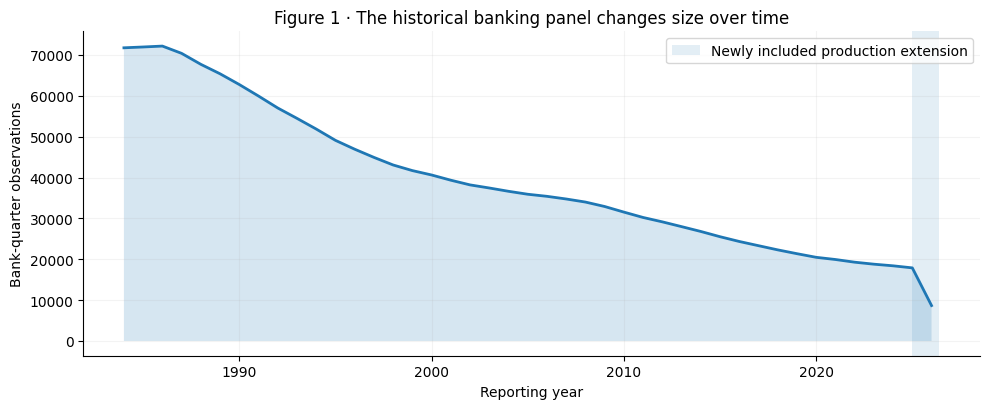

**Interpretation.** The panel peaks in 1986 (72,182 rows/year). Changes in the number of reporting institutions affect apparent aggregate trends; 2026 contains only Q1–Q2.

In [11]:
# Figure 1 — Long-run reporting population (not a duplicate of the annual table)
years = P3_YEARS['year'].to_numpy(); counts=P3_YEARS['rows'].to_numpy()
fig,ax=plt.subplots(figsize=(10,4.2))
ax.fill_between(years,counts,alpha=.18); ax.plot(years,counts,lw=2)
ax.axvspan(2025,2026.4,alpha=.12,label='Newly included production extension')
ax.set(xlabel='Reporting year',ylabel='Bank-quarter observations',
       title='Figure 1 · The historical banking panel changes size over time')
ax.legend(loc='upper right');plt.tight_layout();plt.show()
P3_FIGURES.append('figure_01_annual_population')
peak_i=np.argmax(counts)
p3_note(f'The panel peaks in {int(years[peak_i])} ({int(counts[peak_i]):,} rows/year). Changes in the number of reporting institutions affect apparent aggregate trends; 2026 contains only Q1–Q2.')

#### Chart interpretation

**Figure 1 — Interpretation.** The declining reporting population changes the absolute number of available bank-quarters over time. Compare a period’s failure counts against its eligible denominator, not the raw positive count alone.

In [12]:
# 3.2.2 — Financial-field coverage by reporting year (narrow and optional Wide pool)
P3_W1_INPUTS = ['CERT','REPDTE','ASSET','EQ','DEP','CHBAL','SC','ROA','LNLSGR','NCLNLS','COREDEP']
P3_W1_FEATURES = ['equity_to_assets','deposits_to_assets','cash_to_assets','securities_to_assets',
                  'core_deposit_share','noncurrent_loan_ratio','asset_growth_4q',
                  'roa_rolling_mean_4q','roa_rolling_std_4q']
missing_inputs = sorted(set(P3_W1_INPUTS)-set(P3_SOURCE_COLUMNS))
p3_mark('3.2 W1 raw inputs available',not missing_inputs)
P3_FINANCIAL_FIELDS = [c for c,dtype in P3_SCHEMA.items() if c in P3_PREDICTOR_POOL
    and c not in ('CERT','REPDTE') and dtype.is_numeric()]
P3_WIDE_FIELD_COUNT = len(P3_FINANCIAL_FIELDS)
P3_W1_FIN_FIELDS = P3_W1_INPUTS[2:]
coverage_lf = src.select(['REPDTE']+P3_W1_FIN_FIELDS).with_columns(
    pl.col('REPDTE').dt.year().alias('year'))
P3_FIELD_YEAR_COVERAGE = coverage_lf.group_by('year').agg(
    [pl.len().alias('rows')]+[
       (pl.col(c).is_not_null() & pl.col(c).is_finite()).sum().alias(c)
       for c in P3_W1_FIN_FIELDS]).sort('year').collect(engine='streaming')
P3_FIELD_YEAR_MISSING = P3_FIELD_YEAR_COVERAGE.to_pandas()
for c in P3_W1_FIN_FIELDS:
    P3_FIELD_YEAR_MISSING[c]=1-P3_FIELD_YEAR_MISSING[c]/P3_FIELD_YEAR_MISSING['rows']
print('Numeric financial fields for Wide research:',P3_WIDE_FIELD_COUNT)
print('W1 source missingness audit:',len(P3_W1_FIN_FIELDS),'fields ×',len(P3_FIELD_YEAR_MISSING),'years')

PASS  3.2 W1 raw inputs available
Numeric financial fields for Wide research: 133
W1 source missingness audit: 9 fields × 43 years


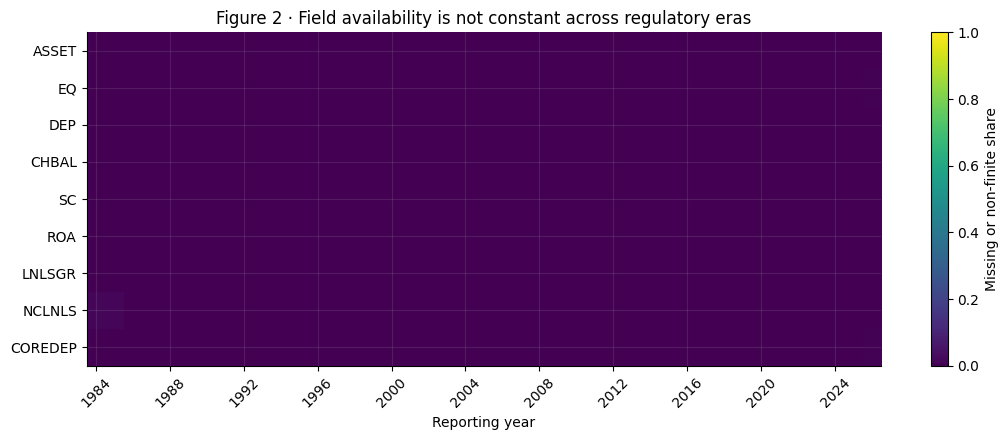

**Interpretation.** NCLNLS shows the largest annual missingness swing (1.8 percentage points). A data-quality shift may reflect reporting coverage and does not establish an economic change.

In [13]:
# Figure 2 — Missingness drift heatmap exposes reporting-regime changes
mat=P3_FIELD_YEAR_MISSING.set_index('year')[P3_W1_FIN_FIELDS].T
fig,ax=plt.subplots(figsize=(11,4.5))
img=ax.imshow(mat.to_numpy(),aspect='auto',interpolation='nearest',vmin=0,vmax=1,cmap='viridis')
ax.set_yticks(np.arange(len(mat)),labels=mat.index)
sel=np.arange(0,len(mat.columns),4)
ax.set_xticks(sel,labels=np.array(mat.columns)[sel],rotation=45)
ax.set(xlabel='Reporting year',title='Figure 2 · Field availability is not constant across regulatory eras')
fig.colorbar(img,ax=ax,label='Missing or non-finite share');plt.tight_layout();plt.show()
P3_FIGURES.append('figure_02_missingness_drift')
changes=(mat.max(axis=1)-mat.min(axis=1)).sort_values(ascending=False)
p3_note(f'{changes.index[0]} shows the largest annual missingness swing ({100*changes.iloc[0]:.1f} percentage points). A data-quality shift may reflect reporting coverage and does not establish an economic change.')

#### Chart interpretation

**Figure 2 — Interpretation.** Vertical bands of missingness indicate changing field availability across reporting regimes. These patterns argue for field-specific vintage checks and train-only missing-value policy in Phase 4.

In [14]:
# 3.2.3 — Bank history lengths and Phase 2 anomaly flags
P3_BANK_LENGTHS=(src.group_by('CERT').agg(pl.len().alias('n_quarters'))
                 .collect(engine='streaming')['n_quarters'].to_numpy())
P3_FLAG_COUNTS={}
for c in P3_AUDIT_FIELDS:
    if P3_SCHEMA[c].is_numeric():
        P3_FLAG_COUNTS[c]=int(src.select(pl.col(c).fill_null(0).sum()).collect().item())
print('Banks:',len(P3_BANK_LENGTHS),'| Bank-history median quarters:',int(np.median(P3_BANK_LENGTHS)))
print('Phase 2 audit flags:',P3_FLAG_COUNTS)
p3_mark('3.2 non-empty bank histories',len(P3_BANK_LENGTHS)>0 and np.min(P3_BANK_LENGTHS)>=1)

Banks: 24064 | Bank-history median quarters: 51
Phase 2 audit flags: {}
PASS  3.2 non-empty bank histories


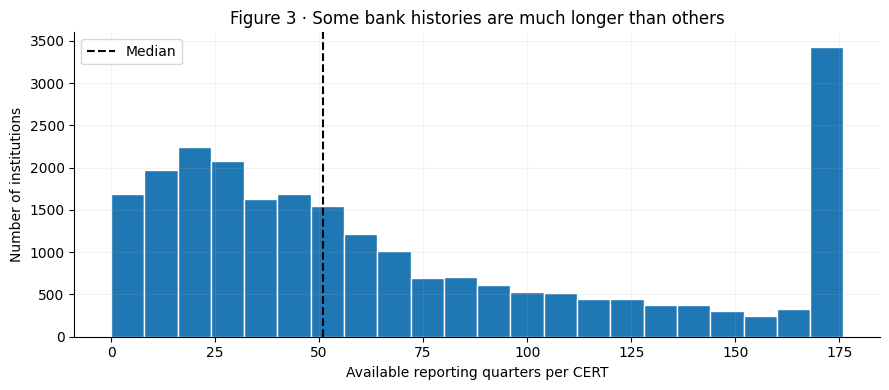

**Interpretation.** Unbalanced histories motivate calendar-aware lags and skew diagnostics; this figure is **not** evidence of observed Spark task skew.

In [15]:
# Figure 3 — History-length distribution (why window/shuffle skew is plausible)
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(P3_BANK_LENGTHS,bins=np.arange(0,max(P3_BANK_LENGTHS)+9,8),edgecolor='white')
ax.axvline(np.median(P3_BANK_LENGTHS),linestyle='--',color='black',label='Median')
ax.set(xlabel='Available reporting quarters per CERT',ylabel='Number of institutions',
       title='Figure 3 · Some bank histories are much longer than others')
ax.legend();plt.tight_layout();plt.show()
P3_FIGURES.append('figure_03_bank_history_skew')
p3_note('Unbalanced histories motivate calendar-aware lags and skew diagnostics; this figure is **not** evidence of observed Spark task skew.')

### 3.2.4 — Financial records versus label maturity

The Silver file extends to 2026Q2, but incomplete four-quarter outcomes must remain ineligible. The next chart visualizes the two separate coverage boundaries.

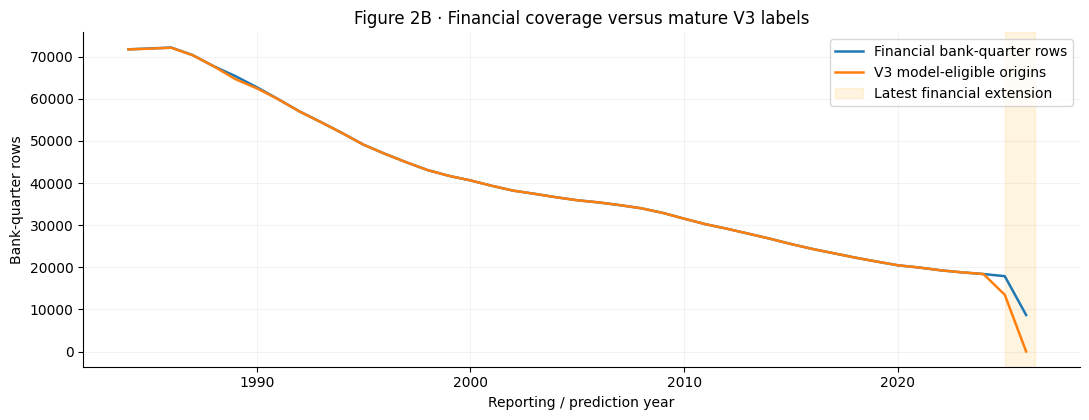

**Interpretation.** The lines separate **financial availability** from **observed 4Q outcomes**. A reporting quarter without mature labels can still be processed for future scoring, but must not be silently assigned y=0.

In [16]:
# Figure 2B — Financial history versus V3-eligible prediction origins
# The plot complements annual source counts: it shows the OBSERVABILITY gap.
_p3_fin=P3_YEARS.select('year','rows').to_pandas().rename(columns={'rows':'financial_rows'})
_p3_av=_p3_fin.merge(P3_V3_YEAR_AUDIT[['year','eligible_rows','eligible_y1']],on='year',how='left')
_p3_av[['eligible_rows','eligible_y1']]=_p3_av[['eligible_rows','eligible_y1']].fillna(0)
fig,ax=plt.subplots(figsize=(11,4.3))
ax.plot(_p3_av.year,_p3_av.financial_rows,label='Financial bank-quarter rows',lw=1.8)
ax.plot(_p3_av.year,_p3_av.eligible_rows,label='V3 model-eligible origins',lw=1.8)
ax.axvspan(2025,2026.4,color='orange',alpha=.12,label='Latest financial extension')
ax.set(xlabel='Reporting / prediction year',ylabel='Bank-quarter rows',
       title='Figure 2B · Financial coverage versus mature V3 labels')
ax.legend(loc='upper right');plt.tight_layout();plt.show()
if 'figure_02b_financial_vs_label_maturity' not in P3_FIGURES:
    P3_FIGURES.append('figure_02b_financial_vs_label_maturity')
p3_note('The lines separate **financial availability** from **observed 4Q outcomes**. '
        'A reporting quarter without mature labels can still be processed for future scoring, '
        'but must not be silently assigned y=0.')


#### Chart interpretation

**Figure 3 — Interpretation.** Unequal bank-history length makes row counts an imperfect proxy for independent institutions and can cause skew for window/shuffle operations. Preserve complete bank histories in scaling experiments.

#### Interpretation — Panel audit

The source extends to 2026Q2, but the target does not mature at the same date. The 1984 rows supply historical lookback; the W1 production begins in 1985. Missingness can reflect changes in reporting fields, not necessarily bank distress.

<a id="p3-3"></a>
## 3.3 — W1 financial feature specification

Calculate six ratios plus three calendar-aware historical features using nine declared outputs. Reject invalid denominators; do not infer a missing quarter as a real financial zero.

In [17]:
# 3.3.1 — Feature formulas, missing-data policy and semantic status
P3_W1_RATIO_RULES={
 'equity_to_assets':('EQ','ASSET'), 'deposits_to_assets':('DEP','ASSET'),
 'cash_to_assets':('CHBAL','ASSET'), 'securities_to_assets':('SC','ASSET'),
 'core_deposit_share':('COREDEP','DEP'),
 'noncurrent_loan_ratio':('NCLNLS','LNLSGR')}
P3_W1_RULES={
 'ratio':'finite numerator + finite strictly-positive denominator; null otherwise',
 'asset_growth_4q':'ASSET(t) / ASSET(t-4 calendar quarters) - 1; valid finite current and positive finite lag',
 'roa_rolling_mean_4q':'mean of ROA(t), ROA(t-1Q), ROA(t-2Q), ROA(t-3Q); all four required',
 'roa_rolling_std_4q':'sample standard deviation, ddof=1; all four quarters required',
 'missing_quarter':'null, without row-based imputation',
 'output_date_range':'1985Q1–2026Q2 (1984 included only as lookback)',
 'numeric_tolerance':{'atol':1e-8,'rtol':1e-6}}
P3_FIELD_SEMANTICS={
 'NCLNLS':'FDIC-reported count/amount of 90+ past due and nonaccrual loans and leases; historical TFR caveat',
 'LNLSGR':'FDIC loans and leases before allowance, net of unearned income',
 'noncurrent_loan_ratio':'PROVISIONAL derivative NCLNLS/LNLSGR; decimal fraction, not FDIC published NCLNLSR percent'}
P3_SEMANTIC_PROVISIONAL=True
p3_mark('3.3 nine distinct features and six ratios',len(set(P3_W1_FEATURES))==9 and len(P3_W1_RATIO_RULES)==6)
print('Noncurrent loan ratio: PROVISIONAL; verify against official NCLNLSR and historical reporting vintages before predictive interpretation.')

PASS  3.3 nine distinct features and six ratios
Noncurrent loan ratio: PROVISIONAL; verify against official NCLNLSR and historical reporting vintages before predictive interpretation.


#### Interpretation — Meaning of the noncurrent-loan ratio

`NCLNLS / LNLSGR` is a *derived fraction*; FDIC `NCLNLSR` may be reported as a percentage. Numerical parity is not proof of identical accounting definitions across 1984–2026. Keep the derived measure **provisional** for Phase 4 sensitivity testing.

### 3.3.2 — Optional FDIC published-ratio crosswalk

When `NCLNLSR` exists, compare it with the derived series. This diagnostic cannot by itself certify historical semantic consistency.

In [18]:
# 3.3.2 — Optional NCLNLSR crosswalk; preserve the provisional warning
if 'NCLNLSR' in P3_SOURCE_COLUMNS:
    audit=(src.filter(pl.col('REPDTE').dt.year().is_in([1990,2005,2024,2025,2026]))
       .select('REPDTE','NCLNLS','LNLSGR','NCLNLSR')
       .with_columns(pl.when(pl.col('NCLNLS').is_finite() & pl.col('LNLSGR').is_finite() &
                             (pl.col('LNLSGR')>0))
                      .then(100*pl.col('NCLNLS')/pl.col('LNLSGR')).otherwise(None).alias('computed_pct'))
       .with_columns((pl.col('computed_pct')-pl.col('NCLNLSR')).abs().alias('abs_pct_point_gap'))
       .group_by(pl.col('REPDTE').dt.year().alias('year'))
       .agg(pl.len().alias('rows'),pl.col('abs_pct_point_gap').is_not_null().sum().alias('comparable'),
            pl.col('abs_pct_point_gap').median().alias('median_gap_pp'),
            pl.col('abs_pct_point_gap').quantile(.95).alias('p95_gap_pp'))
       .sort('year').collect(engine='streaming'))
    display(audit)
    P3_EXPERIMENTS['NCLNLSR_crosswalk']={'status':'DIAGNOSTIC_ONLY','comparison_years':audit.height}
else:
    print('NCLNLSR not supplied in canonical Silver: crosswalk SKIPPED, cannot certify historic semantics.')
    P3_EXPERIMENTS['NCLNLSR_crosswalk']={'status':'NOT_AVAILABLE_IN_SILVER'}
print('Semantic status remains PROVISIONAL regardless of arithmetic agreement.')

NCLNLSR not supplied in canonical Silver: crosswalk SKIPPED, cannot certify historic semantics.
Semantic status remains PROVISIONAL regardless of arithmetic agreement.


<a id="p3-4"></a>
## 3.4 — Independent feature engines

Implement the calendar-aware Polars pipeline, an explicit join-based baseline and an independent pandas calculation. All three use **raw financial inputs**, never outcome columns.

In [19]:
# 3.4.1 — Polars calendar-aware W1 with exact-quarter lag safeguards
from datetime import date as _date

def p3_source_lazy(source=None):
    if source is None: return pl.scan_parquet(str(P3_SILVER_PATH))
    if isinstance(source,pl.LazyFrame): return source
    if isinstance(source,pl.DataFrame): return source.lazy()
    return pl.scan_parquet(str(source))

def p3_quarter_lag(value_col,lag):
    return pl.coalesce([
        pl.when((pl.col('qi')-pl.col(f'prev_q{k}'))==lag)
          .then(pl.col(f'{value_col}_shift{k}')).otherwise(None)
        for k in range(1,lag+1)])

def p3_w1_window(start_year=1985,end_year=2026,source=None):
    if not (1985<=start_year<=end_year<=2026):
        raise ValueError('Output year range must lie inside 1985–2026')
    end_date=P3_CFG['financial_last'] if end_year==2026 else _date(end_year,12,31)
    base=(p3_source_lazy(source)
          .filter(pl.col('REPDTE').is_between(_date(start_year-1,1,1),end_date))
          .select(P3_W1_INPUTS)
          .with_columns((pl.col('REPDTE').dt.year()*4+pl.col('REPDTE').dt.quarter()).alias('qi'))
          .sort(['CERT','REPDTE']))
    shifts=[]
    for k in range(1,5):
        shifts.extend([pl.col('qi').shift(k).over('CERT').alias(f'prev_q{k}'),
                       pl.col('ASSET').shift(k).over('CERT').alias(f'ASSET_shift{k}'),
                       pl.col('ROA').shift(k).over('CERT').alias(f'ROA_shift{k}')])
    w=base.with_columns(shifts)
    ratios=[]
    for feature,(num,den) in P3_W1_RATIO_RULES.items():
        ok=pl.col(num).is_finite() & pl.col(den).is_finite() & (pl.col(den)>0)
        ratios.append(pl.when(ok).then(pl.col(num)/pl.col(den)).otherwise(None).alias(feature))
    w=w.with_columns(ratios+[p3_quarter_lag('ASSET',4).alias('_asset_4q')])
    g_ok=pl.col('ASSET').is_finite() & pl.col('_asset_4q').is_finite() & (pl.col('_asset_4q')>0)
    w=w.with_columns(pl.when(g_ok).then(pl.col('ASSET')/pl.col('_asset_4q')-1)
                     .otherwise(None).alias('asset_growth_4q'))
    w=w.with_columns([pl.col('ROA').alias('_roa0')]+[
        p3_quarter_lag('ROA',k).alias(f'_roa{k}') for k in range(1,4)])
    roa=[f'_roa{k}' for k in range(4)]
    ok=pl.all_horizontal([pl.col(c).is_finite() for c in roa])
    w=w.with_columns(pl.when(ok).then(pl.sum_horizontal([pl.col(c) for c in roa])/4.0)
                     .otherwise(None).alias('roa_rolling_mean_4q'))
    w=w.with_columns(pl.when(ok).then((pl.sum_horizontal([
       (pl.col(c)-pl.col('roa_rolling_mean_4q'))**2 for c in roa])/3).sqrt())
       .otherwise(None).alias('roa_rolling_std_4q'))
    return (w.filter(pl.col('REPDTE')>=_date(start_year,1,1))
             .select(['CERT','REPDTE']+P3_W1_FEATURES).sort(['CERT','REPDTE']))

P3_NO_PUSHDOWN=pl.QueryOptFlags(predicate_pushdown=False)
def p3_collect(lf): return lf.collect(engine='streaming',optimizations=P3_NO_PUSHDOWN)
print('Calendar-aware W1 ready; output window: 1985Q1–2026Q2.')

Calendar-aware W1 ready; output window: 1985Q1–2026Q2.


In [20]:
# 3.4.2 — Explicit four-join baseline (for controlled optimizer A/B)
def p3_w1_join(start_year=1985,end_year=2026,source=None):
    end_date=P3_CFG['financial_last'] if end_year==2026 else _date(end_year,12,31)
    base=(p3_source_lazy(source)
       .filter(pl.col('REPDTE').is_between(_date(start_year-1,1,1),end_date))
       .select(P3_W1_INPUTS)
       .with_columns((pl.col('REPDTE').dt.year()*4+pl.col('REPDTE').dt.quarter()).alias('qi')))
    w=base
    for k in range(1,5):
        col='ASSET' if k==4 else 'ROA'
        other=(base.select('CERT','qi',col).with_columns((pl.col('qi')+k).alias('qi'))
               .rename({col:f'_lag{k}'}))
        w=w.join(other,on=['CERT','qi'],how='left')
    for feature,(num,den) in P3_W1_RATIO_RULES.items():
        valid=pl.col(num).is_finite() & pl.col(den).is_finite() & (pl.col(den)>0)
        w=w.with_columns(pl.when(valid).then(pl.col(num)/pl.col(den))
                           .otherwise(None).alias(feature))
    valid=pl.col('ASSET').is_finite() & pl.col('_lag4').is_finite() & (pl.col('_lag4')>0)
    w=w.with_columns(pl.when(valid).then(pl.col('ASSET')/pl.col('_lag4')-1)
                     .otherwise(None).alias('asset_growth_4q'))
    columns=['ROA','_lag1','_lag2','_lag3']
    complete=pl.all_horizontal([pl.col(c).is_finite() for c in columns])
    w=w.with_columns(pl.when(complete).then(pl.sum_horizontal([pl.col(c) for c in columns])/4)
                     .otherwise(None).alias('roa_rolling_mean_4q'))
    w=w.with_columns(pl.when(complete).then((pl.sum_horizontal([
       (pl.col(c)-pl.col('roa_rolling_mean_4q'))**2 for c in columns])/3).sqrt())
       .otherwise(None).alias('roa_rolling_std_4q'))
    return (w.filter(pl.col('REPDTE')>=_date(start_year,1,1))
             .select(['CERT','REPDTE']+P3_W1_FEATURES).sort(['CERT','REPDTE']))
print('Independent four-join baseline ready.')

Independent four-join baseline ready.


In [21]:
# 3.4.3 — Independent pandas implementation: exact quarter-key merges
# Input is raw financial fields ONLY. Never compare against transformed Polars values to generate features.
def p3_pandas_w1(raw,start_year,end_year):
    x=raw[P3_W1_INPUTS].copy()
    x['REPDTE']=pd.to_datetime(x['REPDTE'])
    if x.duplicated(['CERT','REPDTE']).any(): raise AssertionError('Duplicate source keys')
    x['qi']=x['REPDTE'].dt.year*4+x['REPDTE'].dt.quarter
    for c in P3_W1_INPUTS[2:]: x[c]=pd.to_numeric(x[c],errors='raise').astype('float64')
    for k in range(1,5):
        c='ASSET' if k==4 else 'ROA'
        lookup=x[['CERT','qi',c]].rename(columns={'qi':f'_qi{k}',c:f'_lag{k}'})
        x[f'_seek{k}']=x['qi']-k
        x=x.merge(lookup,left_on=['CERT',f'_seek{k}'],right_on=['CERT',f'_qi{k}'],
                  how='left',sort=False,validate='one_to_one')
        x=x.drop(columns=[f'_seek{k}',f'_qi{k}'])
    for feature,(n,d) in P3_W1_RATIO_RULES.items():
        v=np.isfinite(x[n]) & np.isfinite(x[d]) & (x[d]>0)
        x[feature]=(x[n]/x[d]).where(v,np.nan)
    g=np.isfinite(x['ASSET']) & np.isfinite(x['_lag4']) & (x['_lag4']>0)
    x['asset_growth_4q']=(x['ASSET']/x['_lag4']-1).where(g,np.nan)
    r=x[['ROA','_lag1','_lag2','_lag3']]
    complete=np.isfinite(r.to_numpy(dtype='float64')).all(axis=1)
    x['roa_rolling_mean_4q']=r.mean(axis=1).where(complete,np.nan)
    x['roa_rolling_std_4q']=r.std(axis=1,ddof=1).where(complete,np.nan)
    x=x.loc[x.REPDTE.dt.year.between(start_year,end_year),
            ['CERT','REPDTE']+P3_W1_FEATURES]
    return x.sort_values(['CERT','REPDTE']).reset_index(drop=True)

# A small 2024 contract smoke check before full-history computation.
pilot_raw=(src.filter(pl.col('REPDTE').is_between(_date(2023,1,1),_date(2024,12,31)))
           .select(P3_W1_INPUTS).collect(engine='streaming').to_pandas())
pilot_pd=p3_pandas_w1(pilot_raw,2024,2024)
pilot_pl=p3_collect(p3_w1_window(2024,2024)).to_pandas()
assert len(pilot_pd)==len(pilot_pl)==18399
print('Pandas 2024 pilot:',len(pilot_pd),'rows; independent implementation ready.')
del pilot_raw,pilot_pd,pilot_pl;gc.collect()

Pandas 2024 pilot: 18399 rows; independent implementation ready.


3432

### 3.4.4 — Wide historical reporting workload

Batch field-year statistics over the source financial columns. This is a **column scalability** experiment, not another model-feature or label pipeline.

In [22]:
# 3.4.4 — Full-history Wide W2: year × financial-field quality statistics (bounded column batches)
# LOWMEM advanced workload: use every numeric Phase 0 financial field, not only nine W1 raw values.
P3_WIDE_ANNUAL=pd.DataFrame()
if P3_CFG['run_optional_wide']:
    records=[];batch_width=20
    for offset in range(0,len(P3_FINANCIAL_FIELDS),batch_width):
        fields=P3_FINANCIAL_FIELDS[offset:offset+batch_width]
        expr=[pl.len().alias('n_rows')]
        for c in fields:
            f=pl.col(c).cast(pl.Float64,strict=False)
            expr.extend([f.is_finite().sum().alias(c+'__finite'),
                         f.filter(f.is_finite()).mean().alias(c+'__mean'),
                         f.filter(f.is_finite()).std().alias(c+'__std')])
        batch=(src.group_by(pl.col('REPDTE').dt.year().alias('year'))
               .agg(expr).sort('year').collect(engine='streaming').to_pandas())
        for field in fields:
            for row in batch.itertuples(index=False):
                d=row._asdict()
                records.append({'year':int(d['year']),'field':field,'n_rows':int(d['n_rows']),
                   'finite_count':int(d[field+'__finite']),
                   'missing_count':int(d['n_rows']-d[field+'__finite']),
                   'mean':d[field+'__mean'],'std':d[field+'__std']})
        del batch;gc.collect()
    P3_WIDE_ANNUAL=pd.DataFrame(records)
    p3_mark('3.4 full-source Wide W2 annual profiling',
       len(P3_WIDE_ANNUAL)==43*len(P3_FINANCIAL_FIELDS) and
       P3_WIDE_ANNUAL.groupby('field').year.nunique().eq(43).all())
    P3_EXPERIMENTS['wide']={'status':'PASS','year_field_rows':len(P3_WIDE_ANNUAL)}
    print('Wide stats:',len(P3_WIDE_ANNUAL),'year×field records; 2026 is Q1–Q2 only')
else:
    P3_EXPERIMENTS['wide']={'status':'SKIPPED_BY_POLICY'}
    print('Wide profiling skipped by policy.')

PASS  3.4 full-source Wide W2 annual profiling
Wide stats: 5719 year×field records; 2026 is Q1–Q2 only


<a id="p3-5"></a>
## 3.5 — Full-history numerical equivalence

Check independent pandas ↔ Polars parity across the entire production interval (1985Q1–2026Q2), with a one-year lookback for each block.

In [23]:
# 3.5.1 — Error-audit helper (keys, null patterns, numerical tolerance)
def p3_compare_frames(pandas_df,polars_df,tag='block'):
    a=pandas_df.copy()
    b=polars_df.to_pandas() if isinstance(polars_df,pl.DataFrame) else polars_df.copy()
    for d in (a,b):
        d['REPDTE']=pd.to_datetime(d['REPDTE'])
        assert not d.duplicated(['CERT','REPDTE']).any(),f'{tag}: duplicate output keys'
    combined=a.merge(b,on=['CERT','REPDTE'],how='outer',suffixes=('_pd','_pl'),
                     indicator=True,validate='one_to_one')
    key_errors=int((combined['_merge']!='both').sum())
    m=combined[combined['_merge']=='both']
    rows=[]
    for f in P3_W1_FEATURES:
        lhs=m[f+'_pd'].to_numpy(dtype='float64');rhs=m[f+'_pl'].to_numpy(dtype='float64')
        ln=pd.isna(lhs);rn=pd.isna(rhs)
        valid=np.isfinite(lhs)&np.isfinite(rhs)
        residual=np.abs(lhs[valid]-rhs[valid])
        allowed=1e-8+1e-6*np.abs(rhs[valid])
        rows.append(dict(block=tag,feature=f,compared=len(m),both_null=int((ln&rn).sum()),
          null_errors=int((ln^rn).sum()),numeric_errors=int((residual>allowed).sum()),
          nonfinite_errors=int(((~ln&~np.isfinite(lhs))|(~rn&~np.isfinite(rhs))).sum()),
          max_abs_error=float(residual.max()) if len(residual) else 0.))
    return key_errors,pd.DataFrame(rows)

P3_PARITY_BLOCKS=[(s,min(s+4,2026)) for s in range(1985,2027,5)]
print('Full-history independent parity blocks:',P3_PARITY_BLOCKS)

Full-history independent parity blocks: [(1985, 1989), (1990, 1994), (1995, 1999), (2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019), (2020, 2024), (2025, 2026)]


In [24]:
# 3.5.2 — Run independent pandas↔Polars parity with 1-year lookback per block
P3_PARITY_RECORDS=[];P3_PARITY_KEY_ERRORS=0
for block_start,block_end in P3_PARITY_BLOCKS:
    tag=f'{block_start}–{block_end}'
    raw=(src.filter(pl.col('REPDTE').is_between(_date(block_start-1,1,1),
              P3_CFG['financial_last'] if block_end==2026 else _date(block_end,12,31)))
          .select(P3_W1_INPUTS).collect(engine='streaming').to_pandas())
    independent=p3_pandas_w1(raw,block_start,block_end)
    optimized=p3_collect(p3_w1_window(block_start,block_end))
    key_errors,report=p3_compare_frames(independent,optimized,tag)
    audited=int(P3_YEARS.filter(pl.col('year').is_between(block_start,block_end))['rows'].sum())
    if len(independent)!=audited or optimized.height!=audited:
        raise AssertionError(f'{tag}: expected {audited}, pandas {len(independent)}, Polars {optimized.height}')
    P3_PARITY_RECORDS.extend(report.to_dict('records'))
    P3_PARITY_KEY_ERRORS+=key_errors
    print(tag,'rows=',audited,'key_errors=',key_errors,'failed_features=',
          int(((report.null_errors+report.numeric_errors+report.nonfinite_errors)>0).sum()))
    del raw,independent,optimized,report;gc.collect()
P3_PARITY_DETAIL=pd.DataFrame(P3_PARITY_RECORDS)
P3_PARITY_REPORT=P3_PARITY_DETAIL.groupby('feature',as_index=False).agg(
    compared=('compared','sum'),both_null=('both_null','sum'),
    null_errors=('null_errors','sum'),numeric_errors=('numeric_errors','sum'),
    nonfinite_errors=('nonfinite_errors','sum'),max_abs_error=('max_abs_error','max'))
P3_PARITY_ALL_PASS=(P3_PARITY_KEY_ERRORS==0 and
    P3_PARITY_REPORT['compared'].eq(P3_EXPECTED_PRODUCTION_ROWS).all() and
    P3_PARITY_REPORT[['null_errors','numeric_errors','nonfinite_errors']].to_numpy().sum()==0)
display(P3_PARITY_REPORT)
p3_mark('3.5 full financial history independent parity',P3_PARITY_ALL_PASS)
print('CERT/REPDTE unmatched keys:',P3_PARITY_KEY_ERRORS,'| Full output records:',P3_EXPECTED_PRODUCTION_ROWS)

1985–1989 rows= 347654 key_errors= 0 failed_features= 0
1990–1994 rows= 286105 key_errors= 0 failed_features= 0
1995–1999 rows= 225775 key_errors= 0 failed_features= 0
2000–2004 rows= 192271 key_errors= 0 failed_features= 0
2005–2009 rows= 172995 key_errors= 0 failed_features= 0
2010–2014 rows= 145726 key_errors= 0 failed_features= 0
2015–2019 rows= 116869 key_errors= 0 failed_features= 0
2020–2024 rows= 96902 key_errors= 0 failed_features= 0
2025–2026 rows= 26559 key_errors= 0 failed_features= 0


,feature,compared,both_null,null_errors,numeric_errors,nonfinite_errors,max_abs_error
0,asset_growth_4q,1610856,23101,0,0,0,0.000000e+00
1,cash_to_assets,1610856,1,0,0,0,0.000000e+00
2,core_deposit_share,1610856,13164,0,0,0,0.000000e+00
3,deposits_to_assets,1610856,1,0,0,0,0.000000e+00
4,equity_to_assets,1610856,4033,0,0,0,0.000000e+00
5,noncurrent_loan_ratio,1610856,20126,0,0,0,0.000000e+00
6,roa_rolling_mean_4q,1610856,17398,0,0,0,1.136868e-13
7,roa_rolling_std_4q,1610856,17398,0,0,0,5.684342e-14
8,securities_to_assets,1610856,1,0,0,0,0.000000e+00


PASS  3.5 full financial history independent parity
CERT/REPDTE unmatched keys: 0 | Full output records: 1610856


In [25]:
# 3.5.3 — Validate newly added 2025–2026Q2 time coverage and continuity
latest=p3_collect(p3_w1_window(2025,2026))
latest_counts=latest.group_by(pl.col('REPDTE').dt.year().alias('year')).agg(
    pl.len().alias('rows'),pl.col('asset_growth_4q').null_count().alias('asset_growth_null'),
    pl.col('roa_rolling_mean_4q').null_count().alias('roa_roll_null')).sort('year')
latest_expected=P3_YEARS.filter(pl.col('year')>=2025).select('year','rows')
latest_audit=latest_counts.join(latest_expected,on='year',how='inner',suffix='_expected')
P3_EXT_PASS=(latest_audit.height==2 and
    latest_audit['rows'].to_list()==latest_audit['rows_expected'].to_list() and
    latest['REPDTE'].max()==P3_CFG['financial_last'])
display(latest_audit)
p3_mark('3.5 2025–2026Q2 extension validated',P3_EXT_PASS)
P3_EXTENSION_ROWS=int(latest.height)
print('New observations beyond 2024:',P3_EXTENSION_ROWS,
      '| Provisional loan-quality feature remains provisional.')
del latest;gc.collect()

year,rows,asset_growth_null,roa_roll_null,rows_expected
i32,u32,u32,u32,u32
2025,17893,34,25,17893
2026,8666,16,15,8666


PASS  3.5 2025–2026Q2 extension validated
New observations beyond 2024: 26559 | Provisional loan-quality feature remains provisional.


0

#### Interpretation — What parity proves

A pass means the two implementations agree on keys, nulls and finite feature values at the tested tolerance. It does **not** verify historical reporting vintages, loan-ratio semantics or model leakage after the later Phase 4 merge.

<a id="p3-6"></a>
## 3.6 — Runtime and memory benchmarks

Benchmark identical workloads over 8, 16, 32 and 42-year horizons; report repeated timing distributions and sampled process memory rather than a single best run.

### Archived evidence A — Calendar-window speedup across four scales

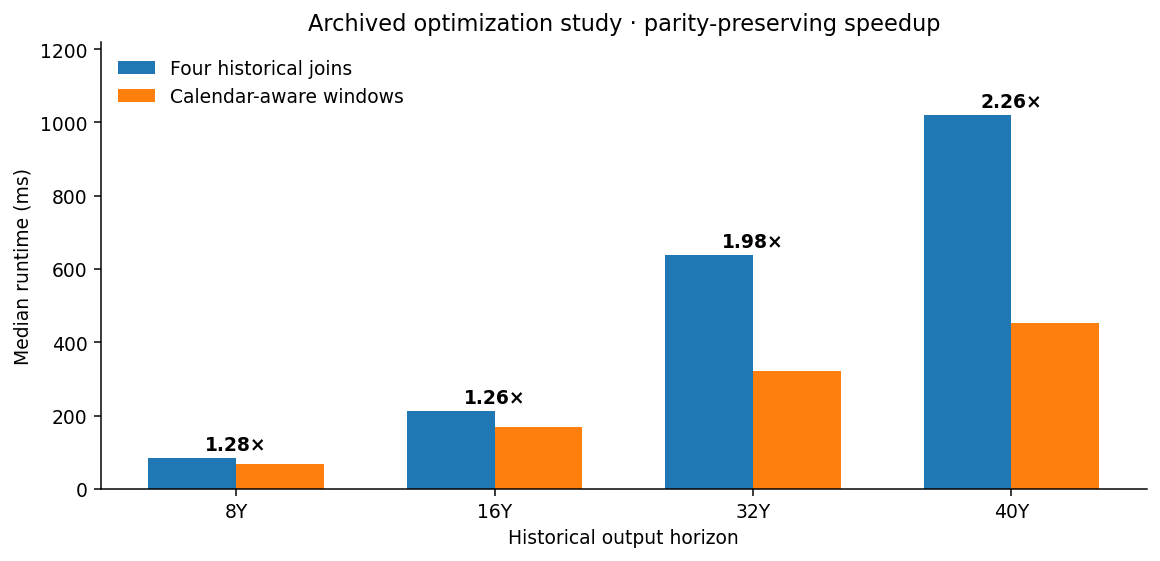

**Reading:** the speedup rises to **2.26× at 40 years** while every paired horizon passed numerical parity. These are not 2026Q2 timings; current-run benchmarks below recompute 8Y/16Y/32Y.

*Figure uses archived measurements from the executed input notebook; new current-run charts appear below and must be run locally.*

In [26]:
# 3.6.1 — Common measurement helper and resource-conscious scope
import threading

def p3_measure(workload):
    proc=psutil.Process(os.getpid());gc.collect();base=proc.memory_info().rss
    samples=[base];stop=threading.Event()
    def sample():
        while not stop.wait(0.01):
            try: samples.append(proc.memory_info().rss)
            except psutil.Error: break
    worker=threading.Thread(target=sample,daemon=True);worker.start();start=time.perf_counter()
    try:
        result=workload();elapsed=(time.perf_counter()-start)*1000
        rows=int(result.height) if isinstance(result,pl.DataFrame) else int(result)
    finally:
        samples.append(proc.memory_info().rss);stop.set();worker.join()
    del result;gc.collect()
    peak=max(samples)
    return {'runtime_ms':elapsed,'rows':rows,'peak_rss_mib':peak/2**20,
            'baseline_rss_mib':base/2**20,'incremental_rss_mib':(peak-base)/2**20,
            'rss_samples':len(samples)}


P3_BENCH_SCOPES = [
    {'horizon': 8,  'start': 2017, 'end': 2024},
    {'horizon': 16, 'start': 2009, 'end': 2024},
    {'horizon': 32, 'start': 1993, 'end': 2024},
    {'horizon': 42, 'start': 1985, 'end': 2026},
]

assert [
    x['horizon'] for x in P3_BENCH_SCOPES
] == [8, 16, 32, 42]

assert all(
    x['end'] - x['start'] + 1 == x['horizon']
    for x in P3_BENCH_SCOPES
)

P3_BENCH_HORIZONS = [
    x['horizon'] for x in P3_BENCH_SCOPES
]

P3_BENCH_WORKLOADS = {
    'four_join': p3_w1_join,
    'calendar_window': p3_w1_window
}

P3_BENCH_RESULTS = []

print(
    'Unified W1 scopes:',
    [(s['horizon'], s['start'], s['end'])
     for s in P3_BENCH_SCOPES]
)

print(
    '1984 is raw lag history, NOT a 43rd W1 output year; '
    '2026 ends at Q2.'
)


Unified W1 scopes: [(8, 2017, 2024), (16, 2009, 2024), (32, 1993, 2024), (42, 1985, 2026)]
1984 is raw lag history, NOT a 43rd W1 output year; 2026 ends at Q2.


In [27]:

# 3.6.2 — Unified 8Y / 16Y / 32Y / 42Y benchmark

P3_BENCH_RESULTS = []

for scope in P3_BENCH_SCOPES:

    horizon = scope['horizon']
    first = scope['start']
    last = scope['end']

    expected = int(
        P3_YEARS
        .filter(pl.col('year').is_between(first, last))
        ['rows'].sum()
    )

    if horizon == 42:
        assert (first, last) == (1985, 2026)
        assert expected == P3_EXPECTED_PRODUCTION_ROWS

    for name, builder in P3_BENCH_WORKLOADS.items():

        # Warm-up
        for _ in range(P3_CFG['benchmark_warmups']):
            warm = p3_collect(builder(first, last))
            assert warm.height == expected
            del warm
            gc.collect()

        # Repeated measurements
        for rep in range(1, P3_CFG['benchmark_reps'] + 1):

            m = p3_measure(
                lambda b=builder, a=first, z=last:
                p3_collect(b(a, z))
            )

            P3_BENCH_RESULTS.append({
                'horizon': horizon,
                'start_year': first,
                'end_year': last,
                'engine': name,
                'repetition': rep,
                'expected': expected,
                'correct': m['rows'] == expected,
                **m
            })

    print(
        f'{horizon}Y ({first}-{last}): '
        f'{expected:,} rows | benchmark completed'
    )

# Combine results
P3_BENCH_RAW = pd.DataFrame(P3_BENCH_RESULTS)

P3_BENCH_SUM = (
    P3_BENCH_RAW
    .groupby(['horizon', 'engine'], as_index=False)
    .agg(
        reps=('repetition', 'count'),
        rows=('rows', 'first'),
        median_ms=('runtime_ms', 'median'),
        min_ms=('runtime_ms', 'min'),
        max_ms=('runtime_ms', 'max'),
        sampled_peak_mib=('peak_rss_mib', 'median'),
        correct=('correct', 'all')
    )
)

P3_BENCH_SUM['rows_per_s'] = (
    1000 * P3_BENCH_SUM['rows']
    / P3_BENCH_SUM['median_ms']
)

# Validation gate
expected_runs = (
    len(P3_BENCH_SCOPES)
    * len(P3_BENCH_WORKLOADS)
    * P3_CFG['benchmark_reps']
)

benchmark_pass = bool(
    len(P3_BENCH_RAW) == expected_runs
    and P3_BENCH_RAW['correct'].all()
    and P3_BENCH_RAW['runtime_ms'].gt(0).all()
    and P3_BENCH_SUM['reps'].eq(
        P3_CFG['benchmark_reps']
    ).all()
    and set(P3_BENCH_SUM.horizon) == {8, 16, 32, 42}
    and P3_BENCH_SUM.query('horizon == 42')['rows']
       .eq(P3_EXPECTED_PRODUCTION_ROWS).all()
)

p3_mark(
    '3.6 repeated runtime and sampled RSS',
    benchmark_pass
)

display(P3_BENCH_SUM.round(2))

P3_EXPERIMENTS['w1_operator_8_16_32_42'] = {
    'status': 'PASS',
    'horizons': P3_BENCH_HORIZONS,
    'full_history_output_rows': P3_EXPECTED_PRODUCTION_ROWS,
    '2026_partial_year': 'Q1-Q2',
    'repetitions': int(P3_CFG['benchmark_reps'])
}


8Y (2017-2024): 163,894 rows | benchmark completed
16Y (2009-2024): 392,413 rows | benchmark completed
32Y (1993-2024): 1,056,900 rows | benchmark completed
42Y (1985-2026): 1,610,856 rows | benchmark completed
PASS  3.6 repeated runtime and sampled RSS


,horizon,engine,reps,rows,median_ms,min_ms,max_ms,sampled_peak_mib,correct,rows_per_s
0,8,calendar_window,3,163894,227.75,184.51,232.68,1487.12,True,719635.35
1,8,four_join,3,163894,137.83,122.61,138.26,1368.04,True,1189120.64
2,16,calendar_window,3,392413,323.86,268.56,389.08,1652.38,True,1211669.19
3,16,four_join,3,392413,293.10,277.84,376.23,1680.70,True,1338815.56
4,32,calendar_window,3,1056900,476.35,406.60,486.48,2110.51,True,2218766.28
5,32,four_join,3,1056900,731.67,701.50,816.08,1996.98,True,1444498.14
6,42,calendar_window,3,1610856,622.76,607.92,638.50,2266.88,True,2586626.83
7,42,four_join,3,1610856,1043.60,1005.59,1079.54,2241.26,True,1543558.40


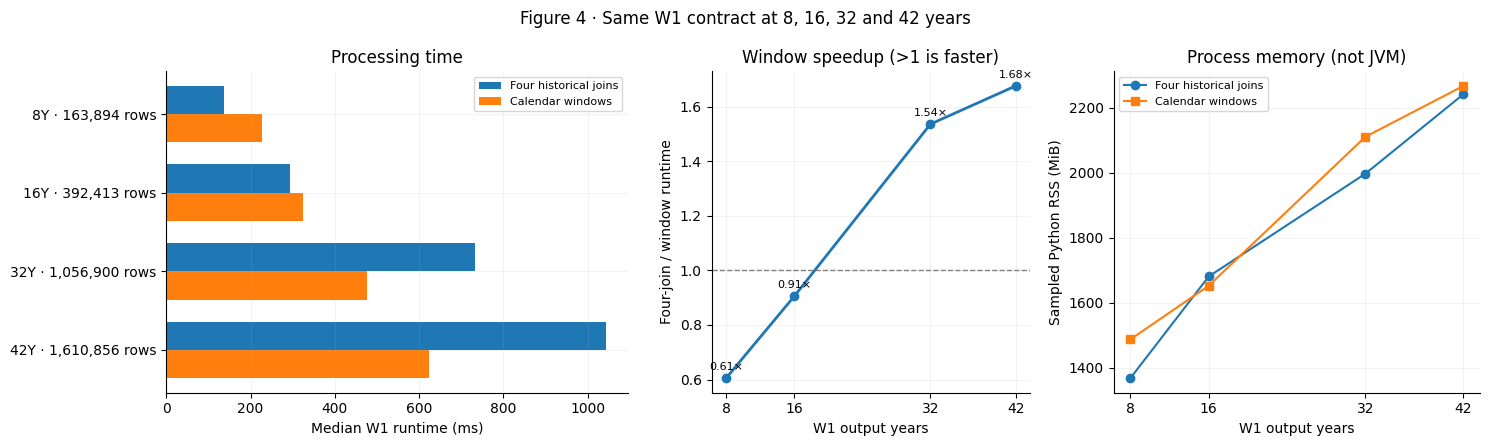

**Interpretation.** Calendar-window faster at 2/4 measured scales. At 42Y, observed speedup is 1.68× on 1,610,856 rows. RSS refers to Python process memory, not Spark JVM memory.

In [28]:

# Figure 4 — Consolidated W1 benchmark comparison

pivot = P3_BENCH_SUM.pivot(
    index='horizon',
    columns='engine',
    values='median_ms'
)

ratio = pivot['four_join'] / pivot['calendar_window']

rss = P3_BENCH_SUM.pivot(
    index='horizon',
    columns='engine',
    values='sampled_peak_mib'
)

scopes = np.array(pivot.index)
y = np.arange(len(scopes))
h = 0.36

fig, (a, b, c) = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    gridspec_kw={'width_ratios': [1.45, 1, 1.15]}
)

# Panel A — Runtime
a.barh(
    y - h / 2,
    pivot['four_join'],
    h,
    label='Four historical joins'
)

a.barh(
    y + h / 2,
    pivot['calendar_window'],
    h,
    label='Calendar windows'
)

a.set(
    yticks=y,
    yticklabels=[
        f'{yr}Y · '
        f'{int(P3_BENCH_SUM.query("horizon == @yr").rows.iloc[0]):,} rows'
        for yr in scopes
    ],
    xlabel='Median W1 runtime (ms)',
    title='Processing time'
)

a.invert_yaxis()
a.legend(fontsize=8)

# Panel B — Speedup
b.plot(scopes, ratio, 'o-', linewidth=2)

b.axhline(
    1,
    linestyle='--',
    color='gray',
    linewidth=1
)

b.set(
    xticks=scopes,
    xlabel='W1 output years',
    ylabel='Four-join / window runtime',
    title='Window speedup (>1 is faster)'
)

for yr, value in ratio.items():
    b.annotate(
        f'{value:.2f}×',
        (yr, value),
        xytext=(0, 6),
        textcoords='offset points',
        ha='center',
        fontsize=8
    )

# Panel C — RAM
c.plot(
    scopes,
    rss['four_join'],
    'o-',
    label='Four historical joins'
)

c.plot(
    scopes,
    rss['calendar_window'],
    's-',
    label='Calendar windows'
)

c.set(
    xticks=scopes,
    xlabel='W1 output years',
    ylabel='Sampled Python RSS (MiB)',
    title='Process memory (not JVM)'
)

c.legend(fontsize=8)

fig.suptitle(
    'Figure 4 · Same W1 contract at 8, 16, 32 and 42 years',
    fontsize=12
)

plt.tight_layout()
plt.show()

if 'figure_04_optimizer_speedup' not in P3_FIGURES:
    P3_FIGURES.append('figure_04_optimizer_speedup')

p3_note(
    f'Calendar-window faster at '
    f'{int((ratio > 1).sum())}/4 measured scales. '
    f'At 42Y, observed speedup is {ratio.loc[42]:.2f}× '
    f'on {P3_EXPECTED_PRODUCTION_ROWS:,} rows. '
    'RSS refers to Python process memory, not Spark JVM memory.'
)


#### Chart interpretation

**Figure 4 — Interpretation.** Compare calendar windows versus four joins at equal output coverage; the four horizons reveal how any speedup changes with historical length. Timing is local and RSS is sampled.

**Archived baseline (not rerun here):** The earlier 1985–2024 local experiment reported 1,020.56 ms for four joins versus 452.25 ms for calendar windows (2.26×). Do not mix these archived results with 2026Q2 benchmarks.

### 3.6.3 — Measurement variation and memory scope

Compare medians with dispersion across repeats. Python RSS does not measure the Spark JVM in another process, and small differences may be noise.

In [29]:
# 3.6.3 — Variability summary and resource guardrail (LOWMEM research extension)
P3_BENCH_VARIABILITY=(P3_BENCH_RAW.groupby(['horizon','engine'],as_index=False)
    .agg(q25_ms=('runtime_ms',lambda s:s.quantile(.25)),
         q75_ms=('runtime_ms',lambda s:s.quantile(.75)),
         peak_sampled_rss_mib=('peak_rss_mib','max')))
P3_BENCH_VARIABILITY['iqr_ms']=P3_BENCH_VARIABILITY.q75_ms-P3_BENCH_VARIABILITY.q25_ms
P3_EXPERIMENTS['runtime_uncertainty']={'status':'PASS','timed_repetitions':int(P3_CFG['benchmark_reps']),
    'note':'IQR with 3 runs is exploratory, not a population confidence interval'}
display(P3_BENCH_VARIABILITY.round(2))
p3_note('RSS is measured for this Python process, not Python plus Spark JVM. Allocator reuse can produce near-zero incremental RSS despite substantial memory use.')

,horizon,engine,q25_ms,q75_ms,peak_sampled_rss_mib,iqr_ms
0,8,calendar_window,206.13,230.21,1521.55,24.08
1,8,four_join,130.22,138.05,1386.07,7.83
2,16,calendar_window,296.21,356.47,1771.88,60.26
3,16,four_join,285.47,334.67,1750.68,49.20
4,32,calendar_window,441.47,481.41,2110.53,39.94
5,32,four_join,716.59,773.87,2022.77,57.29
6,42,calendar_window,615.34,630.63,2331.77,15.29
7,42,four_join,1024.59,1061.57,2264.73,36.98


**Interpretation.** RSS is measured for this Python process, not Python plus Spark JVM. Allocator reuse can produce near-zero incremental RSS despite substantial memory use.

### 3.6.4 — Controlled pandas / Polars / PySpark pilot (2024)

All engines receive the same 2023 lookback and produce 2024 W1 features. Validate outputs separately from timed runs. **Resource warning:** the original 3.6.4a code **forces Spark startup** even with `run_spark=False` in the initial config. Run All requires Java/PySpark; 2024 parity is not full-history Spark validation.

In [30]:

# ============================================================
# PHASE 3 | SECTION 3.6.4a
# LOW-MEMORY SPARK BOOTSTRAP AND INDEPENDENT W1 IMPLEMENTATION
# ============================================================

from pyspark.sql import SparkSession, functions as F
import gc

# ------------------------------------------------------------
# 0. Force Spark execution
# ------------------------------------------------------------

P3_CFG["run_three_engine_e2e"] = True
P3_CFG["run_spark_labs"] = True
P3_CFG.setdefault("three_engine_e2e_reps", 5)

P3_3E_SPARK_READY = False
P3_3E_OWNS_SPARK = False
P3_3E_REFERENCE = None
P3_3E_E2E_PASS = False
P3_W1_THREE_ENGINE_PASS = False

gc.collect()

ram_gib = psutil.virtual_memory().available / 2**30

print("=" * 72)
print("3.6.4a — LOW-MEMORY SPARK INITIALIZATION")
print("=" * 72)
print("Available RAM:", round(ram_gib, 2), "GiB")
print("RAM threshold: DISABLED")
print("Spark execution: FORCED")

# ------------------------------------------------------------
# 1. Reuse an existing active Spark session
# ------------------------------------------------------------

previous = globals().get("spark")

try:
    psc = getattr(previous, "sparkContext", None)
    jsc = getattr(psc, "_jsc", None)

    reusable = bool(
        jsc is not None
        and not jsc.sc().isStopped()
    )

except Exception:
    reusable = False

# ------------------------------------------------------------
# 2. Initialize Spark with reduced memory configuration
# ------------------------------------------------------------

try:

    if reusable:

        spark = previous
        P3_3E_OWNS_SPARK = False
        print("Reusing existing Spark session.")

    else:

        spark = (
            SparkSession.builder
            .master("local[1]")
            .appName("FDIC_P3_ThreeEngine_E2E_LowMemory")
            .config("spark.driver.memory", "512m")
            .config("spark.driver.maxResultSize", "128m")
            .config("spark.sql.shuffle.partitions", "2")
            .config("spark.default.parallelism", "1")
            .config("spark.sql.adaptive.enabled", "false")
            .config("spark.sql.execution.arrow.pyspark.enabled", "false")
            .config("spark.ui.enabled", "false")
            .config("spark.driver.bindAddress", "127.0.0.1")
            .config("spark.driver.host", "127.0.0.1")
            .getOrCreate()
        )

        P3_3E_OWNS_SPARK = True
        print("Created a new low-memory Spark session.")

    spark.sparkContext.setLogLevel("ERROR")

    # --------------------------------------------------------
    # 3. Validate Spark execution
    # --------------------------------------------------------

    smoke_count = spark.range(10).count()

    jsc = getattr(spark.sparkContext, "_jsc", None)

    P3_3E_SPARK_READY = bool(
        jsc is not None
        and not jsc.sc().isStopped()
        and smoke_count == 10
    )

    assert P3_3E_SPARK_READY, (
        "Spark session was created but the smoke test failed."
    )

    P3_EXPERIMENTS["three_engine_spark"] = {
        "status": "READY",
        "version": spark.version,
        "master": spark.sparkContext.master,
        "smoke_test_rows": smoke_count,
        "available_ram_before_start_gib": round(ram_gib, 3),
        "driver_memory": "512m",
        "execution_mode": "local[1]"
    }

    print("\nSpark version:", spark.version)
    print("Master:", spark.sparkContext.master)
    print("Smoke test:", smoke_count, "/ 10")
    print("P3_3E_SPARK_READY:", P3_3E_SPARK_READY)

except Exception as exc:

    P3_3E_SPARK_READY = False

    P3_EXPERIMENTS["three_engine_spark"] = {
        "status": "FAILED",
        "error_type": type(exc).__name__,
        "reason": str(exc)[:500],
        "available_ram_before_start_gib": round(ram_gib, 3)
    }

    raise RuntimeError(
        "Spark initialization failed. "
        f"{type(exc).__name__}: {str(exc)[:500]}"
    ) from exc


3.6.4a — LOW-MEMORY SPARK INITIALIZATION
Available RAM: 0.85 GiB
RAM threshold: DISABLED
Spark execution: FORCED
Created a new low-memory Spark session.

Spark version: 4.1.4
Master: local[1]
Smoke test: 10 / 10
P3_3E_SPARK_READY: True


##### Run block 2/3 — continuation of original code cell 46

Run sequentially; the original code statements and their order are unchanged.

In [31]:


# ------------------------------------------------------------
# 4. Independent Spark W1 implementation
# ------------------------------------------------------------

def p3_3e_spark_w1_query():
    """
    Independent Spark W1 implementation.
    Uses exact calendar-quarter joins, not row shifts.
    """

    if not (P3_3E_SPARK_READY or P3_SPARK_READY):
        raise RuntimeError(
            "Spark is not ready. Run Section 3.6.4a or 3.9.1."
        )

    history = (
        spark.read.parquet(str(P3_SILVER_PATH))
        .filter(
            F.col("REPDTE").between(
                "2023-01-01",
                "2024-12-31"
            )
        )
        .select(*P3_W1_INPUTS)
        .withColumn(
            "qi",
            F.year("REPDTE") * 4 + F.quarter("REPDTE")
        )
    )

    x = history

    # Exact calendar-quarter lag joins.
    for k in range(1, 5):

        field = "ASSET" if k == 4 else "ROA"

        lookup = history.select(
            "CERT",
            (F.col("qi") + k).alias("qi"),
            F.col(field).cast("double").alias(f"_lag{k}")
        )

        x = x.join(
            lookup,
            on=["CERT", "qi"],
            how="left"
        )

    def finite(c):

        v = F.col(c).cast("double")

        return (
            v.isNotNull()
            & (~F.isnan(v))
            & (F.abs(v) < F.lit(float("inf")))
        )

    # Financial ratios.
    for name, (num, den) in P3_W1_RATIO_RULES.items():

        x = x.withColumn(
            name,
            F.when(
                finite(num)
                & finite(den)
                & (F.col(den) > 0),
                F.col(num).cast("double")
                / F.col(den).cast("double")
            ).otherwise(F.lit(None).cast("double"))
        )

    # Four-quarter asset growth.
    x = x.withColumn(
        "asset_growth_4q",
        F.when(
            finite("ASSET")
            & finite("_lag4")
            & (F.col("_lag4") > 0),
            F.col("ASSET") / F.col("_lag4") - 1
        ).otherwise(F.lit(None).cast("double"))
    )

    # Four-quarter ROA mean and standard deviation.
    roa = ["ROA", "_lag1", "_lag2", "_lag3"]

    complete = finite("ROA")

    for c in roa[1:]:
        complete = complete & finite(c)

    avg = sum(
        (F.col(c).cast("double") for c in roa),
        F.lit(0.0)
    ) / 4.0

    x = x.withColumn(
        "roa_rolling_mean_4q",
        F.when(
            complete,
            avg
        ).otherwise(F.lit(None).cast("double"))
    )

    variance = sum(
        (
            (
                F.col(c).cast("double")
                - F.col("roa_rolling_mean_4q")
            ) ** 2
            for c in roa
        ),
        F.lit(0.0)
    ) / 3.0

    x = x.withColumn(
        "roa_rolling_std_4q",
        F.when(
            complete,
            F.sqrt(variance)
        ).otherwise(F.lit(None).cast("double"))
    )

    return (
        x.filter(F.year("REPDTE") == 2024)
        .select("CERT", "REPDTE", *P3_W1_FEATURES)
        .orderBy("CERT", "REPDTE")
    )


##### Run block 3/3 — continuation of original code cell 46

Run sequentially; the original code statements and their order are unchanged.

In [32]:


# ------------------------------------------------------------
# 5. Three-engine execution wrapper
# ------------------------------------------------------------

def p3_3e_run(engine):
    """
    Full output materialization.
    Source scan is included in each engine's timing region.
    """

    if engine == "pandas":

        raw = pd.read_parquet(
            str(P3_SILVER_PATH),
            engine="pyarrow",
            columns=P3_W1_INPUTS,
            filters=[[
                ("REPDTE", ">=", _date(2023, 1, 1)),
                ("REPDTE", "<=", _date(2024, 12, 31))
            ]]
        )

        return p3_pandas_w1(raw, 2024, 2024)

    if engine == "polars_lazy":

        return p3_collect(
            p3_w1_window(2024, 2024)
        ).to_pandas()

    if engine == "pyspark":

        return p3_3e_spark_w1_query().toPandas()

    raise ValueError(f"Unknown engine: {engine}")


# ------------------------------------------------------------
# 6. Final state
# ------------------------------------------------------------

P3_3E_SESSION_WAS_READY = bool(P3_3E_SPARK_READY)

print("\n" + "=" * 72)
print("SPARK BOOTSTRAP RESULT")
print("=" * 72)

print("Spark ready:", P3_3E_SPARK_READY)
print("Spark owned by this experiment:", P3_3E_OWNS_SPARK)
print("Available RAM before startup:", round(ram_gib, 2), "GiB")
print("Engine scope: 2023–2024 source, 2024 output, 9 features")

assert P3_3E_SPARK_READY



SPARK BOOTSTRAP RESULT
Spark ready: True
Spark owned by this experiment: True
Available RAM before startup: 0.85 GiB
Engine scope: 2023–2024 source, 2024 output, 9 features


In [33]:
# 3.6.4b — Independent W1 parity across all three engines (no benchmark clock)
P3_3E_PARITY_RESULTS=[]
if P3_3E_SPARK_READY:
    P3_3E_REFERENCE=p3_3e_run('pandas')
    assert len(P3_3E_REFERENCE)==18399
    for engine in ('polars_lazy','pyspark'):
        observed=p3_3e_run(engine)
        keys,report=p3_compare_frames(P3_3E_REFERENCE,observed,'pandas_vs_'+engine)
        passed=(len(observed)==18399 and keys==0 and
            report[['null_errors','numeric_errors','nonfinite_errors']].to_numpy().sum()==0)
        P3_3E_PARITY_RESULTS.append({'engine':engine,'rows':len(observed),
             'unmatched_keys':keys,'failed_features':int((~(
               (report.null_errors==0)&(report.numeric_errors==0)&
               (report.nonfinite_errors==0))).sum()),'passed':bool(passed)})
        del observed,report;gc.collect()
    P3_3E_PARITY_AUDIT=pd.DataFrame(P3_3E_PARITY_RESULTS)
    P3_W1_THREE_ENGINE_PASS=bool(P3_3E_PARITY_AUDIT.passed.all())
    p3_mark('3.6 2024 three-engine W1 parity',P3_W1_THREE_ENGINE_PASS)
    display(P3_3E_PARITY_AUDIT)
    P3_EXPERIMENTS['three_engine_2024_parity']={'status':'PASS',
        'rows':18399,'features':9,'full_history_spark':'NOT_TESTED'}
else:
    P3_EXPERIMENTS['three_engine_2024_parity']={'status':'SKIPPED_NO_SPARK'}
    print('2024 three-engine parity SKIPPED (no Spark run).')

PASS  3.6 2024 three-engine W1 parity


,engine,rows,unmatched_keys,failed_features,passed
0,polars_lazy,18399,0,0,True
1,pyspark,18399,0,0,True


In [34]:

# ============================================================
# PHASE 3 | SECTION 3.6.4c
# REPEATED END-TO-END W1 BENCHMARKING
# No RAM threshold or RAM-based execution restriction
# ============================================================

# Reset outputs before each execution.
P3_3E_E2E_RECORDS = []
P3_3E_E2E_RAW = pd.DataFrame()
P3_3E_E2E_SUMMARY = pd.DataFrame()
P3_3E_E2E_PASS = False

assert "P3_EXPERIMENTS" in globals(), (
    "P3_EXPERIMENTS is not initialized."
)

# ------------------------------------------------------------
# 1. Check prerequisites
# ------------------------------------------------------------

assert P3_3E_SPARK_READY, (
    "Spark is not ready. Run the Spark setup cell first."
)

assert P3_W1_THREE_ENGINE_PASS, (
    "Three-engine W1 parity has not passed."
)

engines = ["pandas", "polars_lazy", "pyspark"]
repetitions = int(P3_CFG["three_engine_e2e_reps"])

assert repetitions >= 1

# ------------------------------------------------------------
# 2. Warm-up and numerical validation
# ------------------------------------------------------------

for engine in engines:

    warmed = p3_3e_run(engine)

    keys, rep = p3_compare_frames(
        P3_3E_REFERENCE,
        warmed,
        "warm_" + engine
    )

    warm_errors = (
        rep[
            ["null_errors", "numeric_errors", "nonfinite_errors"]
        ]
        .to_numpy()
        .sum()
    )

    assert (
        len(warmed) == 18399
        and keys == 0
        and warm_errors == 0
    ), f"{engine}: warm-up parity FAILED"

    del warmed, rep
    gc.collect()

# ------------------------------------------------------------
# 3. Repeated timed benchmark
# ------------------------------------------------------------

for repetition in range(1, repetitions + 1):

    rotated = (
        engines[(repetition - 1) % 3:]
        + engines[:(repetition - 1) % 3]
    )

    for engine in rotated:

        gc.collect()

        start = time.perf_counter()
        result = p3_3e_run(engine)
        elapsed_ms = (time.perf_counter() - start) * 1000

        key_errors, rep = p3_compare_frames(
            P3_3E_REFERENCE,
            result,
            engine
        )

        parity_errors = (
            rep[
                ["null_errors", "numeric_errors", "nonfinite_errors"]
            ]
            .to_numpy()
            .sum()
        )

        okay = bool(
            len(result) == 18399
            and key_errors == 0
            and parity_errors == 0
        )

        P3_3E_E2E_RECORDS.append({
            "engine": engine,
            "rep": repetition,
            "elapsed_ms": elapsed_ms,
            "rows": len(result),
            "parity_pass": okay
        })

        del result, rep
        gc.collect()

        assert okay, (
            f"{engine}: timed-run W1 parity FAILED "
            f"at repetition {repetition}"
        )

# ------------------------------------------------------------
# 4. Build benchmark results
# ------------------------------------------------------------

P3_3E_E2E_RAW = pd.DataFrame(P3_3E_E2E_RECORDS)


##### Run block 2/2 — continuation of original code cell 48

Run sequentially; the original code statements and their order are unchanged.

In [35]:

assert not P3_3E_E2E_RAW.empty

P3_3E_E2E_SUMMARY = (
    P3_3E_E2E_RAW
    .groupby("engine", as_index=False)
    .agg(
        runs=("rep", "count"),
        median_ms=("elapsed_ms", "median"),
        min_ms=("elapsed_ms", "min"),
        max_ms=("elapsed_ms", "max"),
        q25_ms=("elapsed_ms", lambda x: x.quantile(0.25)),
        q75_ms=("elapsed_ms", lambda x: x.quantile(0.75)),
        all_parity_pass=("parity_pass", "all")
    )
)

P3_3E_E2E_SUMMARY["iqr_ms"] = (
    P3_3E_E2E_SUMMARY["q75_ms"]
    - P3_3E_E2E_SUMMARY["q25_ms"]
)

# ------------------------------------------------------------
# 5. Final acceptance
# ------------------------------------------------------------

P3_3E_E2E_PASS = bool(
    len(P3_3E_E2E_RAW) == len(engines) * repetitions
    and set(P3_3E_E2E_RAW["engine"]) == set(engines)
    and P3_3E_E2E_RAW["parity_pass"].all()
    and P3_3E_E2E_RAW["elapsed_ms"].gt(0).all()
    and P3_3E_E2E_SUMMARY["runs"].eq(repetitions).all()
)

assert P3_3E_E2E_PASS, (
    "Three-engine E2E benchmark acceptance FAILED."
)

# ------------------------------------------------------------
# 6. Register successful experiment
# ------------------------------------------------------------

p3_mark(
    "3.6 three-engine E2E benchmark",
    P3_3E_E2E_PASS
)

P3_EXPERIMENTS["three_engine_e2e"] = {
    "status": "PASS",
    "repetitions_per_engine": repetitions,
    "input": "2023–2024",
    "output": "2024",
    "Spark_driver_startup_included": False,
    "peak_rss_comparable_across_engines": False,
    "median_ms": dict(
        zip(
            P3_3E_E2E_SUMMARY["engine"],
            P3_3E_E2E_SUMMARY["median_ms"].round(3)
        )
    )
}

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("=" * 72)
print("3.6.4c — THREE-ENGINE E2E BENCHMARK")
print("=" * 72)

display(
    P3_3E_E2E_SUMMARY[
        [
            "engine", "runs", "median_ms", "iqr_ms",
            "min_ms", "max_ms", "all_parity_pass"
        ]
    ].round(2)
)

print("\nE2E BENCHMARK PASS:", P3_3E_E2E_PASS)
print("Records:", len(P3_3E_E2E_RAW))
print("Repetitions per engine:", repetitions)


PASS  3.6 three-engine E2E benchmark
3.6.4c — THREE-ENGINE E2E BENCHMARK


,engine,runs,median_ms,iqr_ms,min_ms,max_ms,all_parity_pass
0,pandas,5,281.71,25.74,121.95,305.88,True
1,polars_lazy,5,193.42,38.25,94.39,252.83,True
2,pyspark,5,4695.22,1654.93,1646.99,5032.79,True



E2E BENCHMARK PASS: True
Records: 15
Repetitions per engine: 5


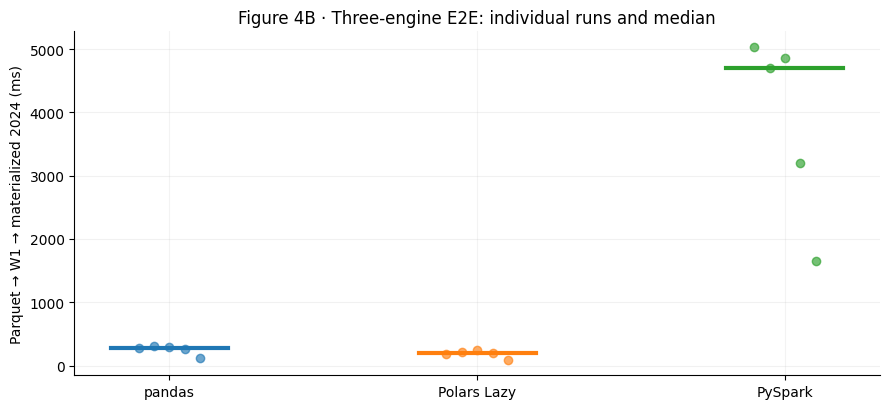

**Interpretation.** The dots show variability, not only point estimates. Spark JVM startup and numeric auditing are outside the clock. This certifies a **2024 pilot comparison**, not full-history Spark equivalence.

In [36]:
# Figure 4B — Observed three-engine repeat-to-repeat variability
if P3_3E_E2E_PASS:
    fig,ax=plt.subplots(figsize=(9,4.2))
    order=['pandas','polars_lazy','pyspark']
    for i,name in enumerate(order):
        series=P3_3E_E2E_RAW.loc[P3_3E_E2E_RAW.engine==name,'elapsed_ms'].to_numpy()
        ax.scatter(i+np.linspace(-.10,.10,len(series)),series,s=36,alpha=.65)
        ax.plot([i-.19,i+.19],[np.median(series)]*2,lw=3)
    ax.set(xticks=range(3),xticklabels=['pandas','Polars Lazy','PySpark'],
        ylabel='Parquet → W1 → materialized 2024 (ms)',
        title='Figure 4B · Three-engine E2E: individual runs and median')
    ax.grid(axis='y',alpha=.17);plt.tight_layout();plt.show()
    if 'figure_04b_three_engine_e2e' not in P3_FIGURES:
        P3_FIGURES.append('figure_04b_three_engine_e2e')
    p3_note('The dots show variability, not only point estimates. Spark JVM startup and '
      'numeric auditing are outside the clock. This certifies a **2024 pilot comparison**, '
      'not full-history Spark equivalence.')
else:
    print('Figure 4B SKIPPED (three-engine E2E not accepted).')

#### Chart interpretation

**Figure 4B — Interpretation.** Individual dots show instability hidden by median bars. This is a controlled 2024 pilot; if Spark did not run, treat the experiment as unavailable, not as a failure of the full-history Polars/Pandas pipeline.

In [37]:
# 3.6.4d — Release Spark memory before 32Y storage stress tests
if P3_3E_OWNS_SPARK and P3_3E_SPARK_READY:
    spark.stop();gc.collect()
    P3_3E_SPARK_READY=False
    print('Spark JVM stopped after the three-engine benchmark. Section 3.9 will restart it.')
else:
    print('Spark session was absent or externally owned; no forced shutdown.')

Spark JVM stopped after the three-engine benchmark. Section 3.9 will restart it.


In [38]:

# ============================================================
# PHASE 3 | SECTION 3.6.4e
# THREE-ENGINE BENCHMARK ROBUSTNESS DIAGNOSTICS
# No new benchmark executions
# ============================================================

# ------------------------------------------------------------
# 0. Validate existing benchmark data
# ------------------------------------------------------------

assert "P3_3E_E2E_RAW" in globals(), (
    "P3_3E_E2E_RAW is missing. Check whether Section 3.6.4c "
    "created the benchmark results in the current kernel."
)

assert P3_3E_E2E_RAW is not None and not P3_3E_E2E_RAW.empty, (
    "P3_3E_E2E_RAW contains no benchmark records."
)

expected_engines = {"pandas", "polars_lazy", "pyspark"}
expected_reps = int(P3_CFG["three_engine_e2e_reps"])

# RAM metrics are intentionally excluded.
required_columns = {
    "engine", "rep", "elapsed_ms", "parity_pass"
}

assert required_columns.issubset(P3_3E_E2E_RAW.columns), (
    f"Missing columns: "
    f"{required_columns - set(P3_3E_E2E_RAW.columns)}"
)

# Validate engine coverage and repetitions directly.
actual_engines = set(P3_3E_E2E_RAW["engine"].dropna())

assert actual_engines == expected_engines, (
    f"Unexpected engine set: {actual_engines}"
)

rep_counts = (
    P3_3E_E2E_RAW
    .groupby("engine")["rep"]
    .nunique()
)

assert rep_counts.eq(expected_reps).all(), (
    f"Unexpected repetition counts: {rep_counts.to_dict()}"
)

assert P3_3E_E2E_RAW["parity_pass"].fillna(False).all(), (
    "At least one benchmark record failed parity."
)

assert P3_3E_E2E_RAW["elapsed_ms"].gt(0).all(), (
    "Invalid benchmark runtime detected."
)

# ------------------------------------------------------------
# 1. Calculate robustness statistics
# ------------------------------------------------------------

P3_3E_ROBUSTNESS_ROWS = []

for engine, group in P3_3E_E2E_RAW.groupby("engine"):

    group = group.sort_values("rep")
    times = group["elapsed_ms"]

    first_ms = float(times.iloc[0])
    last_ms = float(times.iloc[-1])

    median_all = float(times.median())

    tail_n = min(3, len(times))
    median_last = float(times.tail(tail_n).median())

    q25 = float(times.quantile(0.25))
    q75 = float(times.quantile(0.75))

    iqr_ms = q75 - q25

    P3_3E_ROBUSTNESS_ROWS.append({
        "engine": engine,
        "repetitions": len(times),
        "first_ms": first_ms,
        "last_ms": last_ms,
        "first_to_last_change_pct":
            (last_ms / first_ms - 1) * 100,
        "median_all_ms": median_all,
        "median_last3_ms": median_last,
        "median_shift_pct":
            (median_last / median_all - 1) * 100,
        "iqr_ms": iqr_ms,
        "iqr_pct_of_median":
            iqr_ms / median_all * 100,
        "all_parity_pass":
            bool(group["parity_pass"].all())
    })

P3_3E_ROBUSTNESS = (
    pd.DataFrame(P3_3E_ROBUSTNESS_ROWS)
    .sort_values("median_all_ms")
    .reset_index(drop=True)
)


##### Run block 2/2 — continuation of original code cell 51

Run sequentially; the original code statements and their order are unchanged.

In [39]:

# ------------------------------------------------------------
# 2. Ranking stability
# ------------------------------------------------------------

ranking_all = (
    P3_3E_ROBUSTNESS
    .sort_values("median_all_ms")["engine"]
    .tolist()
)

ranking_last3 = (
    P3_3E_ROBUSTNESS
    .sort_values("median_last3_ms")["engine"]
    .tolist()
)

P3_3E_RANKING_STABLE = (
    ranking_all == ranking_last3
)

# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

print("=" * 72)
print("3.6.4e — THREE-ENGINE BENCHMARK ROBUSTNESS")
print("=" * 72)

print("\n[1] RUNTIME ROBUSTNESS")
display(P3_3E_ROBUSTNESS.round(3))

print("\n[2] ENGINE RANKING")
print("Full-run ranking:", ranking_all)
print("Last-three ranking:", ranking_last3)
print("Ranking stable:", P3_3E_RANKING_STABLE)

print("\n[3] INTERPRETATION")

for _, row in P3_3E_ROBUSTNESS.iterrows():

    print(
        f"{row['engine']}: "
        f"median={row['median_all_ms']:.2f} ms, "
        f"IQR={row['iqr_ms']:.2f} ms, "
        f"median shift={row['median_shift_pct']:+.2f}%"
    )

# ------------------------------------------------------------
# 4. Diagnostic acceptance
# ------------------------------------------------------------

P3_3E_ROBUSTNESS_PASS = bool(
    len(P3_3E_ROBUSTNESS) == 3
    and P3_3E_ROBUSTNESS["all_parity_pass"].all()
    and P3_3E_ROBUSTNESS["median_all_ms"].gt(0).all()
    and P3_3E_ROBUSTNESS["iqr_ms"].ge(0).all()
)

assert P3_3E_ROBUSTNESS_PASS, (
    "Three-engine robustness diagnostics failed."
)

P3_EXPERIMENTS["three_engine_robustness"] = {
    "status": "PASS",
    "repetitions_per_engine": expected_reps,
    "full_run_ranking": ranking_all,
    "last_three_ranking": ranking_last3,
    "ranking_stable": bool(P3_3E_RANKING_STABLE),
    "benchmark_rerun": False
}

print("\n[4] ACCEPTANCE")
print("ROBUSTNESS DIAGNOSTICS PASS:", P3_3E_ROBUSTNESS_PASS)
print("Additional benchmark runs: 0")
print("RAM measurement: EXCLUDED")
print("Spark session required: NO")


3.6.4e — THREE-ENGINE BENCHMARK ROBUSTNESS

[1] RUNTIME ROBUSTNESS


,engine,repetitions,first_ms,last_ms,first_to_last_change_pct,median_all_ms,median_last3_ms,median_shift_pct,iqr_ms,iqr_pct_of_median,all_parity_pass
0,polars_lazy,5,179.462,94.390,-47.404,193.419,193.419,0.000,38.254,19.778,True
1,pandas,5,281.712,121.954,-56.710,281.712,266.719,-5.322,25.737,9.136,True
2,pyspark,5,5032.789,1646.992,-67.275,4695.224,3198.457,-31.879,1654.928,35.247,True



[2] ENGINE RANKING
Full-run ranking: ['polars_lazy', 'pandas', 'pyspark']
Last-three ranking: ['polars_lazy', 'pandas', 'pyspark']
Ranking stable: True

[3] INTERPRETATION
polars_lazy: median=193.42 ms, IQR=38.25 ms, median shift=+0.00%
pandas: median=281.71 ms, IQR=25.74 ms, median shift=-5.32%
pyspark: median=4695.22 ms, IQR=1654.93 ms, median shift=-31.88%

[4] ACCEPTANCE
ROBUSTNESS DIAGNOSTICS PASS: True
Additional benchmark runs: 0
RAM measurement: EXCLUDED
Spark session required: NO


#### Interpretation — Three-engine pilot

Compare both **median runtime and run-to-run variation**, conditioned on matching 2024 results. Do not extrapolate a local Spark pilot into a verified distributed-cluster advantage.

<a id="p3-7"></a>
## 3.7 — Optimizer and adversarial correctness

Test projection/predicate pushdown, input ordering, future contamination, missing quarters and invalid denominators. Correctness gates take precedence over small benchmark differences.

### 3.7.0 — Projection and predicate pushdown

Contrast a broad source scan with the 11-column W1 projection, and direct date filters with derived-year expressions. Profile plans where available; never infer actual I/O pruning from metadata alone.

In [40]:
# 3.7.0a — Projection pushdown: full 141 columns vs W1's 11 columns
projection_cases={
 'full_141':src.filter(pl.col('REPDTE').is_between(_date(2024,1,1),_date(2024,12,31))),
 'W1_11':src.filter(pl.col('REPDTE').is_between(_date(2024,1,1),_date(2024,12,31))).select(P3_W1_INPUTS)}
rows=[]
for name,q in projection_cases.items():
    for rep in range(1,4):
        t=time.perf_counter();d=q.collect(engine='streaming')
        rows.append({'projection':name,'run':rep,'rows':d.height,'cols':d.width,
                     'ms':(time.perf_counter()-t)*1000})
        assert d.height==18399
        del d;gc.collect()
P3_PROJECTION_AB=pd.DataFrame(rows)
summary=P3_PROJECTION_AB.groupby('projection',as_index=False).agg(
 median_ms=('ms','median'),selected_cols=('cols','first'),correct=('rows',lambda s:bool((s==18399).all())))
p3_mark('3.7 projection pushdown controlled scans',len(rows)==6 and summary.correct.all())
display(summary.round(2))

PASS  3.7 projection pushdown controlled scans


,projection,median_ms,selected_cols,correct
0,W1_11,3.39,11,True
1,full_141,16.01,141,True


In [41]:
# 3.7.0b — Predicate pushdown: simple range vs derived year filter
predicates={'date_range':pl.col('REPDTE').is_between(_date(2024,1,1),_date(2024,12,31)),
 'derived_year':pl.col('REPDTE').dt.year()==2024}
measure=[]
for name,predicate in predicates.items():
    q=src.filter(predicate).select(P3_W1_INPUTS)
    for rep in range(1,4):
        t=time.perf_counter();d=q.collect(engine='streaming')
        assert d.height==18399
        measure.append({'predicate':name,'run':rep,'ms':(time.perf_counter()-t)*1000})
        del d
P3_PREDICATE_AB=pd.DataFrame(measure)
P3_EXPERIMENTS['projection_predicate']={'status':'PASS','measurements':12}
display(P3_PREDICATE_AB.groupby('predicate',as_index=False).ms.median().round(2))
p3_note('A date-range predicate may expose row-group min/max filtering; this test times query execution but does not directly count physical reads.')

,predicate,ms
0,date_range,2.46
1,derived_year,98.90


**Interpretation.** A date-range predicate may expose row-group min/max filtering; this test times query execution but does not directly count physical reads.

In [42]:
# 3.7.1 — Optimized plan comparison and numerical A/B at 2024
plan_rows=[];queries={'four_join':p3_w1_join(2024,2024),'calendar_window':p3_w1_window(2024,2024)}
for name,q in queries.items():
    p=q.explain(optimized=True)
    plan_rows.append({'implementation':name,'logical_plan_lines':len(p.splitlines()),
       'lines_containing_JOIN':sum('JOIN' in t.upper() for t in p.splitlines()),
       'scan_lines':sum('SCAN' in t.upper() for t in p.splitlines())})
P3_PLAN_AUDIT=pd.DataFrame(plan_rows)
a=p3_collect(queries['four_join']);b=p3_collect(queries['calendar_window'])
keys,report=p3_compare_frames(a.to_pandas(),b.to_pandas(),'join_vs_window_2024')
p3_mark('3.7 optimizer A/B numerical parity',keys==0 and
    report[['null_errors','numeric_errors','nonfinite_errors']].to_numpy().sum()==0)
display(P3_PLAN_AUDIT)
print('Plan keyword counts are diagnostics, not physical operator counts.')
del a,b,queries;gc.collect()

PASS  3.7 optimizer A/B numerical parity


,implementation,logical_plan_lines,lines_containing_JOIN,scan_lines
0,four_join,77,8,2
1,calendar_window,31,0,1


Plan keyword counts are diagnostics, not physical operator counts.


0

In [43]:
# 3.7.2 — LOWMEM-inspired metamorphic tests: future perturbation, row order, time-window invariance
cutoff=_date(2021,12,31)
banks=(src.filter(pl.col('REPDTE').is_between(_date(2019,1,1),_date(2022,12,31)))
       .group_by('CERT').agg(pl.len().alias('n')).filter(pl.col('n')>=12)
       .sort('CERT').limit(12).select('CERT').collect()['CERT'].to_list())
if len(banks)<3: raise AssertionError('Not enough continuous sample banks for metamorphic test')
sample=(src.filter(pl.col('CERT').is_in(banks) &
           pl.col('REPDTE').is_between(_date(2019,1,1),_date(2022,12,31)))
          .select(P3_W1_INPUTS).collect(engine='streaming'))
future=pl.col('REPDTE')>cutoff
altered=sample.with_columns([
    pl.when(future & pl.col('ASSET').is_finite()).then(pl.col('ASSET')*1.21)
      .otherwise(pl.col('ASSET')).alias('ASSET'),
    pl.when(future & pl.col('ROA').is_finite()).then(pl.col('ROA')+17)
      .otherwise(pl.col('ROA')).alias('ROA')])
base=p3_collect(p3_w1_window(2020,2022,sample))
perturb=p3_collect(p3_w1_window(2020,2022,altered))
permuted=p3_collect(p3_w1_window(2020,2022,sample.sample(fraction=1,shuffle=True,seed=2026)))
truncated=p3_collect(p3_w1_window(2020,2021,sample))
prefix=lambda x:x.filter(pl.col('REPDTE')<=cutoff).sort(['CERT','REPDTE'])
assert_frame_equal(prefix(base),prefix(perturb),check_exact=False,rtol=1e-10,atol=1e-11)
assert_frame_equal(base,permuted,check_exact=False,rtol=1e-10,atol=1e-11)
assert_frame_equal(prefix(base),truncated,check_exact=False,rtol=1e-10,atol=1e-11)
p3_mark('3.7 metamorphic temporal invariants',True)
P3_EXPERIMENTS['metamorphic']={'banks':len(banks),'checks':3,'status':'PASS'}
print('Metamorphic tests: 3/3 PASS; sample rows:',sample.height)
del sample,altered,base,perturb,permuted,truncated;gc.collect()

PASS  3.7 metamorphic temporal invariants
Metamorphic tests: 3/3 PASS; sample rows: 188


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\64475148.py:21: DeprecationWarning: the argument `rtol` for `assert_frame_equal` is deprecated. It was renamed to `rel_tol` in version 1.32.3.
  assert_frame_equal(prefix(base),prefix(perturb),check_exact=False,rtol=1e-10,atol=1e-11)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\64475148.py:21: DeprecationWarning: the argument `atol` for `assert_frame_equal` is deprecated. It was renamed to `abs_tol` in version 1.32.3.
  assert_frame_equal(prefix(base),prefix(perturb),check_exact=False,rtol=1e-10,atol=1e-11)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\64475148.py:22: DeprecationWarning: the argument `rtol` for `assert_frame_equal` is deprecated. It was renamed to `rel_tol` in version 1.32.3.
  assert_frame_equal(base,permuted,check_exact=False,rtol=1e-10,atol=1e-11)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\64475148.py:22: DeprecationWarning: the argument `atol` for `assert_frame_equal` is deprecated. It was renamed to `ab

0

In [44]:
# 3.7.3 — LOWMEM-inspired adversarial arithmetic and missing-quarter tests
rows=[]
for dt,asset,roa in [('2020-03-31',100,1),('2020-06-30',0,2),('2020-09-30',120,None),
 ('2020-12-31',-20,-2),('2021-03-31',125,3),('2021-06-30',135,4),
 ('2021-09-30',140,5),('2021-12-31',160,6)]:
 rows.append({'CERT':90001,'REPDTE':_date.fromisoformat(dt),'ASSET':float(asset),'EQ':-5.,
  'DEP':20.,'CHBAL':5.,'SC':2.,'ROA':roa,'LNLSGR':10.,'NCLNLS':0.,'COREDEP':8.})
for dt in ['2020-03-31','2020-09-30','2020-12-31','2021-03-31','2021-06-30']:
 rows.append({'CERT':90002,'REPDTE':_date.fromisoformat(dt),'ASSET':100.,'EQ':5.,
  'DEP':20.,'CHBAL':5.,'SC':2.,'ROA':1.,'LNLSGR':10.,'NCLNLS':0.,'COREDEP':8.})
toy=pl.DataFrame(rows,schema_overrides={'ROA':pl.Float64})
result=p3_collect(p3_w1_window(2020,2021,toy)).to_pandas()
result['REPDTE']=pd.to_datetime(result['REPDTE'])
def observed(cert,dt,feature):
    return result.loc[(result.CERT==cert)&(result.REPDTE==pd.Timestamp(dt)),feature].iloc[0]
checks={
 'zero ASSET -> null equity ratio':pd.isna(observed(90001,'2020-06-30','equity_to_assets')),
 'negative ASSET -> null denominator ratio':pd.isna(observed(90001,'2020-12-31','equity_to_assets')),
 'exact 4-quarter growth':np.isclose(observed(90001,'2021-03-31','asset_growth_4q'),.25),
 'zero historical ASSET -> null growth':pd.isna(observed(90001,'2021-06-30','asset_growth_4q')),
 'rolling mean complete':np.isclose(observed(90001,'2021-12-31','roa_rolling_mean_4q'),4.5),
 'sample std ddof=1':np.isclose(observed(90001,'2021-12-31','roa_rolling_std_4q'),np.std([3,4,5,6],ddof=1)),
 'gap invalidates rolling window':pd.isna(observed(90002,'2021-03-31','roa_rolling_mean_4q'))}
p3_mark('3.7 adversarial financial tests',all(checks.values()))
print('Adversarial tests:',sum(checks.values()),'/',len(checks));display(pd.DataFrame(list(checks.items()),columns=['test','pass']))
P3_EXPERIMENTS['adversarial']={'checks':len(checks),'status':'PASS'}
del toy,result;gc.collect()

PASS  3.7 adversarial financial tests
Adversarial tests: 7 / 7


,test,pass
0,zero ASSET -> null equity ratio,True
1,negative ASSET -> null denominator ratio,True
2,exact 4-quarter growth,True
3,zero historical ASSET -> null growth,True
4,rolling mean complete,True
5,sample std ddof=1,True
6,gap invalidates rolling window,True


0

In [45]:
# 3.7.4 — Optional operator profile: diagnostic, not a fresh multi-run benchmark
if P3_CFG['run_optional_profile']:
    try:
        _result,_profile=p3_w1_window(2024,2024).profile(optimizations=P3_NO_PUSHDOWN)
        P3_OPERATOR_PROFILE=_profile.to_pandas()
        P3_EXPERIMENTS['operator_profile']={'status':'PASS','rows':len(P3_OPERATOR_PROFILE)}
        display(P3_OPERATOR_PROFILE.head(12))
        del _result,_profile;gc.collect()
    except Exception as exc:
        P3_EXPERIMENTS['operator_profile']={'status':'SKIPPED_COMPATIBILITY','reason':str(exc)[:180]}
        print('Profiling unsupported by this Polars version:',type(exc).__name__)
else:
    P3_EXPERIMENTS['operator_profile']={'status':'SKIPPED_BY_POLICY'}
print('Operator profile:',P3_EXPERIMENTS['operator_profile']['status'])

Profiling unsupported by this Polars version: AttributeRemovedError
Operator profile: SKIPPED_COMPATIBILITY


#### Interpretation — Temporal leakage tests

Future-value perturbations should not change past-quarter features; row reordering should not change bank-quarter results. Adversarial missing-quarter checks enforce exact calendar lags rather than rolling over available rows.

### 3.7.5 — Polars streaming versus in-memory

Compare equivalent 2024 feature expressions, not incomparable workload sizes. A successful speed result must also pass the numerical match.

In [46]:
# 3.7.5 — Polars streaming vs in-memory, numerically verified
if P3_CFG['run_streaming_ab']:
    q=p3_w1_window(2024,2024)
    streamed=p3_collect(q)
    eager=q.collect(engine='in-memory',optimizations=P3_NO_PUSHDOWN)
    assert_frame_equal(streamed,eager,check_exact=False,rtol=1e-10,atol=1e-11)
    records=[]
    for eng in ('streaming','in-memory'):
        for rep in range(1,4):
            t=time.perf_counter()
            df=q.collect(engine=eng,optimizations=P3_NO_PUSHDOWN)
            records.append({'engine':eng,'repetition':rep,'ms':(time.perf_counter()-t)*1000,'rows':df.height})
            del df
    P3_STREAMING_AB=pd.DataFrame(records)
    assert P3_STREAMING_AB.rows.eq(18399).all()
    P3_EXPERIMENTS['streaming_vs_in_memory']={'status':'PASS','runs':len(records)}
    p3_mark('3.7 streaming/in-memory 2024 parity',True)
    summary=P3_STREAMING_AB.groupby('engine',as_index=False).ms.median()
    display(summary.round(3));del streamed,eager,q;gc.collect()
else:
    P3_EXPERIMENTS['streaming_vs_in_memory']={'status':'SKIPPED_BY_POLICY'}

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\3582644705.py:6: DeprecationWarning: the argument `rtol` for `assert_frame_equal` is deprecated. It was renamed to `rel_tol` in version 1.32.3.
  assert_frame_equal(streamed,eager,check_exact=False,rtol=1e-10,atol=1e-11)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\3582644705.py:6: DeprecationWarning: the argument `atol` for `assert_frame_equal` is deprecated. It was renamed to `abs_tol` in version 1.32.3.
  assert_frame_equal(streamed,eager,check_exact=False,rtol=1e-10,atol=1e-11)


PASS  3.7 streaming/in-memory 2024 parity


,engine,ms
0,in-memory,137.385
1,streaming,115.076


<a id="p3-8"></a>
## 3.8 — Storage and physical-layout experiments

Measure codec size, row-group statistics, scan time and logical fidelity. A smaller file is not automatically the fastest design.

### Archived evidence B — Parquet size/scan Pareto plane

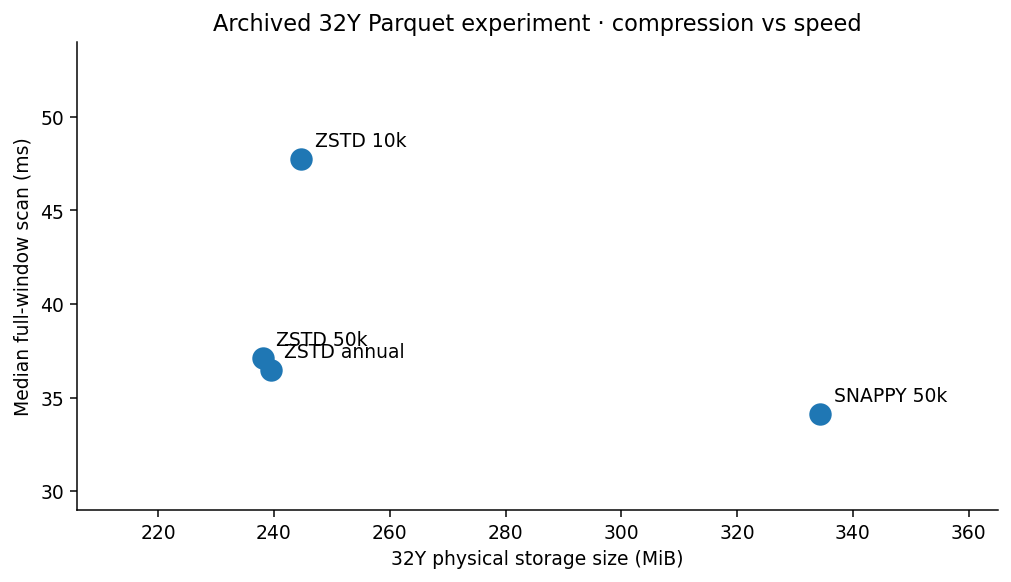

**Reading:** **ZSTD 50k saved 28.80%** compared with SNAPPY, with a **modest scan penalty**. The 10k-row-group layout is dominated on this dataset. Current-run cells also test physical row-group eligibility and date clustering.

*Figure uses archived measurements from the executed input notebook; new current-run charts appear below and must be run locally.*

In [47]:

# 3.8.1 — 32-year full-column layout construction

P3_STORE_START, P3_STORE_END = 1993, 2024

P3_STORAGE_LAYOUTS = {
    'snappy_50k': ('snappy', 50000, False),
    'zstd_50k': ('zstd', 50000, False),
    'zstd_10k': ('zstd', 10000, False),
    'zstd_annual': ('zstd', 50000, True)
}

P3_STORAGE_DIR = P3_RUN_DIR / 'storage_ablation_32y'

P3_STORE_ROWS = int(
    P3_YEARS
    .filter(pl.col('year').is_between(1993, 2024))['rows']
    .sum()
)

P3_STORAGE_FILES = {}
P3_STORAGE_META = []

if P3_CFG['run_storage']:

    # Check available disk space before constructing storage layouts.
    if shutil.disk_usage(P3_RUN_DIR).free < 1600 * 2**20:
        raise OSError('Need 1,600 MiB free disk')

    P3_STORAGE_DIR.mkdir(parents=True, exist_ok=True)

    for name, (codec, rg, partitioned) in P3_STORAGE_LAYOUTS.items():

        dest = P3_STORAGE_DIR / name
        dest.mkdir(exist_ok=True)

        files = []

        if not partitioned:

            f = dest / 'data.parquet'

            if not f.exists():
                (
                    src
                    .filter(
                        pl.col('REPDTE').is_between(
                            _date(1993, 1, 1),
                            _date(2024, 12, 31)
                        )
                    )
                    .sink_parquet(
                        str(f),
                        compression=codec,
                        row_group_size=rg
                    )
                )

            files = [f]
            scan = str(f)

        else:

            for year in range(1993, 2025):

                folder = dest / f'year={year}'
                folder.mkdir(exist_ok=True)

                f = folder / 'data.parquet'

                if not f.exists():
                    (
                        src
                        .filter(pl.col('REPDTE').dt.year() == year)
                        .sink_parquet(
                            str(f),
                            compression=codec,
                            row_group_size=rg
                        )
                    )

                files.append(f)

            scan = str(dest / 'year=*' / 'data.parquet')

        # Validate physical row counts and logical schemas.
        meta = [pq.read_metadata(str(f)) for f in files]
        rows = sum(m.num_rows for m in meta)

        schema = (
            pl.scan_parquet(scan, hive_partitioning=False)
            .collect_schema()
        )

        correct = (
            rows == P3_STORE_ROWS
            and list(schema) == P3_SOURCE_COLUMNS
            and all(
                schema[c] == P3_SCHEMA[c]
                for c in P3_SOURCE_COLUMNS
            )
        )

        if not correct:
            raise AssertionError(
                f'{name}: row or logical schema mismatch'
            )

        P3_STORAGE_FILES[name] = scan

        P3_STORAGE_META.append({
            'layout': name,
            'files': len(files),
            'row_groups': sum(
                m.num_row_groups for m in meta
            ),
            'rows': rows,
            'size_mib': sum(
                f.stat().st_size for f in files
            ) / 2**20
        })

        print(
            name,
            '|', rows, 'rows |',
            round(P3_STORAGE_META[-1]['size_mib'], 2),
            'MiB'
        )

    P3_STORAGE_TABLE = pd.DataFrame(P3_STORAGE_META)

    p3_mark(
        '3.8 32-year physical row counts and logical schemas',
        True
    )

else:

    P3_EXPERIMENTS['storage'] = {
        'status': 'SKIPPED_BY_POLICY'
    }

    print('Storage experiment deliberately skipped.')


snappy_50k | 1056900 rows | 334.39 MiB
zstd_50k | 1056900 rows | 238.1 MiB
zstd_10k | 1056900 rows | 244.75 MiB
zstd_annual | 1056900 rows | 239.56 MiB
PASS  3.8 32-year physical row counts and logical schemas


In [48]:
# 3.8.2 — Data fidelity: one year at a time, including 2024 full 141-column audit
if P3_CFG['run_storage']:
    P3_STORAGE_FIDELITY=[]
    for name,scan in P3_STORAGE_FILES.items():
        passed=0
        for year in range(1993,2025):
            base=(src.filter(pl.col('REPDTE').dt.year()==year)
                  .select(P3_W1_INPUTS).sort(['CERT','REPDTE']).collect(engine='streaming'))
            alt=(pl.scan_parquet(scan,hive_partitioning=False)
                 .filter(pl.col('REPDTE').dt.year()==year).select(P3_W1_INPUTS)
                 .sort(['CERT','REPDTE']).collect(engine='streaming'))
            assert_frame_equal(base,alt,check_exact=True)
            passed+=1;del base,alt
        # Stronger 2024 full-field check; remaining years: exact W1 source fields.
        base=(src.filter(pl.col('REPDTE').dt.year()==2024)
              .select(P3_SOURCE_COLUMNS).sort(['CERT','REPDTE']).collect(engine='streaming'))
        alt=(pl.scan_parquet(scan,hive_partitioning=False)
             .filter(pl.col('REPDTE').dt.year()==2024).select(P3_SOURCE_COLUMNS)
             .sort(['CERT','REPDTE']).collect(engine='streaming'))
        assert_frame_equal(base,alt,check_exact=True)
        del base,alt;gc.collect()
        P3_STORAGE_FIDELITY.append({'layout':name,'years_w1_exact':passed,
                                    '2024_full_schema_values_exact':True,'pass':passed==32})
    P3_STORAGE_FIDELITY_REPORT=pd.DataFrame(P3_STORAGE_FIDELITY)
    p3_mark('3.8 exact 32-year W1 + full-field 2024 fidelity',P3_STORAGE_FIDELITY_REPORT['pass'].all())
    print('Exact W1 parity: all 32 years × 4 layouts; full 141-field parity: 2024 × 4 layouts.')

PASS  3.8 exact 32-year W1 + full-field 2024 fidelity
Exact W1 parity: all 32 years × 4 layouts; full 141-field parity: 2024 × 4 layouts.


In [49]:
# 3.8.3 — Repeated scan benchmark, full window and selective 2024 query
if P3_CFG['run_storage']:
    cases={'full_1993_2024':(1993,2024,P3_STORE_ROWS),
           'year_2024':(2024,2024,int(P3_YEARS.filter(pl.col('year')==2024)['rows'].sum()))}
    P3_STORAGE_TIMINGS=[]
    for workload,(start,end,expected) in cases.items():
        for name,scan in P3_STORAGE_FILES.items():
            def run(path=scan,a=start,b=end):
                return (pl.scan_parquet(path,hive_partitioning=False)
                        .filter(pl.col('REPDTE').is_between(_date(a,1,1),_date(b,12,31)))
                        .select(P3_W1_INPUTS).collect(engine='streaming').height)
            assert run()==expected
            for rep in range(1,4):
                t0=time.perf_counter();rows=run();elapsed=(time.perf_counter()-t0)*1000
                P3_STORAGE_TIMINGS.append({'workload':workload,'layout':name,'rep':rep,'ms':elapsed,
                                           'row_pass':rows==expected})
    P3_STORAGE_RAW=pd.DataFrame(P3_STORAGE_TIMINGS)
    P3_STORAGE_SCAN_SUM=(P3_STORAGE_RAW.groupby(['workload','layout'],as_index=False)
                         .agg(median_ms=('ms','median'),reps=('rep','count'),correct=('row_pass','all')))
    p3_mark('3.8 repeated 24 scan executions',len(P3_STORAGE_RAW)==24 and
            P3_STORAGE_RAW['row_pass'].all())
    P3_STORAGE_TABLE['size_reduction_pct']=(1-P3_STORAGE_TABLE['size_mib']/
         P3_STORAGE_TABLE.loc[P3_STORAGE_TABLE.layout=='snappy_50k','size_mib'].iloc[0])*100
    display(P3_STORAGE_TABLE.round(2))
    display(P3_STORAGE_SCAN_SUM.round(2))

PASS  3.8 repeated 24 scan executions


,layout,files,row_groups,rows,size_mib,size_reduction_pct
0,snappy_50k,1,22,1056900,334.39,0.00
1,zstd_50k,1,22,1056900,238.10,28.79
2,zstd_10k,1,106,1056900,244.75,26.81
3,zstd_annual,32,34,1056900,239.56,28.36


,workload,layout,median_ms,reps,correct
0,full_1993_2024,snappy_50k,61.29,3,True
1,full_1993_2024,zstd_10k,89.48,3,True
2,full_1993_2024,zstd_50k,69.89,3,True
3,full_1993_2024,zstd_annual,77.06,3,True
4,year_2024,snappy_50k,7.58,3,True
5,year_2024,zstd_10k,15.62,3,True
6,year_2024,zstd_50k,10.35,3,True
7,year_2024,zstd_annual,27.87,3,True


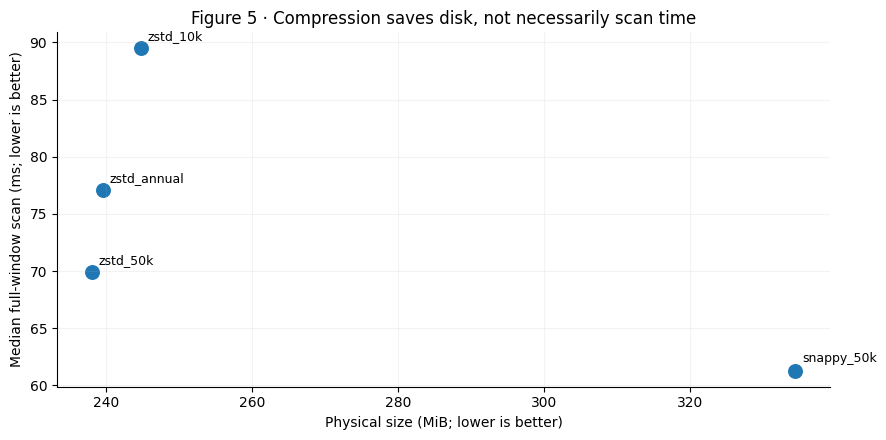

**Interpretation.** zstd_50k has the smallest file (238.1 MiB); snappy_50k is fastest on full-window scan (61.3 ms). Trade-offs apply to the tested 1993–2024 subset, not automatically to a future distributed cluster.

In [50]:
# Figure 5 — Codec and row-group Pareto plane (better is down and left)
if P3_CFG['run_storage']:
    merged=P3_STORAGE_TABLE.merge(P3_STORAGE_SCAN_SUM.query('workload=="full_1993_2024"'),on='layout')
    fig,ax=plt.subplots(figsize=(9,4.5))
    ax.scatter(merged['size_mib'],merged['median_ms'],s=95)
    for r in merged.itertuples():
        ax.annotate(r.layout,(r.size_mib,r.median_ms),xytext=(5,6),textcoords='offset points',fontsize=9)
    ax.set(xlabel='Physical size (MiB; lower is better)',ylabel='Median full-window scan (ms; lower is better)',
           title='Figure 5 · Compression saves disk, not necessarily scan time')
    plt.tight_layout();plt.show();P3_FIGURES.append('figure_05_codec_pareto')
    lean=merged.loc[merged.size_mib.idxmin()];fast=merged.loc[merged.median_ms.idxmin()]
    p3_note(f'{lean.layout} has the smallest file ({lean.size_mib:.1f} MiB); '
            f'{fast.layout} is fastest on full-window scan ({fast.median_ms:.1f} ms). '
            'Trade-offs apply to the tested 1993–2024 subset, not automatically to a future distributed cluster.')

#### Chart interpretation

**Figure 5 — Interpretation.** The Pareto diagram jointly assesses storage cost and query latency. Prefer a layout only if row/value fidelity is maintained; the smallest file may be slower to scan.

In [51]:
# 3.8.4 — Row-group pruning potential, NOT physical operator counts
if P3_CFG['run_storage']:
    pruning=[]
    for name,scan in P3_STORAGE_FILES.items():
        paths=sorted((P3_STORAGE_DIR/name).rglob('*.parquet'))
        total=possible=missing_stats=0
        for f in paths:
            meta=pq.read_metadata(str(f)); colnames=meta.schema.names
            idx=colnames.index('REPDTE')
            for i in range(meta.num_row_groups):
                total+=1;stats=meta.row_group(i).column(idx).statistics
                if stats is None or stats.min is None or stats.max is None:
                    possible+=1;missing_stats+=1;continue
                low=pd.Timestamp(stats.min); high=pd.Timestamp(stats.max)
                if low<=pd.Timestamp('2024-12-31') and high>=pd.Timestamp('2024-01-01'):
                    possible+=1
        pruning.append({'layout':name,'row_groups_total':total,'candidate_2024':possible,
                        'possible_skip_pct':100*(1-possible/total),'missing_stats':missing_stats})
    P3_PRUNING_POTENTIAL=pd.DataFrame(pruning)
    display(P3_PRUNING_POTENTIAL.round(1))
    p3_note('Potential skipping is inferred from Parquet min/max statistics only. Spark/Polars actual row-group pruning is not claimed without physical-plan or I/O counters. Annual Hive pruning requires an explicit year partition predicate.')

,layout,row_groups_total,candidate_2024,possible_skip_pct,missing_stats
0,snappy_50k,22,2,90.9,0
1,zstd_50k,22,2,90.9,0
2,zstd_10k,106,3,97.2,0
3,zstd_annual,34,1,97.1,0


**Interpretation.** Potential skipping is inferred from Parquet min/max statistics only. Spark/Polars actual row-group pruning is not claimed without physical-plan or I/O counters. Annual Hive pruning requires an explicit year partition predicate.

#### Interpretation — Storage trade-off

Archived evidence favored ZSTD 50k on file size, with a modest scan cost. New figures must be read using **current-run size and latency together**; a layout is accepted only when row counts and values match.

### 3.8.5 — Date-clustered single-file layout

Test `REPDTE` clustering under bounded memory. Row-group min/max statistics show *potential* pruning, not measured physical read elimination.

In [52]:
# 3.8.5a — Date-clustered single Parquet: bounded annual sorting + exact W1 audit
if P3_CFG['run_storage'] and P3_CFG['run_date_clustered']:
    P3_DATE_CLUSTER_PATH=P3_STORAGE_DIR/'zstd_date_clustered'/'data.parquet'
    P3_DATE_CLUSTER_PATH.parent.mkdir(exist_ok=True)
    if not P3_DATE_CLUSTER_PATH.exists():
        writer=None
        try:
            for yr in range(P3_STORE_START,P3_STORE_END+1):
                annual=(src.filter(pl.col('REPDTE').dt.year()==yr)
                        .select(P3_SOURCE_COLUMNS).sort(['REPDTE','CERT'])
                        .collect(engine='streaming').to_arrow())
                if writer is None:
                    writer=pq.ParquetWriter(str(P3_DATE_CLUSTER_PATH),annual.schema,
                                            compression='zstd')
                writer.write_table(annual,row_group_size=50000)
                del annual;gc.collect()
        finally:
            if writer is not None:writer.close()
    meta=pq.read_metadata(str(P3_DATE_CLUSTER_PATH))
    assert meta.num_rows==P3_STORE_ROWS
    for yr in range(1993,2025):
        a=(src.filter(pl.col('REPDTE').dt.year()==yr).select(P3_W1_INPUTS)
             .sort(['CERT','REPDTE']).collect(engine='streaming'))
        b=(pl.scan_parquet(str(P3_DATE_CLUSTER_PATH)).filter(pl.col('REPDTE').dt.year()==yr)
             .select(P3_W1_INPUTS).sort(['CERT','REPDTE']).collect(engine='streaming'))
        assert_frame_equal(a,b,check_exact=True)
    p3_mark('3.8 date-clustered 32Y exact parity',True)
    P3_EXPERIMENTS['date_clustered']={'status':'PASS','rows':meta.num_rows,
        'size_mib':round(P3_DATE_CLUSTER_PATH.stat().st_size/2**20,2)}
    print('Date-clustered:',meta.num_row_groups,'row groups |',
          round(P3_DATE_CLUSTER_PATH.stat().st_size/2**20,1),'MiB | 32/32 W1 years PASS')
else:
    P3_EXPERIMENTS['date_clustered']={'status':'SKIPPED_BY_POLICY_OR_PARENT'}

PASS  3.8 date-clustered 32Y exact parity
Date-clustered: 34 row groups | 258.2 MiB | 32/32 W1 years PASS


In [53]:
# 3.8.5b — Same selective 2024 scan; compare cluster vs existing ZSTD 50k layout
if P3_EXPERIMENTS['date_clustered']['status']=='PASS':
    sources={'zstd_50k':P3_STORAGE_FILES['zstd_50k'],
             'zstd_date_clustered':str(P3_DATE_CLUSTER_PATH)}
    records=[]
    for name,path in sources.items():
        for rep in range(1,4):
            t=time.perf_counter()
            out=(pl.scan_parquet(path,hive_partitioning=False)
                 .filter(pl.col('REPDTE').is_between(_date(2024,1,1),_date(2024,12,31)))
                 .select(P3_W1_INPUTS).collect(engine='streaming'))
            assert out.height==18399
            records.append({'layout':name,'ms':(time.perf_counter()-t)*1000,'rows':out.height})
    P3_DATE_CLUSTER_BENCH=pd.DataFrame(records)
    date_summary=P3_DATE_CLUSTER_BENCH.groupby('layout',as_index=False).ms.median()
    display(date_summary.round(2))
    stats=[]
    for name,path in sources.items():
        m=pq.read_metadata(path); idx=m.schema.names.index('REPDTE'); eligible=0
        for i in range(m.num_row_groups):
            st=m.row_group(i).column(idx).statistics
            if st is None or st.min is None or st.max is None:
                eligible+=1
            elif pd.Timestamp(st.min)<=pd.Timestamp('2024-12-31') and pd.Timestamp(st.max)>=pd.Timestamp('2024-01-01'):
                eligible+=1
        stats.append({'layout':name,'total_row_groups':m.num_row_groups,'candidate_row_groups_2024':eligible})
    display(pd.DataFrame(stats))
    p3_note('Date clustering changes which row groups could be skipped; benchmarks measure selective scan latency, but min/max eligibility is not a direct count of physical row-group reads.')

,layout,ms
0,zstd_50k,14.02
1,zstd_date_clustered,10.06


,layout,total_row_groups,candidate_row_groups_2024
0,zstd_50k,22,2
1,zstd_date_clustered,34,1


**Interpretation.** Date clustering changes which row groups could be skipped; benchmarks measure selective scan latency, but min/max eligibility is not a direct count of physical row-group reads.

In [57]:

# 3.8.5c — Full-source Parquet codec benchmark

P3_STORAGE_FULL_SCOPES = {
    'source': '1984Q1–2026Q2',
    'W1_output_years': 42,
    'raw_calendar_years': 43,
    'first_output': '1985Q1'
}

P3_STORAGE_FULL_ROWS = int(P3_META.num_rows)

P3_STORAGE_FULL_DIR = (
    P3_RUN_DIR / 'storage_full_history_1984_2026Q2'
)

P3_STORAGE_FULL_LAYOUTS = {
    'snappy_50k': 'snappy',
    'zstd_50k': 'zstd'
}

P3_STORAGE_FULL_FILES = {}
P3_STORAGE_FULL_META = []
P3_STORAGE_FULL_TIMINGS = []

if (
    P3_CFG['run_storage']
    and P3_CFG.get('run_storage_full_history', False)
):

    P3_STORAGE_FULL_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    # Check available storage
    space_needed = (
        2 * P3_SILVER_PATH.stat().st_size
        + 256 * 2**20
    )

    if shutil.disk_usage(P3_RUN_DIR).free < space_needed:
        raise OSError(
            'Insufficient disk for full-history comparison. '
            'Set run_storage_full_history=False to skip.'
        )

    # Full raw financial source, including 1984 lag base
    full_source = src.filter(
        pl.col('REPDTE').is_between(
            P3_CFG['financial_first'],
            P3_CFG['financial_last']
        )
    )

    # Build two Parquet layouts
    for layout, codec in P3_STORAGE_FULL_LAYOUTS.items():

        file = P3_STORAGE_FULL_DIR / f'{layout}.parquet'

        if not file.is_file():
            full_source.sink_parquet(
                str(file),
                compression=codec,
                row_group_size=50000
            )

        meta = pq.read_metadata(str(file))
        lf = pl.scan_parquet(str(file))
        schema = lf.collect_schema()

        assert meta.num_rows == P3_STORAGE_FULL_ROWS
        assert list(schema) == P3_SOURCE_COLUMNS

        assert all(
            schema[c] == P3_SCHEMA[c]
            for c in P3_SOURCE_COLUMNS
        )

        # Exact annual fidelity for all W1 raw inputs
        for year in range(1984, 2027):

            baseline = (
                src.filter(pl.col('REPDTE').dt.year() == year)
                .select(P3_W1_INPUTS)
                .sort(['CERT', 'REPDTE'])
                .collect(engine='streaming')
            )

            observed = (
                lf.filter(pl.col('REPDTE').dt.year() == year)
                .select(P3_W1_INPUTS)
                .sort(['CERT', 'REPDTE'])
                .collect(engine='streaming')
            )

            assert_frame_equal(
                baseline,
                observed,
                check_exact=True
            )

            del baseline, observed

        # Full-field audit at historical boundaries
        for year in (1984, 2026):

            baseline = (
                src.filter(pl.col('REPDTE').dt.year() == year)
                .select(P3_SOURCE_COLUMNS)
                .sort(['CERT', 'REPDTE'])
                .collect(engine='streaming')
            )

            observed = (
                lf.filter(pl.col('REPDTE').dt.year() == year)
                .select(P3_SOURCE_COLUMNS)
                .sort(['CERT', 'REPDTE'])
                .collect(engine='streaming')
            )

            assert_frame_equal(
                baseline,
                observed,
                check_exact=True
            )

            del baseline, observed

        # Storage metadata
        P3_STORAGE_FULL_FILES[layout] = str(file)

        P3_STORAGE_FULL_META.append({
            'scope': 'full_1984_2026Q2',
            'layout': layout,
            'rows': int(meta.num_rows),
            'raw_calendar_years': 43,
            'W1_output_years': 42,
            'files': 1,
            'row_groups': int(meta.num_row_groups),
            'size_mib': file.stat().st_size / 2**20,
            'fidelity_pass': True
        })

        print(
            f'{layout}: {meta.num_rows:,} raw rows; '
            '43/43 annual input parity PASS'
        )

        gc.collect()

    # Benchmark query contracts
    scan_cases = {
        'full_1984_2026Q2': (
            P3_CFG['financial_first'],
            P3_CFG['financial_last'],
            P3_STORAGE_FULL_ROWS
        ),
        'year_2024': (
            _date(2024, 1, 1),
            _date(2024, 12, 31),
            int(
                P3_YEARS.filter(
                    pl.col('year') == 2024
                )['rows'].sum()
            )
        )
    }

    for workload, (start, end, expected) in scan_cases.items():

        for layout, path in P3_STORAGE_FULL_FILES.items():

            def run(path=path, start=start, end=end):
                return (
                    pl.scan_parquet(path)
                    .filter(
                        pl.col('REPDTE').is_between(start, end)
                    )
                    .select(P3_W1_INPUTS)
                    .collect(engine='streaming')
                    .height
                )

            assert run() == expected

            for rep in range(
                1, P3_CFG['benchmark_reps'] + 1
            ):

                t0 = time.perf_counter()
                rows = run()
                duration = (
                    time.perf_counter() - t0
                ) * 1000

                P3_STORAGE_FULL_TIMINGS.append({
                    'workload': workload,
                    'layout': layout,
                    'repetition': rep,
                    'runtime_ms': duration,
                    'correct': rows == expected
                })

    # Summaries
    P3_STORAGE_FULL_TABLE = pd.DataFrame(
        P3_STORAGE_FULL_META
    )

    P3_STORAGE_FULL_RAW = pd.DataFrame(
        P3_STORAGE_FULL_TIMINGS
    )

    P3_STORAGE_FULL_SCAN_SUM = (
        P3_STORAGE_FULL_RAW
        .groupby(['workload', 'layout'], as_index=False)
        .agg(
            median_ms=('runtime_ms', 'median'),
            reps=('repetition', 'count'),
            correct=('correct', 'all')
        )
    )

    snappy_size = (
        P3_STORAGE_FULL_TABLE.loc[
            P3_STORAGE_FULL_TABLE.layout == 'snappy_50k',
            'size_mib'
        ].iloc[0]
    )

    P3_STORAGE_FULL_TABLE['size_reduction_pct'] = (
        1 - P3_STORAGE_FULL_TABLE['size_mib'] / snappy_size
    ) * 100

    # Acceptance gate
    p3_mark(
        '3.8 full 1984–2026Q2 storage codec fidelity',
        len(P3_STORAGE_FULL_TABLE) == 2
        and P3_STORAGE_FULL_TABLE.fidelity_pass.all()
        and P3_STORAGE_FULL_TABLE.rows.eq(
            P3_STORAGE_FULL_ROWS
        ).all()
        and len(P3_STORAGE_FULL_RAW)
            == 4 * P3_CFG['benchmark_reps']
        and P3_STORAGE_FULL_RAW.correct.all()
        and P3_STORAGE_FULL_SCAN_SUM.reps.eq(
            P3_CFG['benchmark_reps']
        ).all()
    )

    P3_EXPERIMENTS['storage_full_history'] = {
        'status': 'PASS',
        'raw_rows': P3_STORAGE_FULL_ROWS,
        'raw_calendar_years': 43,
        'W1_output_years': 42,
        'layouts': list(P3_STORAGE_FULL_LAYOUTS),
        'scope': '1984Q1–2026Q2',
        'full_fields_boundary_years': [1984, 2026]
    }

    display(P3_STORAGE_FULL_TABLE.round(2))
    display(P3_STORAGE_FULL_SCAN_SUM.round(2))

else:

    P3_EXPERIMENTS['storage_full_history'] = {
        'status': 'SKIPPED_BY_POLICY_OR_PARENT'
    }

    print(
        'Full-source storage extension SKIPPED; '
        'original 32Y results retained.'
    )


snappy_50k: 1,682,616 raw rows; 43/43 annual input parity PASS
zstd_50k: 1,682,616 raw rows; 43/43 annual input parity PASS
PASS  3.8 full 1984–2026Q2 storage codec fidelity


,scope,layout,rows,raw_calendar_years,W1_output_years,files,row_groups,size_mib,fidelity_pass,size_reduction_pct
0,full_1984_2026Q2,snappy_50k,1682616,43,42,1,34,498.23,True,0.00
1,full_1984_2026Q2,zstd_50k,1682616,43,42,1,34,354.94,True,28.76


,workload,layout,median_ms,reps,correct
0,full_1984_2026Q2,snappy_50k,63.15,3,True
1,full_1984_2026Q2,zstd_50k,62.59,3,True
2,year_2024,snappy_50k,6.20,3,True
3,year_2024,zstd_50k,5.87,3,True


,layout,rows,size_mib,scope,median_ms,scan_rows_per_s
0,snappy_50k,1056900,334.39,32Y W1 · 1993–2024 source,61.29,17245317.88
1,zstd_50k,1056900,238.10,32Y W1 · 1993–2024 source,69.89,15122010.53
2,snappy_50k,1682616,498.23,42Y W1 · 1984–2026Q2 source,63.15,26644328.69
3,zstd_50k,1682616,354.94,42Y W1 · 1984–2026Q2 source,62.59,26881297.49


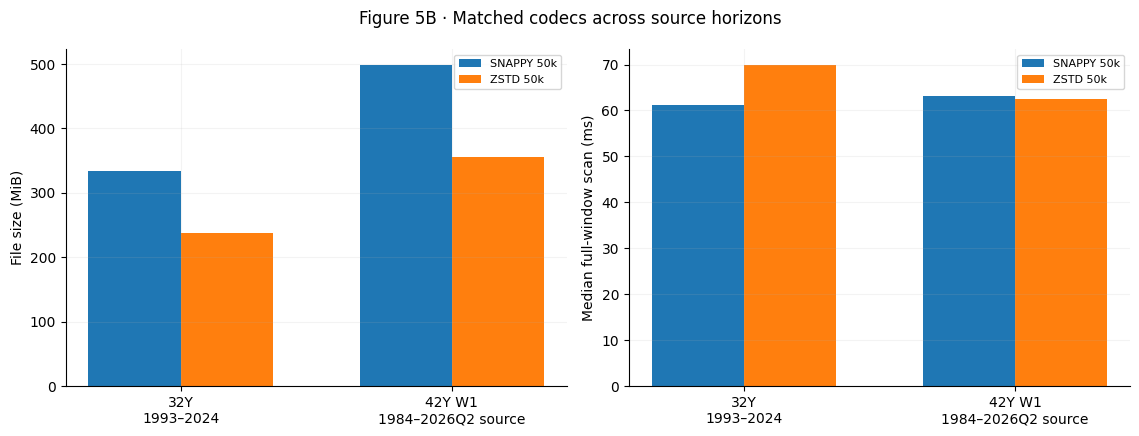

**Interpretation.** Codec savings should be compared within each scope. Runtime changes with row count and source horizon. Existing 32Y storage experiments remain unchanged.

In [58]:

# Figure 5B — 32Y vs full-source storage comparison

if P3_EXPERIMENTS['storage_full_history']['status'] == 'PASS':

    # Original 32Y layouts
    old = (
        P3_STORAGE_TABLE.query(
            'layout in ["snappy_50k", "zstd_50k"]'
        )[['layout', 'rows', 'size_mib']]
        .copy()
    )

    old['scope'] = '32Y W1 · 1993–2024 source'

    # New full-source layouts
    new = P3_STORAGE_FULL_TABLE[
        ['layout', 'rows', 'size_mib']
    ].copy()

    new['scope'] = '42Y W1 · 1984–2026Q2 source'

    sizes = pd.concat(
        [old, new],
        ignore_index=True
    )

    # Original 32Y full scan
    lat_old = P3_STORAGE_SCAN_SUM.query(
        'workload == "full_1993_2024"'
    )

    lat_old = lat_old[
        ['layout', 'median_ms']
    ].copy()

    lat_old['scope'] = old['scope'].iloc[0]

    # Full-source scan
    lat_new = P3_STORAGE_FULL_SCAN_SUM.query(
        'workload == "full_1984_2026Q2"'
    )

    lat_new = lat_new[
        ['layout', 'median_ms']
    ].copy()

    lat_new['scope'] = new['scope'].iloc[0]

    compare = sizes.merge(
        pd.concat([lat_old, lat_new], ignore_index=True),
        on=['scope', 'layout'],
        validate='one_to_one'
    )

    compare['scan_rows_per_s'] = (
        1000 * compare.rows / compare.median_ms
    )

    P3_STORAGE_32_42_COMPARISON = compare

    display(compare.round(2))

    # Comparison charts
    labels = list(dict.fromkeys(compare.scope))
    x = np.arange(len(labels))
    w = 0.34

    fig, (a, b) = plt.subplots(
        1, 2,
        figsize=(11.5, 4.4)
    )

    for axis, metric, unit in (
        (a, 'size_mib', 'File size (MiB)'),
        (b, 'median_ms', 'Median full-window scan (ms)')
    ):

        for j, (layout, title) in enumerate(
            (
                ('snappy_50k', 'SNAPPY 50k'),
                ('zstd_50k', 'ZSTD 50k')
            )
        ):

            values = [
                float(
                    compare.loc[
                        (compare.scope == scope)
                        & (compare.layout == layout),
                        metric
                    ].iloc[0]
                )
                for scope in labels
            ]

            axis.bar(
                x + (j - 0.5) * w,
                values,
                width=w,
                label=title
            )

        axis.set(
            xticks=x,
            xticklabels=[
                '32Y\n1993–2024',
                '42Y W1\n1984–2026Q2 source'
            ],
            ylabel=unit
        )

        axis.legend(fontsize=8)

    fig.suptitle(
        'Figure 5B · Matched codecs across source horizons'
    )

    plt.tight_layout()
    plt.show()

    if 'figure_05b_codec_32_42_comparison' not in P3_FIGURES:
        P3_FIGURES.append(
            'figure_05b_codec_32_42_comparison'
        )

    p3_note(
        'Codec savings should be compared within each scope. '
        'Runtime changes with row count and source horizon. '
        'Existing 32Y storage experiments remain unchanged.'
    )

else:
    print('Figure 5B omitted: full-source storage not executed.')


#### Chart interpretation

**Figure 5B — Interpretation.** Comparing historical versus full-source codec costs reveals whether the preferred row-group/compression choice generalizes after the extension to 2026Q2.

### 3.8.6 — CSV versus Parquet, same 2024 columns

Compare a narrow, typed 2024 projection; verify keys and numerical values first. These timings isolate the storage-format/parser effect.

In [59]:
# 3.8.6a — Controlled 2024 CSV–Parquet A/B and exact population verification
P3_CSV_AB_ENABLED=bool(P3_CFG.get('run_csv_parquet_ab',True))
if P3_CSV_AB_ENABLED:
    P3_CSV_AB_DIR=P3_SCRATCH_DIR/'csv_parquet_ab_2024';P3_CSV_AB_DIR.mkdir(exist_ok=True)
    P3_CSV_AB_CSV=P3_CSV_AB_DIR/'w1_inputs_2024.csv'
    P3_CSV_AB_PQ=P3_CSV_AB_DIR/'w1_inputs_2024_zstd.parquet'
    P3_CSV_AB_SOURCE=(src.filter(pl.col('REPDTE').is_between(_date(2024,1,1),_date(2024,12,31)))
        .select(P3_W1_INPUTS).sort(['CERT','REPDTE']).collect(engine='streaming'))
    assert P3_CSV_AB_SOURCE.height==18399
    P3_CSV_AB_SOURCE.write_csv(P3_CSV_AB_CSV,float_precision=17)
    P3_CSV_AB_SOURCE.write_parquet(P3_CSV_AB_PQ,compression='zstd',row_group_size=50000)
    csv_schema=dict(P3_CSV_AB_SOURCE.schema)
    P3_CSV_AB_SCANS={
        'CSV':pl.scan_csv(str(P3_CSV_AB_CSV),schema_overrides=csv_schema,
                          try_parse_dates=True),
        'ZSTD_Parquet':pl.scan_parquet(str(P3_CSV_AB_PQ))}
    P3_CSV_AB_REF=P3_CSV_AB_SOURCE.sort(['CERT','REPDTE'])
    for name,lazy in P3_CSV_AB_SCANS.items():
        actual=lazy.sort(['CERT','REPDTE']).collect(engine='streaming')
        assert_frame_equal(P3_CSV_AB_REF,actual,check_exact=(name=='ZSTD_Parquet'),
                           atol=1e-8,rtol=1e-10)
        assert actual.height==18399
        del actual
    P3_CSV_AB_SIZES={k:f.stat().st_size/2**20 for k,f in
        [('CSV',P3_CSV_AB_CSV),('ZSTD_Parquet',P3_CSV_AB_PQ)]}
    p3_mark('3.8 CSV–Parquet 2024 value fidelity',True)
    print('Source: 18,399 records / 11 raw W1 columns; source untouched')
    print('Files (MiB):', {k:round(v,3) for k,v in P3_CSV_AB_SIZES.items()})
else:
    P3_EXPERIMENTS['csv_parquet_ab']={'status':'SKIPPED_BY_POLICY'}

PASS  3.8 CSV–Parquet 2024 value fidelity
Source: 18,399 records / 11 raw W1 columns; source untouched
Files (MiB): {'CSV': 4.049, 'ZSTD_Parquet': 0.613}


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\2877164039.py:20: DeprecationWarning: the argument `rtol` for `assert_frame_equal` is deprecated. It was renamed to `rel_tol` in version 1.32.3.
  assert_frame_equal(P3_CSV_AB_REF,actual,check_exact=(name=='ZSTD_Parquet'),
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6880\2877164039.py:20: DeprecationWarning: the argument `atol` for `assert_frame_equal` is deprecated. It was renamed to `abs_tol` in version 1.32.3.
  assert_frame_equal(P3_CSV_AB_REF,actual,check_exact=(name=='ZSTD_Parquet'),


PASS  3.8 CSV–Parquet controlled scans


,format,runs,median_scan_ms,min_scan_ms,max_scan_ms,size_mib,rows
0,CSV,5,9.685,8.379,10.498,4.049,18399
1,ZSTD_Parquet,5,6.335,3.581,6.846,0.613,18399


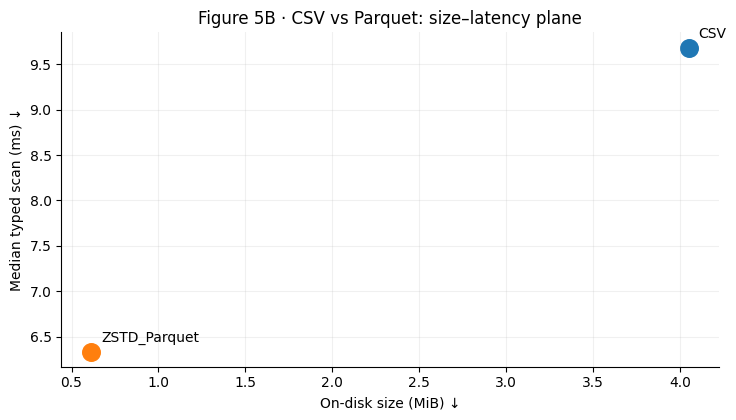

**Interpretation.** This is a **2024 narrow-field format A/B**, not a 42-year production throughput benchmark. Scan costs include CSV parsing or Parquet decoding but exclude file creation.

In [60]:
# 3.8.6b — Warm-cache scan timings and size/latency format comparison
if P3_CSV_AB_ENABLED:
    P3_CSV_AB_TIMINGS=[]
    for name,lazy in P3_CSV_AB_SCANS.items():
        assert lazy.select(pl.len()).collect(engine='streaming').item()==18399
        lazy.collect(engine='streaming')  # Warm-up, excluded from timing.
        for repetition in range(1,6):
            t0=time.perf_counter()
            materialized=lazy.collect(engine='streaming')
            elapsed=(time.perf_counter()-t0)*1000
            P3_CSV_AB_TIMINGS.append({'format':name,'rep':repetition,'ms':elapsed,
                'rows':materialized.height,'size_mib':P3_CSV_AB_SIZES[name]})
            del materialized
    P3_CSV_AB_RAW=pd.DataFrame(P3_CSV_AB_TIMINGS)
    P3_CSV_AB_SUM=(P3_CSV_AB_RAW.groupby('format',as_index=False)
        .agg(runs=('rep','count'),median_scan_ms=('ms','median'),
             min_scan_ms=('ms','min'),max_scan_ms=('ms','max'),
             size_mib=('size_mib','first'),rows=('rows','first')))
    valid=bool(len(P3_CSV_AB_RAW)==10 and P3_CSV_AB_SUM.runs.eq(5).all()
        and P3_CSV_AB_RAW.rows.eq(18399).all() and P3_CSV_AB_RAW.ms.gt(0).all())
    p3_mark('3.8 CSV–Parquet controlled scans',valid)
    P3_EXPERIMENTS['csv_parquet_ab']={'status':'PASS','rows':18399,
        'columns':11,'warm_cache':True,'repetitions_per_layout':5,
        'fidelity':'CSV numeric atol 1e-8; Parquet exact',
        'results':P3_CSV_AB_SUM.round(4).to_dict('records')}
    display(P3_CSV_AB_SUM.round(3))
    fig,ax=plt.subplots(figsize=(7.5,4.3))
    for name in ['CSV','ZSTD_Parquet']:
        r=P3_CSV_AB_SUM.loc[P3_CSV_AB_SUM['format']==name].iloc[0]
        ax.scatter(r['size_mib'],r['median_scan_ms'],s=160,
                   label=f'{name} ({int(r["runs"])} runs)')
        ax.annotate(name,(r['size_mib'],r['median_scan_ms']),xytext=(7,7),
                    textcoords='offset points')
    ax.set(xlabel='On-disk size (MiB) ↓',ylabel='Median typed scan (ms) ↓',
        title='Figure 5B · CSV vs Parquet: size–latency plane')
    ax.grid(alpha=.18);plt.tight_layout();plt.show()
    if 'figure_05b_csv_parquet' not in P3_FIGURES:
        P3_FIGURES.append('figure_05b_csv_parquet')
    p3_note('This is a **2024 narrow-field format A/B**, not a 42-year production throughput '
            'benchmark. Scan costs include CSV parsing or Parquet decoding but exclude file creation.')
else:
    print('CSV–Parquet benchmark SKIPPED.')

<a id="p3-9"></a>
## 3.9 — Spark AQE, shuffle and caching

Spark labs are expensive optional experiments. Their verified numerical scope is **2024 W1**, not the 1985–2026Q2 production panel. Keep skipped experiments distinct from PASS.

### Archived evidence C — AQE/shuffle configuration sensitivity

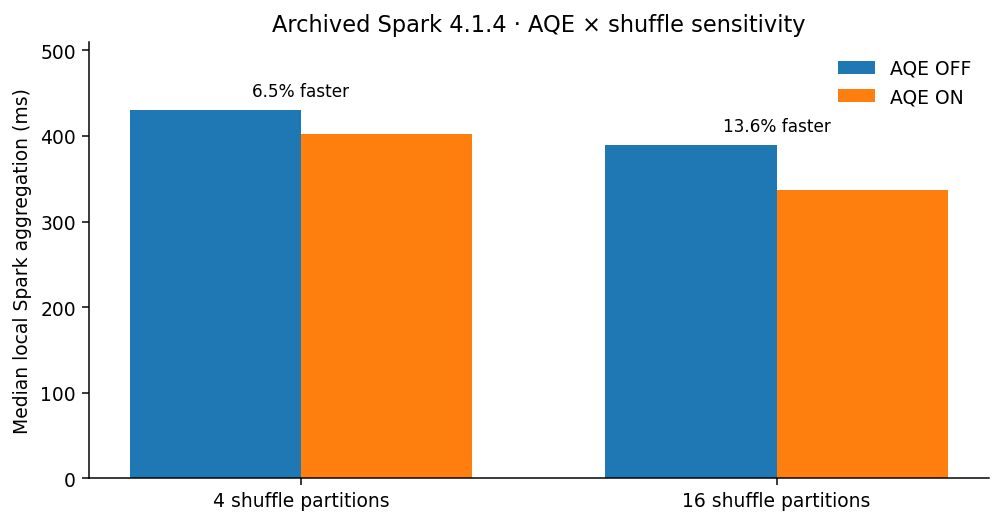

**Reading:** AQE improved the **2017–2024 aggregation workload** under both tested shuffle counts; the best median was **336.47 ms at AQE ON / 16 partitions**. This is **not** proof of full-history Spark W1 equivalence.

*Figure uses archived measurements from the executed input notebook; new current-run charts appear below and must be run locally.*

In [61]:

# ============================================================
# 3.9.1 — SPARK SESSION STARTUP
# No RAM threshold check
# ============================================================

from pyspark.sql import SparkSession, functions as F
import gc

gc.collect()

P3_CFG["run_spark_labs"] = True
P3_SPARK_READY = False

print("=" * 65)
print("3.9.1 — SPARK INITIALIZATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Reuse an active Spark session if available
# ------------------------------------------------------------

existing_spark = globals().get("spark")

try:
    context = getattr(existing_spark, "sparkContext", None)
    jsc = getattr(context, "_jsc", None)

    reusable = (
        jsc is not None
        and not jsc.sc().isStopped()
    )
except Exception:
    reusable = False

# ------------------------------------------------------------
# 2. Initialize Spark
# ------------------------------------------------------------

if reusable:
    spark = existing_spark
    print("Reusing active Spark session.")

else:
    spark = (
        SparkSession.builder
        .master("local[2]")
        .appName("FDIC_P3_Spark_2026Q2")
        .config("spark.driver.memory", "1g")
        .config("spark.driver.maxResultSize", "256m")
        .config("spark.sql.shuffle.partitions", "4")
        .config("spark.sql.adaptive.enabled", "true")
        .config(
            "spark.sql.adaptive.coalescePartitions.enabled",
            "true"
        )
        .config(
            "spark.sql.execution.arrow.pyspark.enabled",
            "false"
        )
        .config("spark.ui.enabled", "false")
        .getOrCreate()
    )

spark.sparkContext.setLogLevel("ERROR")

# ------------------------------------------------------------
# 3. Validate Spark execution
# ------------------------------------------------------------

smoke_count = spark.range(10).count()

jsc = getattr(spark.sparkContext, "_jsc", None)

P3_SPARK_READY = bool(
    jsc is not None
    and not jsc.sc().isStopped()
    and smoke_count == 10
)

# ------------------------------------------------------------
# 4. Register experiment
# ------------------------------------------------------------

P3_EXPERIMENTS["spark"] = {
    "status": "READY" if P3_SPARK_READY else "FAILED",
    "version": spark.version,
    "master": spark.sparkContext.master,
    "smoke_test_rows": smoke_count,
    "workload": "2024 W1 parity and 2017–2024 tuning"
}

# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("\nSpark version:", spark.version)
print("Master:", spark.sparkContext.master)
print("Smoke test:", smoke_count, "/ 10")
print("P3_SPARK_READY:", P3_SPARK_READY)

assert P3_SPARK_READY, "Spark initialization failed."

print("\nSPARK INITIALIZATION: PASS")


3.9.1 — SPARK INITIALIZATION

Spark version: 4.1.4
Master: local[2]
Smoke test: 10 / 10
P3_SPARK_READY: True

SPARK INITIALIZATION: PASS


In [62]:
# 3.9.2 — Fresh 2024 Spark W1 parity against independent pandas and Polars
# Uses the exact calendar-quarter Spark implementation from 3.6.4a.
P3_SPARK_PARITY_PASS=False
if P3_SPARK_READY:
    sp2024=p3_3e_spark_w1_query().toPandas()
    pol2024=p3_collect(p3_w1_window(2024,2024)).to_pandas()
    pd2024=(P3_3E_REFERENCE if P3_3E_REFERENCE is not None
            else p3_3e_run('pandas'))
    k_pd,r_pd=p3_compare_frames(pd2024,sp2024,'pandas_vs_spark_2024')
    k_pl,r_pl=p3_compare_frames(pol2024,sp2024,'polars_vs_spark_2024')
    invalid=['null_errors','numeric_errors','nonfinite_errors']
    P3_SPARK_PARITY_PASS=bool(len(sp2024)==18399 and len(pol2024)==18399 and
        len(pd2024)==18399 and k_pd==0 and k_pl==0 and
        r_pd[invalid].to_numpy().sum()==0 and r_pl[invalid].to_numpy().sum()==0)
    p3_mark('3.9 2024 Spark W1 numerical parity',P3_SPARK_PARITY_PASS)
    P3_SPARK_PARITY_AUDIT=pd.concat([r_pd,r_pl],ignore_index=True)
    display(P3_SPARK_PARITY_AUDIT[['block','feature','null_errors','numeric_errors',
              'nonfinite_errors','max_abs_error']].round(9))
    P3_EXPERIMENTS['spark_w1_2024']={'status':'PASS' if P3_SPARK_PARITY_PASS else 'FAIL',
        'rows':len(sp2024),'features':len(P3_W1_FEATURES),
        'comparators':['independent pandas','Polars calendar-aware window'],
        'full_history_spark_parity':'NOT_TESTED'}
    print('2024 Spark W1 parity:',P3_SPARK_PARITY_PASS,'| 2023 lookback included')
    del sp2024,pol2024
    if P3_3E_REFERENCE is None:del pd2024
    gc.collect()
else:
    P3_EXPERIMENTS['spark_w1_2024']={'status':'SKIPPED_NO_SPARK_SESSION'}
    print('2024 Spark W1 parity SKIPPED. Existing pandas–Polars full-history parity remains separate.')

PASS  3.9 2024 Spark W1 numerical parity


,block,feature,null_errors,numeric_errors,nonfinite_errors,max_abs_error
0,pandas_vs_spark_2024,equity_to_assets,0,0,0,0.0
1,pandas_vs_spark_2024,deposits_to_assets,0,0,0,0.0
2,pandas_vs_spark_2024,cash_to_assets,0,0,0,0.0
3,pandas_vs_spark_2024,securities_to_assets,0,0,0,0.0
4,pandas_vs_spark_2024,core_deposit_share,0,0,0,0.0
5,pandas_vs_spark_2024,noncurrent_loan_ratio,0,0,0,0.0
6,pandas_vs_spark_2024,asset_growth_4q,0,0,0,0.0
7,pandas_vs_spark_2024,roa_rolling_mean_4q,0,0,0,0.0
8,pandas_vs_spark_2024,roa_rolling_std_4q,0,0,0,0.0
9,polars_vs_spark_2024,equity_to_assets,0,0,0,0.0


2024 Spark W1 parity: True | 2023 lookback included


In [63]:

# ============================================================
# PHASE 3 | SECTION 3.9.2A
# POLARS & SPARK EXECUTION PLAN DIAGNOSTICS
# Compatible with upgraded Phase 3 notebook
# ============================================================

import inspect

assert P3_SPARK_PARITY_PASS, (
    "Run Section 3.9.2 — Spark W1 parity first."
)

# ------------------------------------------------------------
# 1. Verify active Spark session
# ------------------------------------------------------------

spark_context = getattr(
    globals().get("spark"), "sparkContext", None
)

jsc = getattr(spark_context, "_jsc", None)

spark_active = bool(
    jsc is not None and not jsc.sc().isStopped()
)

if not spark_active:
    raise RuntimeError(
        "Spark session is stopped. Rerun Section 3.9.1 "
        "before executing this cell."
    )

# ------------------------------------------------------------
# 2. Build lazy queries (no collect)
# ------------------------------------------------------------

P3_W1_PL_PLAN_QUERY = p3_w1_window(
    2024, 2024
)

P3_W1_SPARK_PLAN_QUERY = (
    p3_3e_spark_w1_query()
)

# ------------------------------------------------------------
# 3. Polars execution plans
# ------------------------------------------------------------

P3_PL_UNOPT_PLAN = (
    P3_W1_PL_PLAN_QUERY.explain(optimized=False)
)

# Preserve the same optimization policy as p3_collect().
explain_params = inspect.signature(
    pl.LazyFrame.explain
).parameters

if "optimizations" in explain_params:

    P3_PL_OPT_PLAN = (
        P3_W1_PL_PLAN_QUERY.explain(
            optimized=True,
            optimizations=P3_NO_PUSHDOWN
        )
    )

elif "predicate_pushdown" in explain_params:

    P3_PL_OPT_PLAN = (
        P3_W1_PL_PLAN_QUERY.explain(
            optimized=True,
            predicate_pushdown=False
        )
    )

else:
    raise RuntimeError(
        "Cannot verify predicate-pushdown settings "
        "for this Polars version."
    )

# ------------------------------------------------------------
# 4. Spark optimized and physical plans
# ------------------------------------------------------------

spark_qe = (
    P3_W1_SPARK_PLAN_QUERY
    ._jdf
    .queryExecution()
)

P3_SPARK_OPT_PLAN = (
    spark_qe.optimizedPlan().toString()
)

P3_SPARK_PHYSICAL_PLAN = (
    spark_qe.executedPlan().toString()
)

P3_SPARK_PLAN_IS_FINAL = (
    "isfinalplan=true"
    in P3_SPARK_PHYSICAL_PLAN.lower().replace(" ", "")
)

# ------------------------------------------------------------
# 5. Operator diagnostics
# ------------------------------------------------------------

plan_keywords = [
    "PARQUET", "SCAN", "PROJECT", "FILTER",
    "JOIN", "BROADCAST", "EXCHANGE",
    "SHUFFLE", "SORT", "AGGREGATE",
    "ADAPTIVE", "REUSED"
]

plan_map = {
    "Polars unoptimized": P3_PL_UNOPT_PLAN,
    "Polars optimized": P3_PL_OPT_PLAN,
    "Spark optimized logical": P3_SPARK_OPT_PLAN,
    "Spark physical": P3_SPARK_PHYSICAL_PLAN
}


##### Run block 2/2 — continuation of original code cell 84

Run sequentially; the original code statements and their order are unchanged.

In [64]:

P3_PLAN_SUMMARY = pd.DataFrame([
    {
        "plan": name,
        "characters": len(plan),
        "lines": len(plan.splitlines()),
        **{
            keyword.lower(): sum(
                keyword in line.upper()
                for line in plan.splitlines()
            )
            for keyword in plan_keywords
        }
    }
    for name, plan in plan_map.items()
])

# ------------------------------------------------------------
# 6. Display relevant operators
# ------------------------------------------------------------

def p3_show_plan_excerpt(plan, title, max_lines=15):

    tokens = [
        "PARQUET", "SCAN", "FILTER", "PROJECT",
        "JOIN", "BROADCAST", "EXCHANGE",
        "SHUFFLE", "SORT", "AGGREGATE",
        "ADAPTIVE", "REUSED"
    ]

    selected = [
        line.strip()
        for line in plan.splitlines()
        if any(
            token in line.upper()
            for token in tokens
        )
    ]

    print(f"\n{title}")
    print(
        f"Relevant lines: {len(selected)} | "
        f"Showing: {min(len(selected), max_lines)}"
    )

    for line in selected[:max_lines]:
        print(line[:220])


print("=" * 72)
print("3.9.2A — EXECUTION PLAN DIAGNOSTICS")
print("=" * 72)

print("\n[1] PLAN STRUCTURE SUMMARY")
display(P3_PLAN_SUMMARY)

for title, plan in [
    ("[2] POLARS UNOPTIMIZED", P3_PL_UNOPT_PLAN),
    ("[3] POLARS OPTIMIZED", P3_PL_OPT_PLAN),
    ("[4] SPARK OPTIMIZED LOGICAL", P3_SPARK_OPT_PLAN),
    ("[5] SPARK PHYSICAL", P3_SPARK_PHYSICAL_PLAN)
]:
    p3_show_plan_excerpt(plan, title)

# ------------------------------------------------------------
# 7. Acceptance
# ------------------------------------------------------------

P3_PLAN_DIAGNOSTICS_PASS = bool(
    len(P3_PLAN_SUMMARY) == 4
    and P3_PLAN_SUMMARY["characters"].gt(0).all()
    and P3_PLAN_SUMMARY["lines"].gt(0).all()
    and spark_active
    and P3_SPARK_PARITY_PASS
)

print("\n[6] EXECUTION CONTEXT")
print("Polars version:", pl.__version__)
print("Spark version:", spark.version)
print("Input period: 2023–2024")
print("Output period: 2024")
print("W1 features:", len(P3_W1_FEATURES))
print("Predicate pushdown: DISABLED")
print("Spark session active:", spark_active)
print("Spark final AQE plan:", P3_SPARK_PLAN_IS_FINAL)
print("Spark action triggered: NO")
print("Runtime measured: NO")

print("\n[7] ACCEPTANCE")
print("PLAN DIAGNOSTICS PASS:", P3_PLAN_DIAGNOSTICS_PASS)

assert P3_PLAN_DIAGNOSTICS_PASS


3.9.2A — EXECUTION PLAN DIAGNOSTICS

[1] PLAN STRUCTURE SUMMARY


,plan,characters,lines,parquet,scan,project,filter,join,broadcast,exchange,shuffle,sort,aggregate,adaptive,reused
0,Polars unoptimized,5298,25,1,1,1,2,0,0,0,0,2,0,0,0
1,Polars optimized,5864,32,1,1,1,2,0,0,0,0,1,0,0,0
2,Spark optimized logical,7862,25,5,0,10,5,4,0,0,0,1,0,0,0
3,Spark physical,10414,37,5,5,10,10,4,0,6,0,10,0,1,0



[2] POLARS UNOPTIMIZED
Relevant lines: 6 | Showing: 6
SORT BY [col("CERT"), col("REPDTE")]
FILTER col("REPDTE") >= 2024-01-01
SORT BY [col("CERT"), col("REPDTE")]
FILTER col("REPDTE").is_between([2023-01-01, 2024-12-31])
Parquet SCAN [C:/học tập/kì 7/Big data/Final/Bản nháp/data/silver/full_history/contract_a1cd7440e6a09ca8/run_aee2d40b147b0be5bd14/clean_bank_quarter.parquet]
PROJECT */141 COLUMNS

[3] POLARS OPTIMIZED
Relevant lines: 5 | Showing: 5
FILTER (col("REPDTE") >= 2024-01-01)
SORT BY [col("CERT"), col("REPDTE")]
FILTER col("REPDTE").is_between([2023-01-01, 2024-12-31])
Parquet SCAN [C:/học tập/kì 7/Big data/Final/Bản nháp/data/silver/full_history/contract_a1cd7440e6a09ca8/run_aee2d40b147b0be5bd14/clean_bank_quarter.parquet]
PROJECT 11/141 COLUMNS

[4] SPARK OPTIMIZED LOGICAL
Relevant lines: 25 | Showing: 15
Sort [CERT#5868L ASC NULLS FIRST, REPDTE#5869 ASC NULLS FIRST], true
+- Project [CERT#5868L, REPDTE#5869, equity_to_assets#6591, deposits_to_assets#6592, cash_to_assets#6

In [65]:

# ============================================================
# PHASE 3 | SECTION 3.9.2B
# TARGETED QUERY OPTIMIZER EVIDENCE
# Compatible with upgraded Phase 3 notebook (2026Q2)
# ============================================================

assert P3_SPARK_PARITY_PASS, "Run Section 3.9.2 first."
assert P3_PLAN_DIAGNOSTICS_PASS, "Run Section 3.9.2A first."

required_plans = [
    "P3_PL_UNOPT_PLAN",
    "P3_PL_OPT_PLAN",
    "P3_SPARK_OPT_PLAN",
    "P3_SPARK_PHYSICAL_PLAN"
]

missing_plans = [
    name for name in required_plans
    if name not in globals()
]

assert not missing_plans, (
    f"Missing execution plans: {missing_plans}"
)

# ------------------------------------------------------------
# 1. Extract relevant plan evidence
# ------------------------------------------------------------

def p3_extract_plan_evidence(
    plan,
    keywords,
    max_matches=20,
    max_width=240
):
    matches = []

    for line_number, line in enumerate(
        plan.splitlines(), start=1
    ):
        if any(
            keyword.upper() in line.upper()
            for keyword in keywords
        ):
            matches.append({
                "line": line_number,
                "operator": line.strip()[:max_width]
            })

    return matches[:max_matches], len(matches)


def p3_display_plan_evidence(
    title,
    plan,
    keywords,
    max_matches=20
):

    matches, total = p3_extract_plan_evidence(
        plan,
        keywords,
        max_matches=max_matches
    )

    print(f"\n{title}")
    print(f"Matching operator lines: {total}")

    if matches:
        display(pd.DataFrame(matches))
    else:
        print("No matching operator lines identified.")


# ------------------------------------------------------------
# 2. Polars optimizer evidence
# ------------------------------------------------------------

print("=" * 72)
print("3.9.2B — TARGETED QUERY OPTIMIZER EVIDENCE")
print("=" * 72)

p3_display_plan_evidence(
    "[1] POLARS — SOURCE SCAN & COLUMN PROJECTION",
    P3_PL_OPT_PLAN,
    ["PARQUET", "SCAN", "PROJECT"],
    max_matches=15
)

p3_display_plan_evidence(
    "[2] POLARS — SHARED SUBPLANS / CACHE",
    P3_PL_OPT_PLAN,
    ["CACHE", "CSE", "COMMON SUBPLAN"],
    max_matches=20
)

p3_display_plan_evidence(
    "[3] POLARS — TEMPORAL FILTERS & JOINS",
    P3_PL_OPT_PLAN,
    [
        "FILTER", "SELECTION",
        "2023", "2024", "JOIN"
    ],
    max_matches=25
)

# ------------------------------------------------------------
# 3. Spark optimized logical plan
# ------------------------------------------------------------

p3_display_plan_evidence(
    "[4] SPARK — OPTIMIZED LOGICAL OPERATORS",
    P3_SPARK_OPT_PLAN,
    [
        "RELATION", "FILTER",
        "JOIN", "PROJECT"
    ],
    max_matches=18
)

# ------------------------------------------------------------
# 4. Spark physical plan
# ------------------------------------------------------------

p3_display_plan_evidence(
    "[5] SPARK — PARQUET FILE SCANS",
    P3_SPARK_PHYSICAL_PLAN,
    [
        "FILESCAN", "BATCHSCAN",
        "PUSHEDFILTERS", "READSCHEMA"
    ],
    max_matches=18
)


3.9.2B — TARGETED QUERY OPTIMIZER EVIDENCE

[1] POLARS — SOURCE SCAN & COLUMN PROJECTION
Matching operator lines: 2


,line,operator
0,30,Parquet SCAN [C:/học tập/kì 7/Big data/Final/B...
1,31,PROJECT 11/141 COLUMNS



[2] POLARS — SHARED SUBPLANS / CACHE
Matching operator lines: 4


,line,operator
0,11,"[col(""ROA"").alias(""_roa0""), when(col(""__POLARS..."
1,13,"[(col(""qi"") - col(""prev_q1"")).alias(""__POLARS_..."
2,22,"[col(""qi"").shift([dyn int: 1]).over([col(""CERT..."
3,24,"[(col(""ASSET"") > 0.0).alias(""__POLARS_CSER_0x1..."



[3] POLARS — TEMPORAL FILTERS & JOINS
Matching operator lines: 2


,line,operator
0,1,"FILTER (col(""REPDTE"") >= 2024-01-01)"
1,28,"FILTER col(""REPDTE"").is_between([2023-01-01, 2..."



[4] SPARK — OPTIMIZED LOGICAL OPERATORS
Matching operator lines: 24


,line,operator
0,2,"+- Project [CERT#5868L, REPDTE#5869, equity_to..."
1,3,"+- Project [CERT#5868L, REPDTE#5869, ROA#5874,..."
2,4,"+- Join LeftOuter, ((CERT#5868L = CERT#6448L) ..."
3,5,":- Project [CERT#5868L, qi#6010, REPDTE#5869, ..."
4,6,": +- Join LeftOuter, ((CERT#5868L = CERT#6303..."
5,7,": :- Project [CERT#5868L, qi#6010, REPDTE#..."
6,8,": : +- Join LeftOuter, ((CERT#5868L = CER..."
7,9,": : :- Project [CERT#5868L, qi#6010, R..."
8,10,": : : +- Join LeftOuter, ((CERT#5868L..."
9,11,": : : :- Project [CERT#5868L, REPD..."



[5] SPARK — PARQUET FILE SCANS
Matching operator lines: 5


,line,operator
0,17,: : : : +- FileScan parq...
1,22,: : : +- FileScan parq...
2,27,: : +- FileScan parquet [C...
3,32,: +- FileScan parquet [CERT#63...
4,37,"+- FileScan parquet [CERT#6448L,REPDTE#6449,AS..."


##### Run block 2/3 — continuation of original code cell 85

Run sequentially; the original code statements and their order are unchanged.

In [66]:

p3_display_plan_evidence(
    "[6] SPARK — JOIN STRATEGIES",
    P3_SPARK_PHYSICAL_PLAN,
    [
        "BROADCASTHASHJOIN",
        "SORTMERGEJOIN",
        "SHUFFLEDHASHJOIN",
        "BROADCASTNESTEDLOOPJOIN"
    ],
    max_matches=20
)

p3_display_plan_evidence(
    "[7] SPARK — SHUFFLE, REUSE & AQE",
    P3_SPARK_PHYSICAL_PLAN,
    [
        "EXCHANGE",
        "REUSEDEXCHANGE",
        "AQESHUFFLEREAD",
        "SHUFFLEQUERYSTAGE",
        "ADAPTIVESPARKPLAN",
        "ISFINALPLAN"
    ],
    max_matches=25
)

# ------------------------------------------------------------
# 5. Operator detection
# ------------------------------------------------------------

polars_upper = P3_PL_OPT_PLAN.upper()
spark_upper = P3_SPARK_PHYSICAL_PLAN.upper()

P3_OPTIMIZER_EVIDENCE = pd.DataFrame([
    {
        "engine": "Polars",
        "mechanism": "Parquet source scan",
        "detected": (
            "PARQUET SCAN" in polars_upper
            or "SCAN PARQUET" in polars_upper
            or "PARQUET" in polars_upper
        )
    },
    {
        "engine": "Polars",
        "mechanism": "Column projection",
        "detected": "PROJECT" in polars_upper
    },
    {
        "engine": "Polars",
        "mechanism": "Cache / shared subplan",
        "detected": (
            "CACHE" in polars_upper
            or "COMMON SUBPLAN" in polars_upper
        )
    },
    {
        "engine": "Polars",
        "mechanism": "Join operation",
        "detected": "JOIN" in polars_upper
    },
    {
        "engine": "Spark",
        "mechanism": "Parquet FileScan",
        "detected": (
            "FILESCAN" in spark_upper
            or "BATCHSCAN" in spark_upper
        )
    },
    {
        "engine": "Spark",
        "mechanism": "Broadcast hash join",
        "detected": "BROADCASTHASHJOIN" in spark_upper
    },
    {
        "engine": "Spark",
        "mechanism": "Sort-merge join",
        "detected": "SORTMERGEJOIN" in spark_upper
    },
    {
        "engine": "Spark",
        "mechanism": "Exchange",
        "detected": "EXCHANGE" in spark_upper
    },
    {
        "engine": "Spark",
        "mechanism": "Exchange reuse",
        "detected": "REUSEDEXCHANGE" in spark_upper
    },
    {
        "engine": "Spark",
        "mechanism": "Adaptive Query Execution",
        "detected": "ADAPTIVESPARKPLAN" in spark_upper
    },
    {
        "engine": "Spark",
        "mechanism": "Final adaptive plan",
        "detected": (
            "ISFINALPLAN=TRUE"
            in spark_upper.replace(" ", "")
        )
    }
])

print("\n[8] OPTIMIZER EVIDENCE FLAGS")
display(P3_OPTIMIZER_EVIDENCE)

# ------------------------------------------------------------
# 6. Interpretation and evidence limitations
# ------------------------------------------------------------

P3_OPTIMIZER_EVIDENCE_PASS = bool(
    len(P3_OPTIMIZER_EVIDENCE) == 11
    and all(
        isinstance(plan, str) and len(plan) > 0
        for plan in [
            P3_PL_OPT_PLAN,
            P3_SPARK_OPT_PLAN,
            P3_SPARK_PHYSICAL_PLAN
        ]
    )
)



[6] SPARK — JOIN STRATEGIES
Matching operator lines: 4


,line,operator
0,6,"+- SortMergeJoin [CERT#5868L, qi#6010], [CERT#..."
1,8,": +- SortMergeJoin [CERT#5868L, qi#6010], [CE..."
2,10,": : +- SortMergeJoin [CERT#5868L, qi#6010..."
3,12,": : : +- SortMergeJoin [CERT#5868L, q..."



[7] SPARK — SHUFFLE, REUSE & AQE
Matching operator lines: 7


,line,operator
0,1,AdaptiveSparkPlan isFinalPlan=false
1,3,+- Exchange rangepartitioning(CERT#5868L ASC N...
2,14,: : : : +- Exchange hashpartition...
3,19,: : : +- Exchange hashpartition...
4,24,: : +- Exchange hashpartitioning(CE...
5,29,: +- Exchange hashpartitioning(CERT#630...
6,34,"+- Exchange hashpartitioning(CERT#6448L, qi#64..."



[8] OPTIMIZER EVIDENCE FLAGS


,engine,mechanism,detected
0,Polars,Parquet source scan,True
1,Polars,Column projection,True
2,Polars,Cache / shared subplan,False
3,Polars,Join operation,False
4,Spark,Parquet FileScan,True
5,Spark,Broadcast hash join,False
6,Spark,Sort-merge join,True
7,Spark,Exchange,True
8,Spark,Exchange reuse,False
9,Spark,Adaptive Query Execution,True


##### Run block 3/3 — continuation of original code cell 85

Run sequentially; the original code statements and their order are unchanged.

In [67]:

print("\n[9] INTERPRETATION")

print(
    "Detected=True means the operator marker appears "
    "in the inspected plan text."
)

print(
    "Detected=False means the marker was not found; "
    "it does not indicate an execution failure."
)

print(
    "Spark physical plan status:",
    "FINAL" if P3_SPARK_PLAN_IS_FINAL else "PRE-ACTION"
)

print(
    "AQE may change shuffle strategies and physical "
    "operators after Spark executes an action."
)

print(
    "No runtime speedup or physical I/O reduction "
    "is established by keyword detection alone."
)

print("\n[10] ACCEPTANCE")
print(
    "OPTIMIZER EVIDENCE PASS:",
    P3_OPTIMIZER_EVIDENCE_PASS
)

assert P3_OPTIMIZER_EVIDENCE_PASS

print("\nSpark action triggered: NO")
print("Source data modified: NO")
print("Optimizer evidence inspection complete.")



[9] INTERPRETATION
Detected=True means the operator marker appears in the inspected plan text.
Detected=False means the marker was not found; it does not indicate an execution failure.
Spark physical plan status: PRE-ACTION
AQE may change shuffle strategies and physical operators after Spark executes an action.
No runtime speedup or physical I/O reduction is established by keyword detection alone.

[10] ACCEPTANCE
OPTIMIZER EVIDENCE PASS: True

Spark action triggered: NO
Source data modified: NO
Optimizer evidence inspection complete.


In [68]:
# 3.9.3 — AQE ON/OFF × 4/16 shuffle partitions with post-action physical plans
P3_SPARK_TUNE_RESULTS=[];P3_SPARK_PLAN_AUDIT=[]
if P3_SPARK_READY:
    P3_SPARK8_EXPECTED=int(P3_YEARS.filter(pl.col('year').is_between(2017,2024))['rows'].sum())
    source8=(spark.read.parquet(str(P3_SILVER_PATH))
           .filter(F.col('REPDTE').between('2017-01-01','2024-12-31'))
           .select('CERT','REPDTE','ASSET','ROA'))
    before={k:spark.conf.get(k) for k in ['spark.sql.adaptive.enabled',
                                           'spark.sql.shuffle.partitions']}
    def sp_action(df):
        agg=(df.groupBy('CERT',F.year('REPDTE').alias('reporting_year'))
             .agg(F.count('*').alias('n'),F.avg('ASSET').alias('avg_asset'),
                  F.avg('ROA').alias('avg_roa')))
        rows=agg.collect()  # Eager action; completed before inspecting executedPlan.
        plan=agg._jdf.queryExecution().executedPlan().toString()
        return sum(int(r['n']) for r in rows),len(rows),plan
    try:
        for aqe in (False,True):
            for parts in (4,16):
                spark.conf.set('spark.sql.adaptive.enabled',str(aqe).lower())
                spark.conf.set('spark.sql.shuffle.partitions',str(parts))
                n,groups,plan=sp_action(source8)
                assert n==P3_SPARK8_EXPECTED
                P3_SPARK_PLAN_AUDIT.append({'aqe':aqe,'partitions':parts,
                    'adaptive_plan':'AdaptiveSparkPlan' in plan,
                    'exchange':'Exchange' in plan,
                    'aqe_final_plan_marker':'isFinalPlan=true' in plan,
                    'adaptive_shuffle_read':'AQEShuffleRead' in plan,
                    'plan_lines':len(plan.splitlines()),'plan_preview':plan[:360]})
                for rep in range(1,4):
                    t0=time.perf_counter();n,groups,_=sp_action(source8)
                    P3_SPARK_TUNE_RESULTS.append({'aqe':aqe,'partitions':parts,'rep':rep,
                        'ms':1000*(time.perf_counter()-t0),'n':n,'groups':groups})
    finally:
        for k,v in before.items():spark.conf.set(k,v)
    P3_SPARK_TUNING=pd.DataFrame(P3_SPARK_TUNE_RESULTS)
    P3_SPARK_TUNING_SUM=(P3_SPARK_TUNING.groupby(['aqe','partitions'],as_index=False)
       .agg(median_ms=('ms','median'),runs=('rep','count'),rows=('n','first'),
            groups=('groups','first')))
    P3_SPARK_PLANS=pd.DataFrame(P3_SPARK_PLAN_AUDIT)
    plan_ok=(P3_SPARK_PLANS['exchange'].all() and
             (P3_SPARK_PLANS['adaptive_plan']==P3_SPARK_PLANS['aqe']).all())
    tuning_ok=(len(P3_SPARK_TUNING)==12 and
               P3_SPARK_TUNING['n'].eq(P3_SPARK8_EXPECTED).all() and
               P3_SPARK_TUNING['ms'].gt(0).all() and
               P3_SPARK_TUNING.groupby(['aqe','partitions']).size().eq(3).all())
    p3_mark('3.9 Spark AQE/shuffle controlled executions',bool(plan_ok and tuning_ok))
    P3_EXPERIMENTS['spark_tuning']={'status':'PASS','executions':12,
       'tested_shuffles':[4,16],'aqe':[False,True],'source_rows':P3_SPARK8_EXPECTED,
       'local_only':True,'full_history_w1_parity':'NOT_TESTED'}
    display(P3_SPARK_TUNING_SUM.round(2))
    display(P3_SPARK_PLANS.drop(columns=['plan_preview']))
else:
    P3_EXPERIMENTS['spark_tuning']={'status':'SKIPPED_NO_SPARK_SESSION'}

PASS  3.9 Spark AQE/shuffle controlled executions


,aqe,partitions,median_ms,runs,rows,groups
0,False,4,429.90,3,163894,41559
1,False,16,408.21,3,163894,41559
2,True,4,348.68,3,163894,41559
3,True,16,327.46,3,163894,41559


,aqe,partitions,adaptive_plan,exchange,aqe_final_plan_marker,adaptive_shuffle_read,plan_lines
0,False,4,False,True,False,False,7
1,False,16,False,True,False,False,7
2,True,4,True,True,True,True,19
3,True,16,True,True,True,True,19


#### Interpretation — Physical Spark plans

`AdaptiveSparkPlan` or `Exchange` indicates plan structure, not that adaptive execution necessarily made a job faster. Draw conclusions from measured, matched actions.

In [69]:
# 3.9.4 — Materialized cache reuse; include explicit materialization timing
if P3_SPARK_READY:
    original={k:spark.conf.get(k) for k in ['spark.sql.adaptive.enabled','spark.sql.shuffle.partitions']}
    raw_cache=[];cached=None
    try:
        spark.conf.set('spark.sql.adaptive.enabled','true')
        spark.conf.set('spark.sql.shuffle.partitions','4')
        for _ in range(1):sp_action(source8)
        for rep in range(1,4):
            t=time.perf_counter();n,groups,_=sp_action(source8)
            raw_cache.append({'mode':'uncached','rep':rep,'ms':(time.perf_counter()-t)*1000,'rows':n})
        t=time.perf_counter();cached=source8.cache();cache_count=cached.count()
        materialize_ms=(time.perf_counter()-t)*1000
        assert cache_count==163894
        sp_action(cached)
        for rep in range(1,4):
            t=time.perf_counter();n,groups,_=sp_action(cached)
            raw_cache.append({'mode':'cached','rep':rep,'ms':(time.perf_counter()-t)*1000,'rows':n})
    finally:
        if cached is not None: cached.unpersist(blocking=True)
        for k,v in original.items():spark.conf.set(k,v)
    P3_SPARK_CACHE_RAW=pd.DataFrame(raw_cache)
    P3_SPARK_CACHE_SUM=P3_SPARK_CACHE_RAW.groupby('mode',as_index=False).agg(
        median_ms=('ms','median'),runs=('rep','count'),correct=('rows',lambda s:bool((s==163894).all())))
    p3_mark('3.9 Spark cached/uncached repeated actions',len(raw_cache)==6 and
       P3_SPARK_CACHE_SUM.correct.all())
    display(P3_SPARK_CACHE_SUM.round(2));print('Cache setup cost:',round(materialize_ms,1),'ms; NOT included in repeat medians')

PASS  3.9 Spark cached/uncached repeated actions


,mode,median_ms,runs,correct
0,cached,314.52,3,True
1,uncached,339.90,3,True


Cache setup cost: 1178.1 ms; NOT included in repeat medians


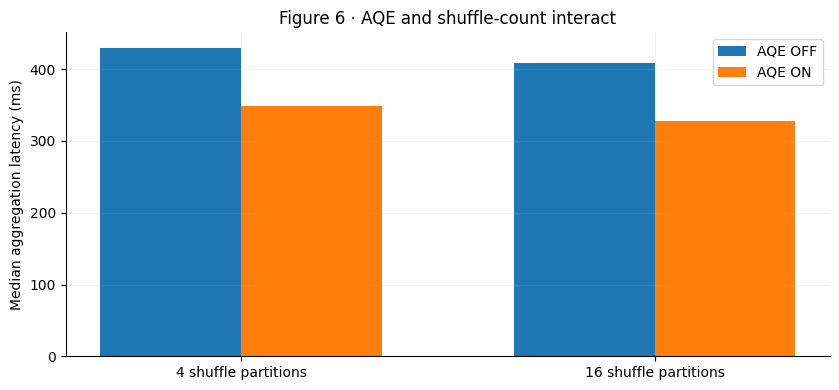

**Interpretation.** Fastest tested configuration: AQE=True, shuffle partitions=16 (327.5 ms). This is local[2] aggregation, **not** a 42-year Spark W1 benchmark.

In [70]:
# Figure 6 — Spark AQE/shuffle factorial performance (only if executed)
if P3_SPARK_READY:
    df=P3_SPARK_TUNING_SUM
    fig,ax=plt.subplots(figsize=(8.5,4));xx=np.arange(2)
    for i,aqe in enumerate([False,True]):
        vals=[float(df.loc[(df.aqe==aqe)&(df.partitions==p),'median_ms'].iloc[0]) for p in [4,16]]
        ax.bar(xx+(.34*i-.17),vals,.34,label=('AQE ON' if aqe else 'AQE OFF'))
    ax.set_xticks(xx,['4 shuffle partitions','16 shuffle partitions'])
    ax.set(ylabel='Median aggregation latency (ms)',title='Figure 6 · AQE and shuffle-count interact')
    ax.legend();plt.tight_layout();plt.show();P3_FIGURES.append('figure_06_spark_tuning')
    best=df.loc[df.median_ms.idxmin()]
    p3_note(f'Fastest tested configuration: AQE={best.aqe}, shuffle partitions={int(best.partitions)} '
       f'({best.median_ms:.1f} ms). This is local[2] aggregation, **not** a 42-year Spark W1 benchmark.')

#### Chart interpretation

**Figure 6 — Interpretation.** A bar difference is meaningful only if each AQE/shuffle configuration produces the same result and the physical plan confirms the intended settings.

In [71]:

# ============================================================
# PHASE 3 | 3.9.4A
# NATIVE SPARK W1 — AQE x SHUFFLE PARTITIONS
# ============================================================

assert P3_SPARK_READY and P3_SPARK_PARITY_PASS

from pyspark.sql import functions as F

P3_ADV_AQE_REPS = 2
P3_ADV_AQE_CONFIGS = [
    (aqe, parts)
    for aqe in (False, True)
    for parts in (4, 16, 32)
]

P3_ADV_AQE_RECORDS = []
P3_ADV_AQE_PLANS = []
P3_ADV_AQE_CHECKSUMS = []

P3_ADV_AQE_EXPECTED = int(
    P3_YEARS.filter(pl.col("year") == 2024)["rows"].sum()
)

# Build a native Spark computation.
# All nine features must contribute to the output.
def p3_adv_w1_checksum_query():

    source = p3_3e_spark_w1_query()
    exprs = [F.count("*").alias("rows")]

    for feature in P3_W1_FEATURES:
        x = F.col(feature).cast("double")
        valid = (
            x.isNotNull()
            & (~F.isnan(x))
            & (F.abs(x) < F.lit(float("inf")))
        )

        exprs.extend([
            F.sum(
                F.when(valid, x).otherwise(0.0)
            ).alias(feature + "__sum"),

            F.sum(
                F.when(x.isNull(), 1).otherwise(0)
            ).alias(feature + "__null")
        ])

    return source.agg(*exprs)


def p3_adv_checksum_equal(left, right):

    for key in left:
        a, b = left[key], right[key]

        if key == "rows" or key.endswith("__null"):
            if a != b:
                return False
        else:
            if not np.isclose(
                float(a), float(b),
                rtol=1e-6, atol=1e-6
            ):
                return False

    return True


old_config = {
    key: spark.conf.get(key)
    for key in [
        "spark.sql.adaptive.enabled",
        "spark.sql.shuffle.partitions"
    ]
}

reference = None

try:
    # Warm-up and physical-plan inspection.
    for aqe, parts in P3_ADV_AQE_CONFIGS:

        spark.conf.set(
            "spark.sql.adaptive.enabled",
            str(aqe).lower()
        )
        spark.conf.set(
            "spark.sql.shuffle.partitions",
            str(parts)
        )

        query = p3_adv_w1_checksum_query()
        metrics = query.collect()[0].asDict()

        assert metrics["rows"] == P3_ADV_AQE_EXPECTED

        if reference is None:
            reference = metrics
        else:
            assert p3_adv_checksum_equal(
                reference, metrics
            ), f"Checksum mismatch: AQE={aqe}, parts={parts}"

        plan = (
            query._jdf.queryExecution()
            .executedPlan().toString()
        )

        P3_ADV_AQE_PLANS.append({
            "aqe": aqe,
            "partitions": parts,
            "adaptive": "AdaptiveSparkPlan" in plan,
            "exchange": "Exchange" in plan,
            "broadcast_join": "BroadcastHashJoin" in plan,
            "sort_merge_join": "SortMergeJoin" in plan,
            "final_aqe": "isFinalPlan=true" in plan
        })

    # Repeated native Spark benchmark.
    for rep in range(1, P3_ADV_AQE_REPS + 1):

        configurations = (
            P3_ADV_AQE_CONFIGS
            if rep % 2
            else list(reversed(P3_ADV_AQE_CONFIGS))
        )

        for aqe, parts in configurations:

            spark.conf.set(
                "spark.sql.adaptive.enabled",
                str(aqe).lower()
            )
            spark.conf.set(
                "spark.sql.shuffle.partitions",
                str(parts)
            )

            gc.collect()
            start = time.perf_counter()

            query = p3_adv_w1_checksum_query()
            metrics = query.collect()[0].asDict()

            elapsed_ms = (
                time.perf_counter() - start
            ) * 1000

            checksum_pass = p3_adv_checksum_equal(
                reference, metrics
            )

            P3_ADV_AQE_RECORDS.append({
                "aqe": aqe,
                "partitions": parts,
                "rep": rep,
                "runtime_ms": elapsed_ms,
                "rows": metrics["rows"],
                "checksum_pass": checksum_pass
            })

            P3_ADV_AQE_CHECKSUMS.append(metrics)

        print(f"Replication {rep} complete")

finally:
    for key, value in old_config.items():
        spark.conf.set(key, value)


Replication 1 complete
Replication 2 complete


##### Run block 2/2 — continuation of original code cell 90

Run sequentially; the original code statements and their order are unchanged.

PASS  3.9 advanced native Spark AQE checksum parity

[1] NATIVE SPARK AQE PERFORMANCE


,aqe,partitions,repetitions,median_ms,min_ms,max_ms,all_checksums_pass
0,False,4,2,1271.48,1268.88,1274.09,True
1,False,16,2,1869.79,1852.29,1887.30,True
2,False,32,2,3040.36,2860.18,3220.54,True
3,True,4,2,1244.23,1227.83,1260.64,True
4,True,16,2,1285.53,1276.00,1295.07,True
5,True,32,2,1354.66,1334.03,1375.30,True



[2] PHYSICAL PLAN MARKERS


,aqe,partitions,adaptive,exchange,broadcast_join,sort_merge_join,final_aqe
0,False,4,False,True,False,True,False
1,False,16,False,True,False,True,False
2,False,32,False,True,False,True,False
3,True,4,True,True,True,True,True
4,True,16,True,True,True,True,True
5,True,32,True,True,True,True,True


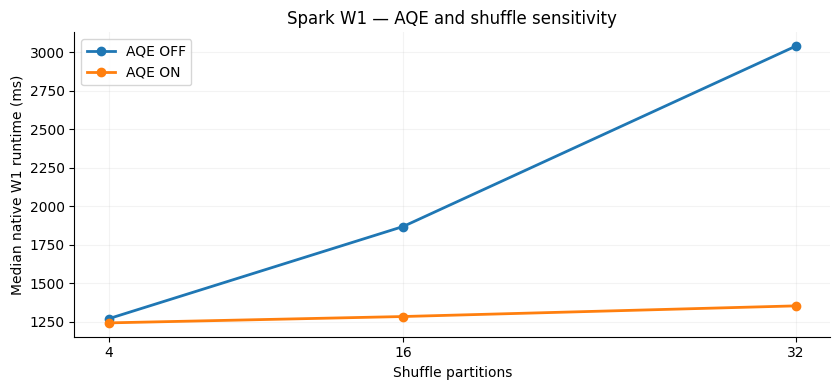

Fastest tested: AQE=True, partitions=4, median=1244.2 ms
Native W1 checksum parity: True
Full-history Spark parity: NOT TESTED


In [72]:

P3_ADV_AQE_RAW = pd.DataFrame(P3_ADV_AQE_RECORDS)
P3_ADV_AQE_PLAN_AUDIT = pd.DataFrame(P3_ADV_AQE_PLANS)

P3_ADV_AQE_SUM = (
    P3_ADV_AQE_RAW
    .groupby(["aqe", "partitions"], as_index=False)
    .agg(
        repetitions=("rep", "count"),
        median_ms=("runtime_ms", "median"),
        min_ms=("runtime_ms", "min"),
        max_ms=("runtime_ms", "max"),
        all_checksums_pass=("checksum_pass", "all")
    )
)

P3_ADV_AQE_PASS = bool(
    len(P3_ADV_AQE_RAW) == 6 * P3_ADV_AQE_REPS
    and P3_ADV_AQE_RAW["checksum_pass"].all()
    and P3_ADV_AQE_RAW["runtime_ms"].gt(0).all()
    and (
        P3_ADV_AQE_PLAN_AUDIT["aqe"]
        == P3_ADV_AQE_PLAN_AUDIT["adaptive"]
    ).all()
)

p3_mark(
    "3.9 advanced native Spark AQE checksum parity",
    P3_ADV_AQE_PASS
)

P3_EXPERIMENTS["spark_native_w1_aqe"] = {
    "status": "PASS",
    "output_year": 2024,
    "features": len(P3_W1_FEATURES),
    "configs": 6,
    "timed_runs": len(P3_ADV_AQE_RAW),
    "full_history_spark_parity": "NOT_TESTED"
}

print("\n[1] NATIVE SPARK AQE PERFORMANCE")
display(P3_ADV_AQE_SUM.round(2))

print("\n[2] PHYSICAL PLAN MARKERS")
display(P3_ADV_AQE_PLAN_AUDIT)

# Figure — AQE and partition sensitivity for W1.
fig, ax = plt.subplots(figsize=(8.5, 4))

for aqe, group in P3_ADV_AQE_SUM.groupby("aqe"):
    group = group.sort_values("partitions")
    ax.plot(
        group["partitions"],
        group["median_ms"],
        marker="o",
        linewidth=2,
        label="AQE ON" if aqe else "AQE OFF"
    )

ax.set(
    xticks=[4, 16, 32],
    xlabel="Shuffle partitions",
    ylabel="Median native W1 runtime (ms)",
    title="Spark W1 — AQE and shuffle sensitivity"
)
ax.legend()
plt.tight_layout()
plt.show()

best = P3_ADV_AQE_SUM.loc[
    P3_ADV_AQE_SUM["median_ms"].idxmin()
]

print(
    f"Fastest tested: AQE={best['aqe']}, "
    f"partitions={int(best['partitions'])}, "
    f"median={best['median_ms']:.1f} ms"
)
print("Native W1 checksum parity:", P3_ADV_AQE_PASS)
print("Full-history Spark parity: NOT TESTED")


In [73]:

# ============================================================
# PHASE 3 | 3.9.5
# SPARK HASH-PARTITION SKEW VS BANK-HISTORY SKEW
# ============================================================

assert P3_SPARK_READY

P3_SPARK_SKEW_EXPECTED = int(P3_KEY_AUDIT["rows"])

# Read only bank identifiers to minimize memory usage.
bank_keys = (
    spark.read.parquet(str(P3_SILVER_PATH))
    .select("CERT")
)

# ------------------------------------------------------------
# 1. Bank-history length distribution
# ------------------------------------------------------------

bank_histories = (
    bank_keys.groupBy("CERT")
    .agg(F.count("*").alias("history_rows"))
)

history_stats = (
    bank_histories.agg(
        F.count("*").alias("banks"),
        F.avg("history_rows").alias("mean"),
        F.expr(
            "percentile_approx(history_rows, 0.5, 10000)"
        ).alias("median"),
        F.max("history_rows").alias("max"),
        F.min("history_rows").alias("min"),
        F.stddev_pop("history_rows").alias("std")
    )
    .first()
    .asDict()
)

history_stats["max_over_median"] = (
    history_stats["max"] / history_stats["median"]
)

history_stats["cv"] = (
    history_stats["std"] / history_stats["mean"]
)

P3_SPARK_BANK_HISTORY_SKEW = pd.DataFrame(
    [history_stats]
)

# ------------------------------------------------------------
# 2. Actual hash-partition row counts
# ------------------------------------------------------------

P3_SPARK_SKEW_RECORDS = []

for n_parts in (8, 32):

    partitioned = (
        bank_keys.repartition(n_parts, "CERT")
        .withColumn(
            "partition_id",
            F.spark_partition_id()
        )
    )

    counts = {
        int(r["partition_id"]): int(r["count"])
        for r in (
            partitioned.groupBy("partition_id")
            .count()
            .collect()
        )
    }

    for partition_id in range(n_parts):
        P3_SPARK_SKEW_RECORDS.append({
            "partitions": n_parts,
            "partition_id": partition_id,
            "rows": counts.get(partition_id, 0)
        })

P3_SPARK_PARTITION_LOAD = pd.DataFrame(
    P3_SPARK_SKEW_RECORDS
)

# ------------------------------------------------------------
# 3. Partition distribution statistics
# ------------------------------------------------------------

summary_rows = []

for parts, group in P3_SPARK_PARTITION_LOAD.groupby(
    "partitions"
):

    values = group["rows"].to_numpy(dtype=float)

    mean = float(np.mean(values))
    median = float(np.median(values))
    std = float(np.std(values, ddof=0))

    summary_rows.append({
        "partitions": int(parts),
        "total_rows": int(values.sum()),
        "mean": mean,
        "median": median,
        "max": int(values.max()),
        "min": int(values.min()),
        "max_over_median": (
            float(values.max() / median)
            if median > 0 else np.nan
        ),
        "cv": std / mean if mean > 0 else np.nan
    })


##### Run block 2/2 — continuation of original code cell 91

Run sequentially; the original code statements and their order are unchanged.

PASS  3.9 Spark partition load reconciles to source
3.9.5 — BANK HISTORY VS SPARK PARTITION SKEW

[1] BANK-HISTORY LENGTH


,banks,mean,median,max,min,std,max_over_median,cv
0,24064,69.923,51,170,1,55.92,3.333,0.8



[2] SPARK HASH-PARTITION DISTRIBUTION


,partitions,total_rows,mean,median,max,min,max_over_median,cv
0,8,1682616,210327.00,209612.0,214983,207819,1.026,0.011
1,32,1682616,52581.75,52554.5,56570,48649,1.076,0.038


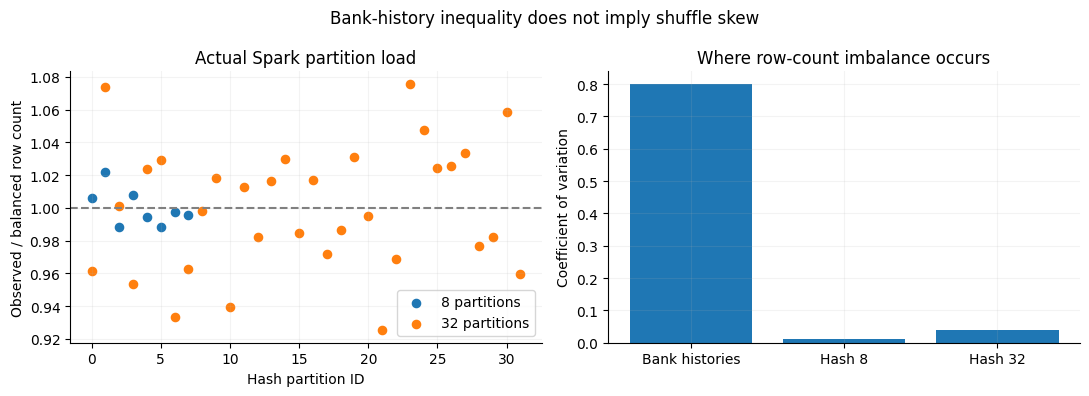


PARTITION SKEW AUDIT PASS: True
Interpretation: Uneven bank-history lengths do not automatically imply uneven hash-partition loads.
Task-duration and shuffle-byte skew: NOT MEASURED


In [74]:

P3_SPARK_PARTITION_SKEW_SUM = pd.DataFrame(
    summary_rows
)

# ------------------------------------------------------------
# 4. Integrity checks
# ------------------------------------------------------------

population_pass = bool(
    P3_SPARK_PARTITION_SKEW_SUM[
        "total_rows"
    ].eq(P3_SPARK_SKEW_EXPECTED).all()
)

partition_pass = bool(
    len(P3_SPARK_PARTITION_LOAD) == 40
    and population_pass
    and P3_SPARK_PARTITION_LOAD["rows"].ge(0).all()
)

p3_mark(
    "3.9 Spark partition load reconciles to source",
    partition_pass
)

# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("=" * 72)
print("3.9.5 — BANK HISTORY VS SPARK PARTITION SKEW")
print("=" * 72)

print("\n[1] BANK-HISTORY LENGTH")
display(P3_SPARK_BANK_HISTORY_SKEW.round(3))

print("\n[2] SPARK HASH-PARTITION DISTRIBUTION")
display(P3_SPARK_PARTITION_SKEW_SUM.round(3))

# ------------------------------------------------------------
# 6. Visualization
# ------------------------------------------------------------

fig, (a, b) = plt.subplots(
    1, 2, figsize=(11, 4)
)

for parts, group in P3_SPARK_PARTITION_LOAD.groupby(
    "partitions"
):

    expected_per_partition = (
        P3_SPARK_SKEW_EXPECTED / parts
    )

    a.scatter(
        group["partition_id"],
        group["rows"] / expected_per_partition,
        label=f"{parts} partitions",
        s=35
    )

a.axhline(1, linestyle="--", color="gray")
a.set(
    xlabel="Hash partition ID",
    ylabel="Observed / balanced row count",
    title="Actual Spark partition load"
)
a.legend()

labels = [
    "Bank histories",
    "Hash 8",
    "Hash 32"
]

cv_values = [
    history_stats["cv"],
    *P3_SPARK_PARTITION_SKEW_SUM
      .sort_values("partitions")["cv"].tolist()
]

b.bar(labels, cv_values)
b.set(
    ylabel="Coefficient of variation",
    title="Where row-count imbalance occurs"
)

plt.suptitle(
    "Bank-history inequality does not imply shuffle skew"
)
plt.tight_layout()
plt.show()

P3_EXPERIMENTS["spark_skew_full_history"] = {
    "status": "PASS",
    "source_rows": P3_SPARK_SKEW_EXPECTED,
    "partition_counts": [8, 32],
    "measure": "row-count imbalance",
    "task_duration_skew": "NOT_MEASURED"
}

print("\nPARTITION SKEW AUDIT PASS:", partition_pass)
print(
    "Interpretation: Uneven bank-history lengths do not "
    "automatically imply uneven hash-partition loads."
)
print(
    "Task-duration and shuffle-byte skew: NOT MEASURED"
)


#### Interpretation — Scope of Spark evidence

The full-history production correctness claim comes from pandas ↔ Polars. Spark tests concern a 2024 W1 pilot and selected 2017–2024 workloads, subject to local JVM availability.

### 3.9.6 — Optional Spark Wide cache/rescan A/B

A separate wide aggregation measures whether materializing a cached source offsets repeated scans. Include materialization cost and validate every tested configuration.

In [75]:

# ============================================================
# PHASE 3 | 3.9.6
# SPARK WIDE ARCHITECTURE A/B — 133 FINANCIAL FIELDS
# ============================================================

assert P3_SPARK_READY

from pyspark import StorageLevel

P3_SPARK_WIDE_FIELDS = list(P3_FINANCIAL_FIELDS)
P3_SPARK_WIDE_BATCH_SIZE = 20
P3_SPARK_WIDE_REPS = 2

assert len(P3_SPARK_WIDE_FIELDS) == 133, (
    f"Expected 133 numeric financial fields; "
    f"found {len(P3_SPARK_WIDE_FIELDS)}. "
    "Check Phase 2 field mapping."
)

P3_SPARK_WIDE_EXPECTED = int(
    P3_YEARS.filter(pl.col("year") == 2024)["rows"].sum()
)

# ------------------------------------------------------------
# 1. Source: 2024 financial fields only
# ------------------------------------------------------------

wide_source = (
    spark.read.parquet(str(P3_SILVER_PATH))
    .filter(
        F.col("REPDTE").between(
            F.lit("2024-01-01").cast("date"),
            F.lit("2024-12-31").cast("date")
        )
    )
    .select("REPDTE", *P3_SPARK_WIDE_FIELDS)
    .withColumn("year", F.year("REPDTE"))
    .drop("REPDTE")
)

# ------------------------------------------------------------
# 2. Six-statistic batch aggregation
# ------------------------------------------------------------

def p3_wide_aggregate_batch(df, fields):

    expressions = [
        F.count("*").alias("n_rows")
    ]

    for j, field in enumerate(fields):

        x = F.col(field).cast("double")

        finite = (
            x.isNotNull()
            & (~F.isnan(x))
            & (F.abs(x) < F.lit(float("inf")))
        )

        expressions.extend([
            F.sum(
                F.when(x.isNull(), 1).otherwise(0)
            ).alias(f"x{j}_null"),

            F.sum(
                F.when(x.isNotNull() & F.isnan(x), 1)
                 .otherwise(0)
            ).alias(f"x{j}_nan"),

            F.avg(
                F.when(finite, x)
            ).alias(f"x{j}_mean"),

            F.sum(
                F.when(finite & (x == 0), 1)
                 .otherwise(0)
            ).alias(f"x{j}_zero"),

            F.sum(
                F.when(finite & (x < 0), 1)
                 .otherwise(0)
            ).alias(f"x{j}_negative")
        ])

    return df.agg(*expressions).first().asDict()


# ------------------------------------------------------------
# 3. Complete architecture run
# ------------------------------------------------------------

def p3_run_wide_architecture(strategy):

    start = time.perf_counter()
    materialization_ms = 0.0

    if strategy == "cached_batches":
        working = wide_source.persist(
            StorageLevel.MEMORY_AND_DISK
        )
    elif strategy == "direct_batches":
        working = wide_source
    else:
        raise ValueError(strategy)

    records = []

    try:
        if strategy == "cached_batches":

            cache_start = time.perf_counter()
            cached_rows = working.count()

            materialization_ms = (
                time.perf_counter() - cache_start
            ) * 1000

            assert cached_rows == P3_SPARK_WIDE_EXPECTED

        for offset in range(
            0,
            len(P3_SPARK_WIDE_FIELDS),
            P3_SPARK_WIDE_BATCH_SIZE
        ):

            fields = P3_SPARK_WIDE_FIELDS[
                offset:offset + P3_SPARK_WIDE_BATCH_SIZE
            ]

            batch_source = working.select(*fields)

            values = p3_wide_aggregate_batch(
                batch_source, fields
            )

            assert values["n_rows"] == P3_SPARK_WIDE_EXPECTED

            for j, field in enumerate(fields):

                mean = values[f"x{j}_mean"]

                records.append({
                    "year": 2024,
                    "field": field,
                    "n_rows": int(values["n_rows"]),
                    "null_count": int(values[f"x{j}_null"]),
                    "nan_count": int(values[f"x{j}_nan"]),
                    "finite_mean": (
                        np.nan if mean is None
                        else float(mean)
                    ),
                    "zero_count": int(values[f"x{j}_zero"]),
                    "negative_count": int(
                        values[f"x{j}_negative"]
                    )
                })

    finally:
        if strategy == "cached_batches":
            working.unpersist(blocking=True)

    total_ms = (
        time.perf_counter() - start
    ) * 1000

    result = (
        pd.DataFrame(records)
        .sort_values(["year", "field"])
        .reset_index(drop=True)
    )

    return result, {
        "strategy": strategy,
        "total_ms": total_ms,
        "materialization_ms": materialization_ms
    }


##### Run block 2/3 — continuation of original code cell 94

Run sequentially; the original code statements and their order are unchanged.

3.9.6 — SPARK WIDE ARCHITECTURE A/B

[1] INITIAL NUMERICAL PARITY
Fields compared: 133
Statistics per field: 6
Cached vs direct parity: PASS
Wide A/B repetition 1 completed
Wide A/B repetition 2 completed
PASS  3.9 Spark Wide architecture numerical parity

[2] ARCHITECTURE PERFORMANCE


,strategy,repetitions,median_total_ms,median_materialization_ms,all_parity_pass
0,cached_batches,2,5597.98,412.18,True
1,direct_batches,2,5390.05,0.00,True


<BarContainer object of 2 artists>

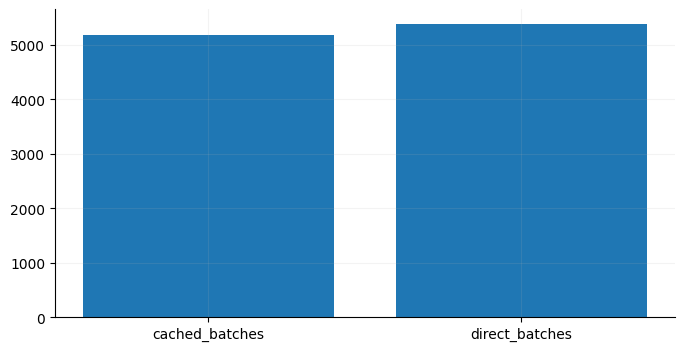

In [76]:


# ------------------------------------------------------------
# 4. Numerical parity before benchmarking
# ------------------------------------------------------------

print("=" * 72)
print("3.9.6 — SPARK WIDE ARCHITECTURE A/B")
print("=" * 72)

reference, _ = p3_run_wide_architecture(
    "direct_batches"
)

cached_reference, _ = p3_run_wide_architecture(
    "cached_batches"
)

pd.testing.assert_frame_equal(
    reference,
    cached_reference,
    check_exact=False,
    rtol=1e-6,
    atol=1e-7
)

assert len(reference) == 133
assert reference["field"].nunique() == 133

print("\n[1] INITIAL NUMERICAL PARITY")
print("Fields compared:", len(reference))
print("Statistics per field: 6")
print("Cached vs direct parity: PASS")

# ------------------------------------------------------------
# 5. Repeated full-cost experiments
# ------------------------------------------------------------

P3_SPARK_WIDE_AB_RECORDS = []

for rep in range(1, P3_SPARK_WIDE_REPS + 1):

    order = (
        ["direct_batches", "cached_batches"]
        if rep % 2
        else ["cached_batches", "direct_batches"]
    )

    for strategy in order:

        gc.collect()

        result, timing = p3_run_wide_architecture(
            strategy
        )

        pd.testing.assert_frame_equal(
            reference,
            result,
            check_exact=False,
            rtol=1e-6,
            atol=1e-7
        )

        P3_SPARK_WIDE_AB_RECORDS.append({
            "strategy": strategy,
            "rep": rep,
            "total_ms": timing["total_ms"],
            "materialization_ms": timing[
                "materialization_ms"
            ],
            "parity_pass": True
        })

    print(f"Wide A/B repetition {rep} completed")

P3_SPARK_WIDE_AB = pd.DataFrame(
    P3_SPARK_WIDE_AB_RECORDS
)

P3_SPARK_WIDE_SUM = (
    P3_SPARK_WIDE_AB
    .groupby("strategy", as_index=False)
    .agg(
        repetitions=("rep", "count"),
        median_total_ms=("total_ms", "median"),
        median_materialization_ms=(
            "materialization_ms", "median"
        ),
        all_parity_pass=("parity_pass", "all")
    )
)

P3_SPARK_WIDE_PASS = bool(
    len(P3_SPARK_WIDE_AB) == 4
    and len(reference) == 133
    and P3_SPARK_WIDE_AB["parity_pass"].all()
    and P3_SPARK_WIDE_AB["total_ms"].gt(0).all()
)

p3_mark(
    "3.9 Spark Wide architecture numerical parity",
    P3_SPARK_WIDE_PASS
)

# ------------------------------------------------------------
# 6. Results and visualization
# ------------------------------------------------------------

print("\n[2] ARCHITECTURE PERFORMANCE")
display(P3_SPARK_WIDE_SUM.round(2))

fig, ax = plt.subplots(figsize=(8, 4))

summary = P3_SPARK_WIDE_SUM

aggregation_ms = (
    summary["median_total_ms"]
    - summary["median_materialization_ms"]
)

ax.bar(
    summary["strategy"],
    aggregation_ms,
    label="Aggregation + teardown"
)


##### Run block 3/3 — continuation of original code cell 94

Run sequentially; the original code statements and their order are unchanged.

In [77]:

ax.bar(
    summary["strategy"],
    summary["median_materialization_ms"],
    bottom=aggregation_ms,
    label="Cache materialization"
)

ax.set(
    ylabel="Median end-to-end runtime (ms)",
    title="Spark Wide — cache once vs. direct batch scans"
)

ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Engineering decision
# ------------------------------------------------------------

winner = P3_SPARK_WIDE_SUM.loc[
    P3_SPARK_WIDE_SUM["median_total_ms"].idxmin()
]

P3_EXPERIMENTS["spark_wide_architecture"] = {
    "status": "PASS",
    "fields": len(reference),
    "statistics_per_field": 6,
    "repetitions_per_strategy": P3_SPARK_WIDE_REPS,
    "winner": str(winner["strategy"]),
    "cache_build_included": True,
    "full_history_wide_benchmark": "NOT_TESTED"
}

print("\n[3] ENGINEERING DECISION")
print("Fastest observed strategy:", winner["strategy"])
print(
    "Median elapsed time:",
    round(float(winner["median_total_ms"]), 2), "ms"
)
print("All 133 fields numerically equivalent: YES")
print("Cache build and teardown included: YES")
print("Source files modified: NO")


<Figure size 900x420 with 0 Axes>


[3] ENGINEERING DECISION
Fastest observed strategy: direct_batches
Median elapsed time: 5390.05 ms
All 133 fields numerically equivalent: YES
Cache build and teardown included: YES
Source files modified: NO


In [78]:
# 3.9.7 — Release local Spark JVM before production while preserving audited gates
P3_SPARK_EXPERIMENTS_EXECUTED=bool(P3_SPARK_READY)
if P3_SPARK_READY and P3_CFG.get('release_spark_before_production',True):
    spark.stop()
    gc.collect()
    P3_SPARK_READY=False
    P3_EXPERIMENTS['spark']['session_released_before_production']=True
    print('Spark session released. Previously verified Spark acceptance gates remain recorded.')
elif P3_SPARK_READY:
    P3_EXPERIMENTS['spark']['session_released_before_production']=False
    print('Spark session retained by user policy.')
else:
    print('No active Spark session to release.')

Spark session released. Previously verified Spark acceptance gates remain recorded.


<a id="p3-10"></a>
## 3.10 — Scaling and deployment economics

Distinguish measured local workload scaling from hypothetical cluster speedups. Report both row-history length and number of financial columns.

In [79]:
# 3.10.1 — Row scaling: complete bank histories, not randomized bank-quarter rows
bank_ids=(src.select('CERT').unique().sort('CERT').collect()['CERT'].to_list())
P3_ROW_SCALE=[]
for label,step in [('25% banks',4),('50% banks',2),('100% banks',1)]:
    cohort=bank_ids[::step]
    subset=src.filter(pl.col('CERT').is_in(cohort))
    t0=time.perf_counter();frame=p3_collect(p3_w1_window(1985,2026,source=subset))
    P3_ROW_SCALE.append({'fraction':label,'banks':len(cohort),'output_rows':frame.height,
                         'runtime_ms':(time.perf_counter()-t0)*1000})
    del frame,subset,cohort;gc.collect()
P3_ROW_SCALE=pd.DataFrame(P3_ROW_SCALE)
p3_mark('3.10 complete-bank row scaling integrity',len(P3_ROW_SCALE)==3 and
        P3_ROW_SCALE['output_rows'].is_monotonic_increasing and
        int(P3_ROW_SCALE.iloc[-1]['output_rows'])==P3_EXPECTED_PRODUCTION_ROWS)
print('Row scaling measured for 25%, 50% and 100% of bank histories.')

PASS  3.10 complete-bank row scaling integrity
Row scaling measured for 25%, 50% and 100% of bank histories.


In [80]:
# 3.10.2 — Column scaling: same 1984–2026 annual finite-count workload
sizes=sorted(set([min(9,P3_WIDE_FIELD_COUNT),min(40,P3_WIDE_FIELD_COUNT),
                  min(80,P3_WIDE_FIELD_COUNT),P3_WIDE_FIELD_COUNT]))
P3_COLUMN_SCALE=[]
for width in sizes:
    fields=P3_FINANCIAL_FIELDS[:width]
    qry=(src.group_by(pl.col('REPDTE').dt.year().alias('year'))
         .agg([pl.col(f).is_finite().sum().alias(f) for f in fields]))
    t0=time.perf_counter();out=qry.collect(engine='streaming')
    P3_COLUMN_SCALE.append({'columns':width,'annual_rows':out.height,
                            'runtime_ms':(time.perf_counter()-t0)*1000})
    del out;gc.collect()
P3_COLUMN_SCALE=pd.DataFrame(P3_COLUMN_SCALE)
p3_mark('3.10 annual column-scaling integrity',len(P3_COLUMN_SCALE)>=2 and
        P3_COLUMN_SCALE['annual_rows'].eq(43).all())

PASS  3.10 annual column-scaling integrity


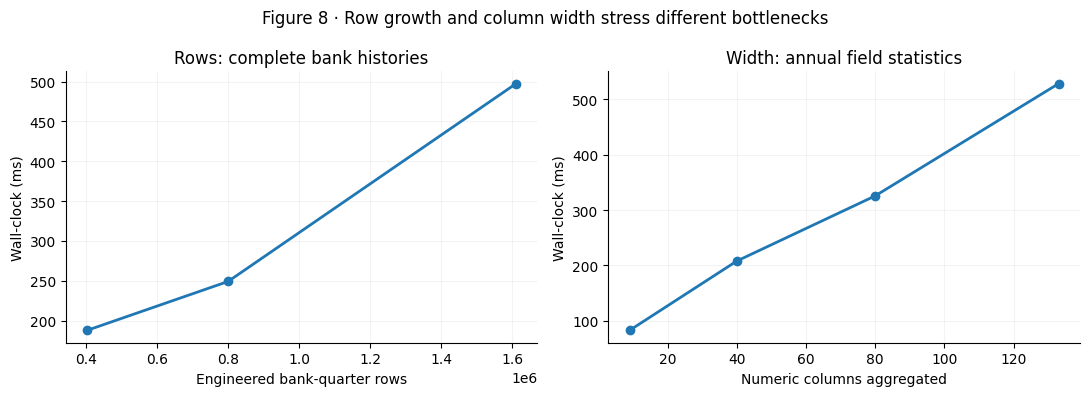

**Interpretation.** Row scaling increases the number of bank histories requiring time-window calculations, while column-width scaling increases projection and aggregation costs. These are distinct experiments and should not be combined into one throughput claim.

In [81]:

# Figure 8 — Row scaling vs. column-width scaling

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))

# A. Row scaling
row_data = P3_ROW_SCALE.sort_values("output_rows")

a.plot(
    row_data["output_rows"],
    row_data["runtime_ms"],
    "o-",
    linewidth=2
)
a.set(
    xlabel="Engineered bank-quarter rows",
    ylabel="Wall-clock (ms)",
    title="Rows: complete bank histories"
)

# B. Column-width scaling
column_data = P3_COLUMN_SCALE.sort_values("columns")

b.plot(
    column_data["columns"],
    column_data["runtime_ms"],
    "o-",
    linewidth=2
)
b.set(
    xlabel="Numeric columns aggregated",
    ylabel="Wall-clock (ms)",
    title="Width: annual field statistics"
)

for ax in (a, b):
    ax.grid(alpha=0.15)

plt.suptitle(
    "Figure 8 · Row growth and column width stress different bottlenecks"
)

plt.tight_layout()
plt.show()

if "figure_08_scaling_two_axes" not in P3_FIGURES:
    P3_FIGURES.append("figure_08_scaling_two_axes")

p3_note(
    "Row scaling increases the number of bank histories requiring "
    "time-window calculations, while column-width scaling increases "
    "projection and aggregation costs. These are distinct experiments "
    "and should not be combined into one throughput claim."
)


#### Chart interpretation

**Figure 8 — Interpretation.** Bank-history row scaling and wider field projections stress different bottlenecks; they should not be interpreted as equivalent ways of increasing data size.

In [82]:

# 3.10.3 — Amdahl scenarios using measured 42Y runtime

P3_AMDAHL_ARCHIVAL40_SEC = 0.4522524

p3_42_window = P3_BENCH_SUM.query(
    'horizon == 42 and engine == "calendar_window"'
)

assert len(p3_42_window) == 1
assert bool(p3_42_window.iloc[0]['correct'])

P3_AMDAHL_LOCAL42_SEC = (
    float(p3_42_window.iloc[0]['median_ms']) / 1000
)

assert P3_AMDAHL_LOCAL42_SEC > 0

P3_AMDAHL = []

for f in (0.80, 0.95):

    for workers in (2, 4, 8):

        speed = 1 / ((1 - f) + f / workers)

        comp = P3_AMDAHL_LOCAL42_SEC / speed

        for overhead in (0.5, 2.0, 5.0):

            gain = P3_AMDAHL_LOCAL42_SEC - comp

            P3_AMDAHL.append({
                'parallel_fraction_ASSUMED': f,
                'workers': workers,
                'fixed_overhead_s_ASSUMED': overhead,
                'compute_s_THEORETICAL': comp,
                'single_run_s_THEORETICAL': overhead + comp,
                'single_run_faster': (
                    overhead + comp < P3_AMDAHL_LOCAL42_SEC
                ),
                'reuses_to_break_even': (
                    math.floor(overhead / gain) + 1
                    if gain > 0 else np.nan
                )
            })

P3_AMDAHL_TABLE = pd.DataFrame(P3_AMDAHL)

p3_mark(
    '3.10 Amdahl scenario integrity',
    len(P3_AMDAHL_TABLE) == 18
    and P3_AMDAHL_TABLE[
        'reuses_to_break_even'
    ].notna().all()
)

print(
    f'Current local 42Y W1 median: '
    f'{P3_AMDAHL_LOCAL42_SEC * 1000:.2f} ms'
)

print(
    f'Archival 40Y: '
    f'{P3_AMDAHL_ARCHIVAL40_SEC * 1000:.2f} ms'
)

print(
    'Illustrative single-run scenarios beating local:',
    int(P3_AMDAHL_TABLE.single_run_faster.sum()),
    '/18'
)


PASS  3.10 Amdahl scenario integrity
Current local 42Y W1 median: 622.76 ms
Archival 40Y: 452.25 ms
Illustrative single-run scenarios beating local: 1 /18


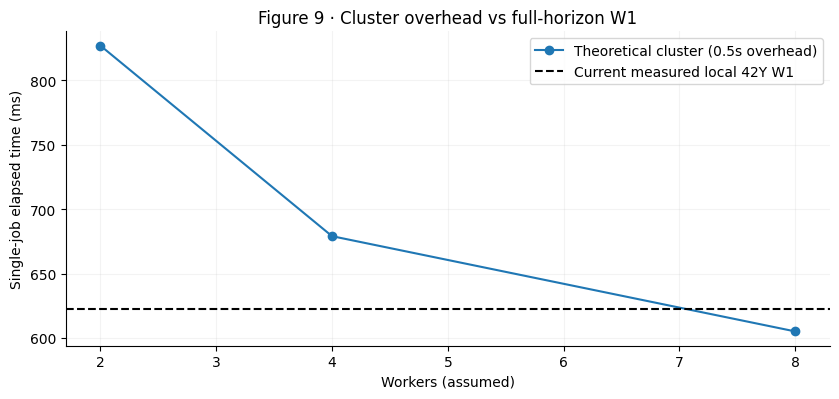

**Interpretation.** For the current 42-year W1 job, all cluster scenarios are theoretical and anchored to the locally measured 42-year median. No distributed cluster or monetary cost was measured. The archival 40Y measurement is retained separately.

In [83]:

# Figure 9 — Amdahl vs current local 42Y runtime

sub = P3_AMDAHL_TABLE.query(
    'parallel_fraction_ASSUMED == 0.95 '
    'and fixed_overhead_s_ASSUMED == 0.5'
)

fig, ax = plt.subplots(figsize=(8.5, 4.1))

ax.plot(
    sub.workers,
    sub.single_run_s_THEORETICAL * 1000,
    'o-',
    label='Theoretical cluster (0.5s overhead)'
)

ax.axhline(
    P3_AMDAHL_LOCAL42_SEC * 1000,
    linestyle='--',
    color='black',
    label='Current measured local 42Y W1'
)

ax.set(
    xlabel='Workers (assumed)',
    ylabel='Single-job elapsed time (ms)',
    title='Figure 9 · Cluster overhead vs full-horizon W1'
)

ax.legend()
plt.tight_layout()
plt.show()

if 'figure_09_amdahl' not in P3_FIGURES:
    P3_FIGURES.append('figure_09_amdahl')

p3_note(
    'For the current 42-year W1 job, all cluster scenarios '
    'are theoretical and anchored to the locally measured '
    '42-year median. No distributed cluster or monetary '
    'cost was measured. The archival 40Y measurement '
    'is retained separately.'
)


#### Chart interpretation

**Figure 9 — Interpretation.** The Amdahl curve is a scenario under assumed parallel fractions and overhead, not a measured distributed speedup. Compare it to the actual local baseline before recommending a cluster.

In [84]:
# 3.10.4 — LOWMEM build-once/read-many Parquet economics (scenario, NOT measured cost)
if P3_CFG['run_storage']:
    base=P3_STORAGE_SCAN_SUM.query('layout=="snappy_50k"').set_index('workload')['median_ms']
    zstd=P3_STORAGE_SCAN_SUM.query('layout=="zstd_50k"').set_index('workload')['median_ms']
    rows=[]
    for q in base.index:
        saving_ms=float(base.loc[q]-zstd.loc[q])
        for hypothetical_setup in (1,10,60):
            breakeven=(math.floor(hypothetical_setup*1000/saving_ms)+1
                       if saving_ms>0 else None)
            rows.append({'workload':q,'hypothetical_setup_s':hypothetical_setup,
                         'measured_saved_ms_per_query':saving_ms,
                         'queries_to_amortize':breakeven})
    P3_STORAGE_BREAK_EVEN=pd.DataFrame(rows)
    display(P3_STORAGE_BREAK_EVEN)
    p3_note('Break-even counts are only meaningful if the chosen alternative is actually faster and the setup cost is shared across queries. ZSTD may save disk while *losing* scan time; then time-only amortization is impossible.')

,workload,hypothetical_setup_s,measured_saved_ms_per_query,queries_to_amortize
0,full_1993_2024,1,-8.6053,None
1,full_1993_2024,10,-8.6053,None
2,full_1993_2024,60,-8.6053,None
3,year_2024,1,-2.7685,None
4,year_2024,10,-2.7685,None
5,year_2024,60,-2.7685,None


**Interpretation.** Break-even counts are only meaningful if the chosen alternative is actually faster and the setup cost is shared across queries. ZSTD may save disk while *losing* scan time; then time-only amortization is impossible.

#### Interpretation — Local processing versus distributed systems

For a single local batch, Spark setup costs may exceed savings. Concurrency, larger data or deployment SLA could justify a cluster, but those conditions are not directly measured by Amdahl scenarios.

### 3.10.5 — Optional fresh-process CPU study

Polars worker count is fixed at startup. This optional experiment starts separate processes and measures a simple count workload—not complete W1.

In [85]:
# 3.10.5 — Optional thread-count sweep with new Python processes
if P3_CFG['run_cpu_process_lab']:
    import subprocess,sys
    script="""import time,polars as pl,sys
path=sys.argv[1];start=time.perf_counter()
r=pl.scan_parquet(path).group_by(pl.col('REPDTE').dt.year()).agg(pl.len()).collect()
print(f'{(time.perf_counter()-start)*1000:.6f}|{r.height}')
"""
    output=[]
    for threads in (1,2,4):
        env=os.environ.copy();env['POLARS_MAX_THREADS']=str(threads)
        t=time.perf_counter()
        child=subprocess.run([sys.executable,'-c',script,str(P3_SILVER_PATH)],
                   capture_output=True,text=True,env=env,timeout=120)
        if child.returncode:
            raise RuntimeError(child.stderr[-500:])
        metric,annual=child.stdout.strip().splitlines()[-1].split('|')
        output.append({'threads':threads,'child_annual_rows':int(annual),
                       'child_query_ms':float(metric),'process_end_to_end_ms':(time.perf_counter()-t)*1000})
    P3_THREAD_LAB=pd.DataFrame(output)
    assert P3_THREAD_LAB.child_annual_rows.eq(43).all()
    P3_EXPERIMENTS['cpu_fresh_process']={'status':'PASS','workload':'annual count only'}
    display(P3_THREAD_LAB.round(2))
else:
    P3_EXPERIMENTS['cpu_fresh_process']={'status':'SKIPPED_BY_POLICY'}
P3_EXPERIMENTS['concurrent_workload']={'status':'SKIPPED_RESOURCE_POLICY',
 'why':'Concurrent Polars+Spark stress cannot be safely generalized from a constrained local Windows laptop'}
print('Concurrent stress not executed: no fabricated latency/throughput claim.')

Concurrent stress not executed: no fabricated latency/throughput claim.


<a id="p3-11"></a>
## 3.11 — Full-history production and Phase 4 release

Write nine W1 financial features (1985Q1–2026Q2), verify SHA/keys/schema and then **bind the separate Phase 2 V3 labels and temporal split policy**. Phase 4 receives both files and joins only on `(CERT, REPDTE)`.

In [86]:
# 3.11.1 — Pre-build gates, full-range count and output paths
required_gates=[
 '3.1 canonical SHA-256','3.1 source row/column contract','3.1 Silver manifest SHA-256',
 '3.1 ordered P0 → Silver field lineage','3.1 Phase 1 linked SHA-256',
 '3.1 Phase 0 contract SHA-256','3.1 Bronze 43-of-43 local file hashes',
 '3.1 financial source excludes exact outcome labels',
 '3.2 key uniqueness and completeness','3.2 complete financial source horizon',
 '3.2 source annual population','3.2 W1 raw inputs available','3.2 non-empty bank histories',
 '3.3 nine distinct features and six ratios','3.5 full financial history independent parity',
 '3.5 2025–2026Q2 extension validated',
 '3.6 repeated runtime and sampled RSS','3.7 optimizer A/B numerical parity',
 '3.7 metamorphic temporal invariants','3.7 adversarial financial tests',
 '3.10 complete-bank row scaling integrity','3.10 annual column-scaling integrity',
 '3.10 Amdahl scenario integrity']
if P3_CFG['run_optional_wide']:
    required_gates += ['3.4 full-source Wide W2 annual profiling']
if P3_CFG.get('run_date_clustered',False) and P3_CFG['run_storage']:
    required_gates += ['3.8 date-clustered 32Y exact parity']
if P3_CFG['run_storage']:
    required_gates += ['3.8 32-year physical row counts and logical schemas',
      '3.8 exact 32-year W1 + full-field 2024 fidelity','3.8 repeated 24 scan executions']
if (
    P3_CFG['run_storage']
    and P3_CFG.get('run_storage_full_history', False)
):
    required_gates += [
        '3.8 full 1984–2026Q2 storage codec fidelity'
    ]
if P3_3E_SESSION_WAS_READY:
    required_gates += ['3.6 2024 three-engine W1 parity','3.6 three-engine E2E benchmark']
if P3_CFG.get('run_csv_parquet_ab',True):
    required_gates += ['3.8 CSV–Parquet 2024 value fidelity',
                       '3.8 CSV–Parquet controlled scans']
if P3_SPARK_EXPERIMENTS_EXECUTED:
    required_gates += ['3.9 2024 Spark W1 numerical parity','3.9 Spark AQE/shuffle controlled executions',
                       '3.9 Spark cached/uncached repeated actions','3.9 Spark partition load reconciles to source']
missing=[k for k in required_gates if not P3_GATES.get(k,False)]
if missing: raise AssertionError('Mandatory/current-configured tests missing or failed: '+str(missing))
P3_PRODUCTION_DIR=P3_RUN_DIR/'production';P3_PRODUCTION_DIR.mkdir(exist_ok=True)
P3_PRODUCTION_W1_PATH=P3_PRODUCTION_DIR/'w1_financial_features_1985Q1_2026Q2.parquet'
P3_PRODUCTION_MANIFEST_PATH=P3_PRODUCTION_DIR/'production_manifest.json'
P3_PHASE4_HANDOFF_PATH=P3_PRODUCTION_DIR/'phase3_to_phase4_handoff.json'
P3_OUTPUT_FIELDS=['CERT','REPDTE']+P3_W1_FEATURES
print('Expected production rows from annual source audit:',P3_EXPECTED_PRODUCTION_ROWS)
print('Latest financial quarter:',P3_CFG['financial_last'])
print('Production destination:',P3_PRODUCTION_W1_PATH)

Expected production rows from annual source audit: 1610856
Latest financial quarter: 2026-06-30
Production destination: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\w1_financial_features_1985Q1_2026Q2.parquet


In [87]:
# 3.11.1B — Prevent a V3-unlinked Phase 4 release.
required_gates.extend([
    '3.1 Phase 2 V3 label SHA and full-population contract',
    '3.1 Phase 2 V3 split and maturity contract'])
assert all(P3_GATES.get(k,False) for k in required_gates), 'Phase 2 V3 link or earlier gate is missing'
print('V3 label / temporal-split prerequisites included in Phase 4 acceptance gates.')


V3 label / temporal-split prerequisites included in Phase 4 acceptance gates.


In [88]:
# 3.11.2 — Full-history optimized production write (1985Q1 to 2026Q2)
# Use disabled post-window predicate pushdown when supported to preserve historical lookback.
import inspect
query=p3_w1_window(1985,2026).select(P3_OUTPUT_FIELDS)
t0=time.perf_counter()
if 'optimizations' in inspect.signature(pl.LazyFrame.sink_parquet).parameters:
    query.sink_parquet(str(P3_PRODUCTION_W1_PATH),compression='zstd',
                       row_group_size=50000,optimizations=P3_NO_PUSHDOWN)
else:
    # Compatibility fallback: 11-column materialization only (NOT full 141-column Silver).
    final_small=p3_collect(query)
    final_small.write_parquet(str(P3_PRODUCTION_W1_PATH),compression='zstd',row_group_size=50000)
    del final_small
P3_PRODUCTION_BUILD_SEC=time.perf_counter()-t0
del query;gc.collect()
P3_OUT_META=pq.read_metadata(str(P3_PRODUCTION_W1_PATH))
p3_mark('3.11 physical full-source production population',
        P3_OUT_META.num_rows==P3_EXPECTED_PRODUCTION_ROWS and P3_OUT_META.num_columns==11)
print('Build + Parquet write:',round(P3_PRODUCTION_BUILD_SEC,3),'s | File:',
      round(P3_PRODUCTION_W1_PATH.stat().st_size/2**20,2),'MiB |',
      P3_OUT_META.num_row_groups,'row groups')

PASS  3.11 physical full-source production population
Build + Parquet write: 0.712 s | File: 101.68 MiB | 33 row groups


In [89]:

# ============================================================
# PHASE 3 | SECTION 3.11.3
# FINAL PRODUCTION DATA INTEGRITY AUDIT
# Scope: 1985Q1–2026Q2
# ============================================================

print("=" * 72)
print("3.11.3 — PRODUCTION DATA INTEGRITY AUDIT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Load production output
# ------------------------------------------------------------

out_lf = pl.scan_parquet(
    str(P3_PRODUCTION_W1_PATH)
)

# ------------------------------------------------------------
# 2. Key integrity and date coverage
# ------------------------------------------------------------

out_stats = (
    out_lf
    .select(
        pl.len().alias("rows"),
        pl.struct(["CERT", "REPDTE"])
          .n_unique()
          .alias("unique"),
        pl.col("REPDTE").min().alias("first"),
        pl.col("REPDTE").max().alias("last"),
        pl.col("CERT").null_count().alias("null_bank"),
        pl.col("REPDTE").null_count().alias("null_date")
    )
    .collect(engine="streaming")
    .to_dicts()[0]
)

key_ok = bool(
    out_stats["rows"] == P3_EXPECTED_PRODUCTION_ROWS
    and out_stats["unique"] == out_stats["rows"]
    and out_stats["null_bank"] == 0
    and out_stats["null_date"] == 0
    and out_stats["first"] == P3_CFG["production_first"]
    and out_stats["last"] == P3_CFG["financial_last"]
)

print("\n[1] KEY & DATE INTEGRITY")
print("Rows:", out_stats["rows"])
print("Unique bank-quarter keys:", out_stats["unique"])
print("Date range:", out_stats["first"], "→", out_stats["last"])
print("Key integrity PASS:", key_ok)

# ------------------------------------------------------------
# 3. Annual population reconciliation
# ------------------------------------------------------------

actual_year = (
    out_lf
    .group_by(
        pl.col("REPDTE").dt.year().alias("year")
    )
    .agg(pl.len().alias("rows"))
    .collect(engine="streaming")
    .sort("year")
)

expected_year = (
    P3_YEARS
    .filter(pl.col("year") >= 1985)
    .select("year", "rows")
    .sort("year")
)

year_audit = (
    expected_year
    .join(
        actual_year.rename({"rows": "actual_rows"}),
        on="year",
        how="full",
        coalesce=True
    )
    .with_columns(
        (
            pl.col("actual_rows") - pl.col("rows")
        ).alias("difference")
    )
    .sort("year")
)

annual_ok = bool(
    year_audit.height == expected_year.height
    and year_audit["difference"].null_count() == 0
    and year_audit["difference"].eq(0).all()
)

print("\n[2] ANNUAL POPULATION")
print("Years verified:", year_audit.height)
print("Annual coverage PASS:", annual_ok)

if not annual_ok:
    display(
        year_audit.filter(
            pl.col("difference").is_null()
            | (pl.col("difference") != 0)
        )
    )

# ------------------------------------------------------------
# 4. Null patterns and infinite values
# ------------------------------------------------------------

P3_OUT_NULLS = (
    out_lf
    .select([
        pl.col(f).null_count().alias(f)
        for f in P3_W1_FEATURES
    ])
    .collect(engine="streaming")
    .to_dicts()[0]
)


3.11.3 — PRODUCTION DATA INTEGRITY AUDIT

[1] KEY & DATE INTEGRITY
Rows: 1610856
Unique bank-quarter keys: 1610856
Date range: 1985-03-31 → 2026-06-30
Key integrity PASS: True

[2] ANNUAL POPULATION
Years verified: 42
Annual coverage PASS: True


##### Run block 2/2 — continuation of original code cell 109

Run sequentially; the original code statements and their order are unchanged.

In [90]:

P3_OUT_INFS = (
    out_lf
    .select([
        pl.col(f)
        .is_infinite()
        .fill_null(False)
        .sum()
        .alias(f)
        for f in P3_W1_FEATURES
    ])
    .collect(engine="streaming")
    .to_dicts()[0]
)

parity_nulls = dict(
    zip(
        P3_PARITY_REPORT["feature"],
        P3_PARITY_REPORT["both_null"]
    )
)

feature_audit = pd.DataFrame([
    {
        "feature": f,
        "production_nulls": int(P3_OUT_NULLS[f]),
        "parity_nulls": int(parity_nulls[f]),
        "infinite_values": int(P3_OUT_INFS[f]),
        "null_match": (
            int(P3_OUT_NULLS[f])
            == int(parity_nulls[f])
        )
    }
    for f in P3_W1_FEATURES
])

null_ok = bool(feature_audit["null_match"].all())
finite_ok = bool(
    feature_audit["infinite_values"].eq(0).all()
)

print("\n[3] FEATURE INTEGRITY")
display(feature_audit)

print("Null-pattern reconciliation PASS:", null_ok)
print("No infinite values PASS:", finite_ok)

# ------------------------------------------------------------
# 5. Historical vs. newly added observations
# ------------------------------------------------------------

P3_2024_ROWS = int(
    actual_year
    .filter(pl.col("year") <= 2024)
    ["rows"].sum()
)

P3_NEW_ROWS = int(
    actual_year
    .filter(pl.col("year") >= 2025)
    ["rows"].sum()
)

legacy_ok = P3_2024_ROWS == 1_584_297

new_period_expected = int(
    P3_YEARS
    .filter(pl.col("year") >= 2025)
    ["rows"].sum()
)

new_period_ok = (
    P3_NEW_ROWS == new_period_expected
)

print("\n[4] HISTORICAL COVERAGE")
print("1985–2024:", P3_2024_ROWS)
print("2025–2026Q2:", P3_NEW_ROWS)
print("Expected new observations:", new_period_expected)
print("Legacy population PASS:", legacy_ok)
print("New period population PASS:", new_period_ok)

# ------------------------------------------------------------
# 6. Final acceptance
# ------------------------------------------------------------

P3_PRODUCTION_INTEGRITY_PASS = bool(
    key_ok
    and annual_ok
    and null_ok
    and finite_ok
    and legacy_ok
    and new_period_ok
)

p3_mark(
    "3.11 complete 1985Q1–2026Q2 integrity",
    P3_PRODUCTION_INTEGRITY_PASS
)

print("\n[5] FINAL ACCEPTANCE")
print(
    "PRODUCTION INTEGRITY PASS:",
    P3_PRODUCTION_INTEGRITY_PASS
)



[3] FEATURE INTEGRITY


,feature,production_nulls,parity_nulls,infinite_values,null_match
0,equity_to_assets,4033,4033,0,True
1,deposits_to_assets,1,1,0,True
2,cash_to_assets,1,1,0,True
3,securities_to_assets,1,1,0,True
4,core_deposit_share,13164,13164,0,True
5,noncurrent_loan_ratio,20126,20126,0,True
6,asset_growth_4q,23101,23101,0,True
7,roa_rolling_mean_4q,17398,17398,0,True
8,roa_rolling_std_4q,17398,17398,0,True


Null-pattern reconciliation PASS: True
No infinite values PASS: True

[4] HISTORICAL COVERAGE
1985–2024: 1584297
2025–2026Q2: 26559
Expected new observations: 26559
Legacy population PASS: True
New period population PASS: True
PASS  3.11 complete 1985Q1–2026Q2 integrity

[5] FINAL ACCEPTANCE
PRODUCTION INTEGRITY PASS: True


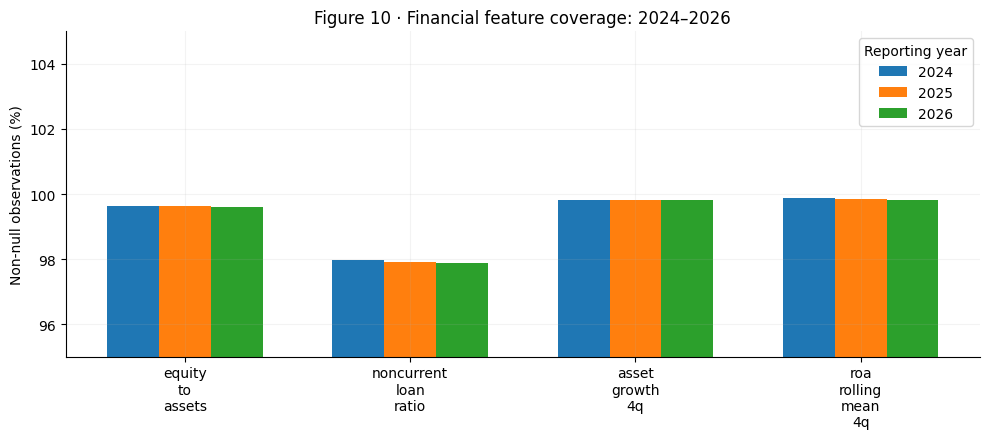


ANNUAL FEATURE COVERAGE (%)


,year,n,equity_to_assets,noncurrent_loan_ratio,asset_growth_4q,roa_rolling_mean_4q
0,2024,18399,99.63,97.98,99.82,99.88
1,2025,17893,99.62,97.92,99.81,99.86
2,2026,8666,99.61,97.88,99.82,99.83


**Interpretation.** Coverage in 2026 represents Q1–Q2 only. Non-null availability does not establish financial semantic validity or model eligibility.

In [91]:

# ============================================================
# PHASE 3 | FIGURE 10 — FINANCIAL FEATURE COVERAGE
# Compare 2024, 2025 and 2026 (Q1–Q2)
# ============================================================

# 1. Read production output
out_lf = pl.scan_parquet(str(P3_PRODUCTION_W1_PATH))

# 2. Select representative W1 features
selected = [
    "equity_to_assets",
    "noncurrent_loan_ratio",
    "asset_growth_4q",
    "roa_rolling_mean_4q"
]

years = [2024, 2025, 2026]

# 3. Calculate actual annual non-null coverage
coverage = (
    out_lf
    .filter(pl.col("REPDTE").dt.year().is_in(years))
    .group_by(pl.col("REPDTE").dt.year().alias("year"))
    .agg(
        pl.len().alias("n"),
        *[
            (
                100 * pl.col(f).is_not_null().sum()
                / pl.len()
            ).alias(f)
            for f in selected
        ]
    )
    .collect(engine="streaming")
    .sort("year")
)

assert coverage["year"].to_list() == years, (
    "Missing reporting years in production output."
)

rates = [
    [
        float(coverage.filter(pl.col("year") == y)[f][0])
        for f in selected
    ]
    for y in years
]

# 4. Plot
fig, ax = plt.subplots(figsize=(10, 4.5))

x = np.arange(len(selected))
bw = 0.23

for i, year in enumerate(years):
    ax.bar(
        x + (i - 1) * bw,
        rates[i],
        bw,
        label=str(year)
    )

ax.set_xticks(
    x,
    [f.replace("_", "\n") for f in selected]
)

ax.set_ylim(95, 105)
ax.set_ylabel("Non-null observations (%)")
ax.set_title(
    "Figure 10 · Financial feature coverage: 2024–2026"
)
ax.legend(title="Reporting year")
ax.grid(axis="y", alpha=0.15)

plt.tight_layout()
plt.show()

# 5. Register figure
if "figure_10_extension_feature_availability" not in P3_FIGURES:
    P3_FIGURES.append(
        "figure_10_extension_feature_availability"
    )

print("\nANNUAL FEATURE COVERAGE (%)")
display(coverage.to_pandas().round(2))

p3_note(
    "Coverage in 2026 represents Q1–Q2 only. "
    "Non-null availability does not establish financial "
    "semantic validity or model eligibility."
)


#### Chart interpretation

**Figure 10 — Interpretation.** High non-null feature coverage through 2026Q2 does not mean complete four-quarter outcome observability. These two clocks are audited separately in Figure 2B.

In [92]:
# 3.11.4 — Output fingerprint, physical codec and optional Wide artifact
P3_PRODUCTION_W1_SHA=p3_sha256(P3_PRODUCTION_W1_PATH)
codecs={P3_OUT_META.row_group(i).column(j).compression.upper()
   for i in range(P3_OUT_META.num_row_groups) for j in range(P3_OUT_META.num_columns)}
p3_mark('3.11 ZSTD physical codec',codecs=={'ZSTD'})
p3_mark('3.11 immutable source hash unchanged',p3_sha256(P3_SILVER_PATH)==P3_SOURCE_SHA)
P3_WIDE_OUTPUT_PATH=None
if P3_CFG['run_optional_wide'] and 'P3_WIDE_ANNUAL' in globals():
    P3_WIDE_OUTPUT_PATH=P3_PRODUCTION_DIR/'w2_full_history_year_field_stats.parquet'
    pl.from_pandas(P3_WIDE_ANNUAL).write_parquet(P3_WIDE_OUTPUT_PATH,compression='zstd')
    assert pq.read_metadata(str(P3_WIDE_OUTPUT_PATH)).num_rows==len(P3_WIDE_ANNUAL)
print('W1 SHA-256:',P3_PRODUCTION_W1_SHA)
print('W2 annual statistics:',P3_WIDE_OUTPUT_PATH if P3_WIDE_OUTPUT_PATH else 'NOT CREATED')

PASS  3.11 ZSTD physical codec
PASS  3.11 immutable source hash unchanged
W1 SHA-256: 0e105a4a1727324086a95c74775252cb4e6a8c4bcda94b18769fe8e9ae7905e3
W2 annual statistics: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\w2_full_history_year_field_stats.parquet


In [93]:
# 3.11.5 — Production manifest: separate measured, assumed and provisional claims
P3_PRODUCTION_MANIFEST={
 'phase':3,'version':'5.0-full-financial-horizon',
 'run_id':P3_RUN_ID,'created_at_utc':datetime.now(timezone.utc).isoformat(),
 'upstream_artifacts':{'phase0_field_handoff_sha256':p3_sha256(P3_P0_FIELD_PATH),
   'phase0_scope_sha256':p3_sha256(P3_PROJECT_ROOT/'docs/phase0_data_scope_contract.json'),
   'phase1_handoff_path':str(P3_PHASE1_HANDOFF_PATH),
   'phase1_handoff_sha256':p3_sha256(P3_PHASE1_HANDOFF_PATH),
   'bronze_annual_sha256_verified':sum(x['sha_pass'] for x in P3_BRONZE_FILE_AUDIT),
   'fdic_remote_api_page_sha256':'NOT_INDEPENDENTLY_VERIFIED'},
 'canonical_silver':{'path':str(P3_SILVER_PATH),'sha256':P3_SOURCE_SHA,
                      'first_quarter':'1984Q1','last_quarter':'2026Q2','rows':int(P3_META.num_rows)},
 'production_w1':{'path':str(P3_PRODUCTION_W1_PATH),'sha256':P3_PRODUCTION_W1_SHA,
      'first_quarter':'1985Q1','last_quarter':'2026Q2','rows':int(out_stats['rows']),
      'columns':P3_OUTPUT_FIELDS,'row_groups':P3_OUT_META.num_row_groups,
      'compression':'ZSTD','size_mib':P3_PRODUCTION_W1_PATH.stat().st_size/2**20,
      'build_seconds_current_run':P3_PRODUCTION_BUILD_SEC},
 'production_w2':({'path':str(P3_WIDE_OUTPUT_PATH),'sha256':p3_sha256(P3_WIDE_OUTPUT_PATH)}
                  if P3_WIDE_OUTPUT_PATH else None),
 'financial_contract':{'ratio_rules':P3_W1_RATIO_RULES,'temporal_rules':P3_W1_RULES,
                        'noncurrent_loan_ratio_status':'PROVISIONAL_FIELD_SEMANTICS'},
 'validation':{'full_history_independent_pandas_polars':True,
               'matched_bank_quarters':int(P3_EXPECTED_PRODUCTION_ROWS),
               'features':len(P3_W1_FEATURES),'mismatch_count':0,
               'Spark_full_history_parity':'NOT_TESTED'},
 'advanced_experiments':P3_EXPERIMENTS,
 'gates_current_run':{k:bool(v) for k,v in P3_GATES.items()},
 'limitations':['NCLNLS/LNLSGR semantic comparability provisional',
    'Publication-vintage timestamps not established for all source quarters',
    'No full-history Spark W1 parity','No measured distributed cluster',
    'RSS sampled, not precise 40/42-year process-tree peak'],
 'phase4_modeling_boundary':{'financial_source_ends':'2026Q2',
    'label_observability_candidate_ends':'2025Q2',
    'label_cutoff_status':'MUST_REVERIFY_AGAINST_PHASE2_LABEL_CONTRACT',
    'labels_joined_in_phase3':False}}
P3_PRODUCTION_MANIFEST_PATH.write_text(json.dumps(P3_PRODUCTION_MANIFEST,indent=2,
         ensure_ascii=False,default=str),encoding='utf-8')
print('Manifest:',P3_PRODUCTION_MANIFEST_PATH)

Manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\production_manifest.json


In [94]:
# 3.11.5B — Phase 2 V3 contract supplement to the existing production manifest
# Appended after the original manifest cell, before its independent re-read.
P3_PRODUCTION_MANIFEST['phase2_v3_contract']={
    'manifest_path':str(P3_V3_HANDOFF_PATH),
    'manifest_sha256':p3_sha256(P3_V3_HANDOFF_PATH),
    'label_path':str(P3_V3_LABEL_PATH),
    'label_sha256':P3_V3_HANDOFF['label_sha256'],
    'label_column':P3_V3_HANDOFF['label_column'],
    'eligibility_column':P3_V3_HANDOFF['eligibility_column'],
    'robustness_column':P3_V3_HANDOFF['robustness_column'],
    'last_eligible_quarter':P3_V3_ELIGIBLE_LAST_QUARTER,
    'split_windows':P3_V3_HANDOFF['split_windows'],
    'expanding_cv_windows':P3_V3_HANDOFF['expanding_cv_windows'],
    'forbidden_predictors':P3_V3_HANDOFF['forbidden_predictors'],
    'original_training_start':'1984Q1',
    'financial_w1_start':'1985Q1',
    'modeling_join_key':['CERT','REPDTE'],
    'no_label_columns_in_w1':True}
P3_PRODUCTION_MANIFEST['phase4_modeling_boundary'].update({
    'label_observability_candidate_ends':P3_V3_ELIGIBLE_LAST_QUARTER,
    'label_cutoff_status':'SHA_VERIFIED_PHASE2_V3_ELIGIBILITY',
    'modeling_split_status':'FIXED_FROM_PHASE2_V3',
    'labels_joined_in_phase3':False})
P3_PRODUCTION_MANIFEST_PATH.write_text(json.dumps(
    P3_PRODUCTION_MANIFEST,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
assert json.loads(P3_PRODUCTION_MANIFEST_PATH.read_text(encoding='utf-8'))['phase2_v3_contract']['label_sha256']==P3_V3_HANDOFF['label_sha256']
print('W1 production manifest enriched with source-verified V3 label and split contract.')


W1 production manifest enriched with source-verified V3 label and split contract.


In [95]:
# 3.11.6 — Independent re-read of output and manifest, then Phase 4 handoff
manifest=json.loads(P3_PRODUCTION_MANIFEST_PATH.read_text(encoding='utf-8'))
release_pass=(manifest['production_w1']['sha256']==p3_sha256(P3_PRODUCTION_W1_PATH)
 and manifest['canonical_silver']['sha256']==p3_sha256(P3_SILVER_PATH)
 and pq.read_metadata(str(P3_PRODUCTION_W1_PATH)).num_rows==P3_EXPECTED_PRODUCTION_ROWS
 and manifest['production_w1']['last_quarter']=='2026Q2'
 and all(P3_GATES.get(g,False) for g in required_gates))
p3_mark('3.11 manifest/output reload integrity',release_pass)
P3_PHASE4_HANDOFF={
 'phase':'PHASE3','version':'5.0','status':'ACCEPTED_WITH_DECLARED_LIMITATIONS',
 'completed_utc':datetime.now(timezone.utc).isoformat(),
 'run_id':P3_RUN_ID,'manifest':str(P3_PRODUCTION_MANIFEST_PATH),
 'manifest_sha256':p3_sha256(P3_PRODUCTION_MANIFEST_PATH),
 'w1_path':str(P3_PRODUCTION_W1_PATH),'w1_sha256':P3_PRODUCTION_W1_SHA,
 'w1_rows':int(out_stats['rows']),'historical_verified_to':'2026Q2',
 'baseline_1985_2024_rows':P3_2024_ROWS,
 'new_2025_2026Q2_rows':P3_NEW_ROWS,
 'w1_fields':P3_OUTPUT_FIELDS,'w2_path':str(P3_WIDE_OUTPUT_PATH) if P3_WIDE_OUTPUT_PATH else None,
 'no_failure_labels_in_features':True,
 'phase4_required_checks':[
  'Read Phase 2 confirmed failure registry and unresolved/competing-exit evidence',
  'Define label horizon and forecast-origin eligibility independently of financial coverage',
  'Verify label eligibility ceiling (candidate 2025Q2) and actual publication lag',
  'Perform chronological split and prevent bank/event/time leakage',
  'Keep 2025Q3–2026Q2 features as potentially unlabeled scoring observations',
  'Sensitivity test provisional noncurrent_loan_ratio versus published NCLNLSR if available',
  'Preserve missingness and investigate reporting-regime drift before imputation',
  'Audit unique failed CERT counts in test set, not just positive rows'],
 'semantic_provisional_fields':['noncurrent_loan_ratio'],
 'spark_full_history_parity':'NOT_TESTED',
 'source_silver_sha256':P3_SOURCE_SHA,
 'current_run_gates':P3_GATES}
P3_PHASE4_HANDOFF_PATH.write_text(json.dumps(P3_PHASE4_HANDOFF,indent=2,
      ensure_ascii=False,default=str),encoding='utf-8')
reloaded=json.loads(P3_PHASE4_HANDOFF_PATH.read_text(encoding='utf-8'))
p3_mark('3.11 Phase 4 handoff reload',reloaded['w1_sha256']==P3_PRODUCTION_W1_SHA and
        reloaded['historical_verified_to']=='2026Q2')
P3_FINAL_ACCEPTED=all(P3_GATES.get(g,False) for g in required_gates)
print('REVISED PHASE 3 ACCEPTANCE:',P3_FINAL_ACCEPTED)
print('W1:',P3_PRODUCTION_W1_PATH)
print('Manifest:',P3_PRODUCTION_MANIFEST_PATH)
print('Phase 4 handoff:',P3_PHASE4_HANDOFF_PATH)

PASS  3.11 manifest/output reload integrity
PASS  3.11 Phase 4 handoff reload
REVISED PHASE 3 ACCEPTANCE: True
W1: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\w1_financial_features_1985Q1_2026Q2.parquet
Manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\production_manifest.json
Phase 4 handoff: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\phase3_to_phase4_handoff.json


### 3.11.7 — Phase 2 V3 to Phase 4 join audit

**Key reconciliation:** W1 starts in 1985Q1; Phase 2 labels start in 1984Q1. Verify a one-to-one `(CERT, REPDTE)` match for every engineered W1 row, document the 1984 lookback exclusion, and export the authoritative V3-aware Phase 4 handoff.

In [96]:
# 3.11.7 — FINAL PHASE 4 JOIN AUDIT AND V3-ALIGNED HANDOFF
# Audit only. Labels never enter the W1 feature file; join after W1 is built.
assert P3_FINAL_ACCEPTED, 'Existing Phase 3 release gates must pass first.'
assert p3_sha256(P3_PRODUCTION_W1_PATH)==P3_PRODUCTION_W1_SHA
assert p3_sha256(P3_V3_LABEL_PATH)==P3_V3_HANDOFF['label_sha256']
_p3_w1=pl.scan_parquet(str(P3_PRODUCTION_W1_PATH)).with_columns(pl.col('REPDTE').cast(pl.Date))
_p3_y=P3_V3_LABEL_LF.select(
    'CERT','REPDTE','y_failure_4q_v3','MODEL_ELIGIBLE_V3',
    'ROBUSTNESS_ELIGIBLE_V3','TEMPORAL_SPLIT_V3'
).with_columns(pl.col('REPDTE').cast(pl.Date))
P3_V3_JOINED_LF=_p3_w1.join(_p3_y,on=['CERT','REPDTE'],how='left',validate='1:1')
_p3_join_audit=P3_V3_JOINED_LF.select(
    pl.len().alias('w1_rows'),
    pl.col('TEMPORAL_SPLIT_V3').is_null().sum().alias('unmatched_label_rows'),
    pl.col('MODEL_ELIGIBLE_V3').fill_null(False).sum().alias('eligible_matched'),
    (pl.col('MODEL_ELIGIBLE_V3').fill_null(False) &
      pl.col('y_failure_4q_v3').eq(1).fill_null(False)).sum().alias('positive_matched')
).collect()
P3_V3_JOIN_AUDIT={k:int(_p3_join_audit[k][0]) for k in _p3_join_audit.columns}
assert P3_V3_JOIN_AUDIT['w1_rows']==int(out_stats['rows'])
assert P3_V3_JOIN_AUDIT['unmatched_label_rows']==0, 'Missing Phase 2 V3 labels for W1 rows'
P3_V3_JOIN_SPLITS=(P3_V3_JOINED_LF
    .filter(pl.col('MODEL_ELIGIBLE_V3').fill_null(False))
    .group_by('TEMPORAL_SPLIT_V3')
    .agg(pl.len().alias('eligible_bank_quarters'),
         pl.col('y_failure_4q_v3').eq(1).fill_null(False).sum().alias('positive_bank_quarters'),
         pl.col('CERT').filter(pl.col('y_failure_4q_v3').eq(1).fill_null(False)).n_unique().alias('positive_banks'),
         pl.col('ROBUSTNESS_ELIGIBLE_V3').fill_null(False).sum().alias('robustness_eligible'))
    .sort('TEMPORAL_SPLIT_V3').collect().to_pandas())
assert P3_V3_JOIN_SPLITS.eligible_bank_quarters.sum()==P3_V3_JOIN_AUDIT['eligible_matched']
assert P3_V3_JOIN_SPLITS.positive_bank_quarters.sum()==P3_V3_JOIN_AUDIT['positive_matched']
# 1984 has no engineered W1; retain Phase 2 policy and audit intersection instead.
P3_V3_EXCLUDED_1984=(P3_V3_LABEL_LF
    .filter(pl.col('REPDTE').cast(pl.Date).dt.year()==1984)
    .select(pl.len().alias('rows'),
            pl.col('MODEL_ELIGIBLE_V3').fill_null(False).sum().alias('eligible'),
            (pl.col('MODEL_ELIGIBLE_V3').fill_null(False)&
             pl.col('y_failure_4q_v3').eq(1).fill_null(False)).sum().alias('eligible_y1'))
    .collect().to_dicts()[0])
print('========== PHASE 2 V3 → PHASE 3 W1 JOIN ==========',P3_V3_JOIN_AUDIT)
print('1984 (lookback-only, not W1 modeling rows):',P3_V3_EXCLUDED_1984)
display(P3_V3_JOIN_SPLITS)
# Export *metadata only*. No joined labels are used in feature construction.
P3_PHASE4_HANDOFF['phase2_v3_contract']=P3_PRODUCTION_MANIFEST['phase2_v3_contract']
P3_PHASE4_HANDOFF['phase4_modeling_boundary']={
    'feature_file':str(P3_PRODUCTION_W1_PATH),
    'feature_sha256':P3_PRODUCTION_W1_SHA,
    'target_file':str(P3_V3_LABEL_PATH),
    'target_sha256':P3_V3_HANDOFF['label_sha256'],
    'join_keys':['CERT','REPDTE'],
    'target_column':'y_failure_4q_v3',
    'eligibility_column':'MODEL_ELIGIBLE_V3',
    'robustness_column':'ROBUSTNESS_ELIGIBLE_V3',
    'last_eligible_quarter':P3_V3_ELIGIBLE_LAST_QUARTER,
    'no_train_on_gap_or_test':True,
    'split_windows':P3_V3_HANDOFF['split_windows'],
    'expanding_cv_windows':P3_V3_HANDOFF['expanding_cv_windows'],
    'excluded_1984_lookback':P3_V3_EXCLUDED_1984,
    'matched_counts':P3_V3_JOIN_AUDIT,
    'eligible_counts_by_split':P3_V3_JOIN_SPLITS.to_dict(orient='records')}
P3_PHASE4_HANDOFF['phase4_required_checks']=[
    'Read the V3 target file and W1 features separately; join only on (CERT, REPDTE)',
    'Filter MODEL_ELIGIBLE_V3 and exclude 2007, 2013, crisis test and recent OOT from fitting',
    'Train 1985–2006 W1 intersection; preserve Phase 2 expanding CV with 1984 lookback limitation',
    'Keep 2008–2012 crisis test and 2014–2025 OOT untouched until final evaluation',
    'Fit imputation, scaling, feature selection and class rebalancing on each training fold only',
    'Use ROBUSTNESS_ELIGIBLE_V3 for a second sensitivity analysis excluding flagged administrative exits',
    'Exclude all forbidden predictor fields, outcome event metadata and future audit columns',
    'Verify publication lag/vintage and period-specific financial-field comparability',
    'Report distinct failed CERT alongside repeated positive bank-quarter observations']
P3_PHASE4_HANDOFF['status']='ACCEPTED_WITH_LIMITATIONS_AND_PHASE2_V3_LINKAGE'
p3_mark('3.11 V3 label-feature join and Phase 4 handoff contract',True)
P3_PHASE4_HANDOFF['current_run_gates']=dict(P3_GATES)
# The existing handoff is brought up to date; a V3-named counterpart is the canonical link.
P3_PHASE4_HANDOFF_PATH.write_text(json.dumps(
    P3_PHASE4_HANDOFF,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
P3_PHASE4_V3_HANDOFF_PATH=P3_PRODUCTION_DIR/'phase3_to_phase4_handoff_v3.json'
P3_PHASE4_V3_HANDOFF_PATH.write_text(json.dumps(
    P3_PHASE4_HANDOFF,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
assert json.loads(P3_PHASE4_V3_HANDOFF_PATH.read_text(encoding='utf-8'))['phase2_v3_contract']['label_sha256']==P3_V3_HANDOFF['label_sha256']
print('AUTHORITATIVE PHASE 4 V3 HANDOFF:',P3_PHASE4_V3_HANDOFF_PATH)
print('W1 is still financial-only, and upstream Silver/V3 files are unchanged.')
# Công bố lần chạy Phase 3 đã qua kiểm tra cho Phase 4.
p3_root = P3_PROJECT_ROOT.resolve()
p3_manifest = P3_PRODUCTION_MANIFEST_PATH.resolve()

p3_pointer = (
    p3_root / "outputs" / "phase3_refined" / "latest_phase4_handoff.json"
)
p3_pointer_payload = {
    "production_manifest": p3_manifest.relative_to(p3_root).as_posix(),
    "production_manifest_sha256": p3_sha256(p3_manifest),
}

# Ghi file tạm trước để Phase 4 chỉ đọc được bản đầy đủ.
p3_pointer_tmp = p3_pointer.with_suffix(".json.tmp")
p3_pointer_tmp.write_text(
    json.dumps(p3_pointer_payload, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
p3_pointer_tmp.replace(p3_pointer)

print("Phase 4 sẽ dùng manifest:", p3_manifest)


========== PHASE 2 V3 → PHASE 3 W1 JOIN ========== {'w1_rows': 1610856, 'unmatched_label_rows': 0, 'eligible_matched': 1596553, 'positive_matched': 10425}
1984 (lookback-only, not W1 modeling rows): {'rows': 71760, 'eligible': 71740, 'eligible_y1': 427}


,TEMPORAL_SPLIT_V3,eligible_bank_quarters,positive_bank_quarters,positive_banks,robustness_eligible
0,CRISIS_TEST,157851,1880,487,157457
1,PURGE_1,34754,48,27,34630
2,PURGE_2,27989,79,38,27848
3,RECENT_OOT,254058,179,55,251933
4,TRAIN_FULL,1121901,8239,2197,1117530


PASS  3.11 V3 label-feature join and Phase 4 handoff contract
AUTHORITATIVE PHASE 4 V3 HANDOFF: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\phase3_to_phase4_handoff_v3.json
W1 is still financial-only, and upstream Silver/V3 files are unchanged.
Phase 4 sẽ dùng manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\production_manifest.json


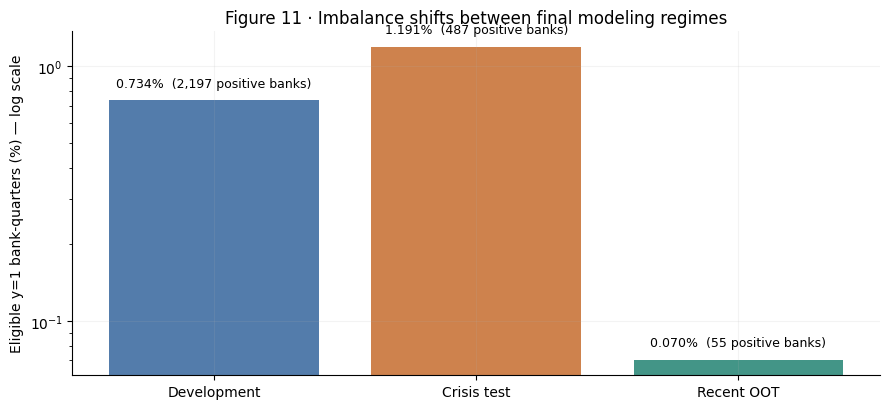

**Interpretation.** The log scale reveals why a single threshold or an overall accuracy number is misleading. Development, crisis and recent OOT have distinct positive-label prevalence; tune within expanding CV and report each untouched test separately.

In [97]:
# Figure 11 — Matched V3 positive-label base rates across held-out regimes
# Visualization of the audited Phase 4 cohort table, not a duplicate table.
_p3_plot=P3_V3_JOIN_SPLITS.set_index('TEMPORAL_SPLIT_V3')
_p3_names=['TRAIN_FULL','CRISIS_TEST','RECENT_OOT']
_p3_display=['Development','Crisis test','Recent OOT']
assert set(_p3_names).issubset(_p3_plot.index)
_p3_rates=[100*_p3_plot.loc[s,'positive_bank_quarters']/_p3_plot.loc[s,'eligible_bank_quarters'] for s in _p3_names]
fig,ax=plt.subplots(figsize=(9,4.2))
_bars=ax.bar(_p3_display,_p3_rates,color=['#537CAB','#CE824D','#439587'])
ax.set(yscale='log',ylabel='Eligible y=1 bank-quarters (%) — log scale',
       title='Figure 11 · Imbalance shifts between final modeling regimes')
for _bar,_rate,_s in zip(_bars,_p3_rates,_p3_names):
    ax.text(_bar.get_x()+_bar.get_width()/2,_rate*1.1,
            f'{_rate:.3f}%  ({int(_p3_plot.loc[_s,"positive_banks"]):,} positive banks)',
            ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.show()
if 'figure_11_label_rate_by_holdout_regime' not in P3_FIGURES:
    P3_FIGURES.append('figure_11_label_rate_by_holdout_regime')
p3_note('The log scale reveals why a single threshold or an overall accuracy number is misleading. '
        'Development, crisis and recent OOT have distinct positive-label prevalence; '
        'tune within expanding CV and report each untouched test separately.')


<a id="p3-final"></a>
## Phase 3 conclusion — Ready for Phase 4

**Verified in Phase 3 after local execution:** financial-only W1 features across 1985Q1–2026Q2, independent pandas/Polars parity, source and output SHA-256 checks, and the separate Phase 2 V3 label contract. Archived experiment outputs remain previous-run evidence until rerun.

**Alignment decision:** Phase 2 V3 supplies the binary 4Q failure outcome, `MODEL_ELIGIBLE_V3`, the 7,514-case robustness filter, and fixed chronological regimes. The 1984 feature burn-in means Phase 4 must recalculate training counts after the `(CERT, REPDTE)` intersection; financial data through 2026Q2 does **not** imply labels mature through 2026Q2.

**Processing decision:** Keep calendar-correct Polars W1 and ZSTD Parquet, with `noncurrent_loan_ratio` provisional. Full-history Spark parity, feature publication vintages, statistical imputation and model performance are **not certified here**.

**Phase 4 handoff:** Use the verified `phase3_to_phase4_handoff_v3.json` and the two SHA-pinned artifacts (W1 features and V3 labels). Apply train-only imputation/feature selection and expanding-window CV; do not tune on 2008–2012 crisis test or 2014–2025 OOT test. The last executable cell reports the actual joined cohort counts and remaining limitations.